In [10]:
%load_ext autoreload
%autoreload 2

In [11]:
import pandas as pd
import numpy as np
import io
import re
import networkx as nx
from math import prod

from io import StringIO
from itertools import product, combinations, permutations
from scipy.stats import pearsonr

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from matplotlib import pyplot as plt
from matplotlib import rcParams
import seaborn as sns

import logging

In [12]:
from utils.countryconverter import convert_country_df
from utils.geomapper import plot_lisa_map
from utils.utils import load_csv_files_from_folder, significance_stars
from utils.df_processing import pairwise_deltas, pairwise_deltas, get_value_diff
from analysis.regression import compute_deltas, regression_analysis, build_monadic_features, build_neighbor_features, ols_inference, summary_table
from analysis.regression import run_singular_regression, benjamini_hochberg
from data_handling import rta, interventions, energy

In [13]:
logger = logging.getLogger()
#logger.setLevel(logging.DEBUG)
logger.setLevel(logging.INFO)

In [14]:
POWER_DATA_DIR = "../data/raw/power/"
BASIC_PROCESSED_POWER_DATA_DIR = "../data/basic_preprocessed/power/"

PREDICTORS_DATA_DIR = "../data/raw/predictors/"
BASIC_PROCESSED_PREDICTORS_DATA_DIR = "../data/basic_preprocessed/predictors/"

RES_PATH = '../output/country/'

In [15]:
def preprocess_df(df, cat, df_type='power', export_csv=True, print_convertions=False):
    logging.info(f"Processing {cat}")
    # renaming columns
    df.rename({v: k for k, v in td[cat].items()}, axis=1, inplace=True)
    if cat in TYPOS:  # removing typos in country names
        df = df.replace(TYPOS[cat])
    if 'year' in df.columns:
        # converting year column
        df['year']=df['year'].astype(int)
        # removing unwanted years before load-heavy operations
        df=df[df['year']>=YEAR_START[df_type]]
        df=df[df['year']<=YEAR_END[df_type]]
    # removing excessive columns
    df = df.filter(expected_keys)
    # renaming countries
    if 'country' in df.columns:  # monadic, mostly in power
        df = convert_country_df(df, 'country', numeric_type=NUMERIC_TYPES[cat], print_convertions=print_convertions, purge=True)
    elif 'country_a' in df.columns:  # dyadic, mostly in predictors
        df = convert_country_df(df, 'country_a', numeric_type=NUMERIC_TYPES[cat], print_convertions=print_convertions, purge=True)
        df = convert_country_df(df, 'country_b', numeric_type=NUMERIC_TYPES[cat], print_convertions=print_convertions, purge=True)
        # clearing selfloop nonsense
        df=df[df['country_a']!=df['country_b']]
        
    # dropping none-s
    if cat in MISSING_VALUES:
        for mv in MISSING_VALUES[cat]:
            df['value']=df['value'].replace(mv, np.nan)
    if 'country' in df.columns:
        df=df.dropna(subset=['value', 'country'])
    elif 'country_a' in df.columns:
        df=df.dropna(subset=['value', 'country_a', 'country_b'])
    df['value']=df['value'].astype(float)

    if cat in REVERSING_VALUE_REQUIRED:
        df['value']=(df['value'].max() - df['value'])

    # dropping duiplicates
    df=df.drop_duplicates()
    
    # ranking
    if cat in RANKING_REQUIRED:
        groupby_columns = ['year']
        if 'indicator' in df.columns:
            groupby_columns += 'indicator',
        df['rank']=df.groupby(groupby_columns)['value'].rank(ascending=False, method='average')
    if export_csv:
        export_folder = BASIC_PROCESSED_POWER_DATA_DIR if df_type=='power' else BASIC_PROCESSED_PREDICTORS_DATA_DIR
        logging.info(f"Saving f'{export_folder}{cat}.csv'")
        df.to_csv(f'{export_folder}{cat}.csv', index=False)
    return df

# Data load

### Loading already preprocessed

In [16]:
power_dfs = load_csv_files_from_folder(BASIC_PROCESSED_POWER_DATA_DIR)
predictor_dfs = load_csv_files_from_folder(BASIC_PROCESSED_PREDICTORS_DATA_DIR)

### Post-preprocess additional dfs

In [17]:
gdp = power_dfs['gdp']
power_dfs['gdp_nominal'] = gdp[gdp['indicator']=='GDP (constant 2015 US$)']
power_dfs['gdp_ppp'] = gdp[gdp['indicator']=='GDP, PPP (constant 2021 international $)']
nominal = power_dfs['gdp_nominal'].merge(gdp[gdp['indicator']=='GDP per capita (constant 2015 US$)'], on = ['country', 'year'], suffixes = ('_nominal','_percapita'))
nominal['value'] = nominal['value_nominal'] * nominal['value_percapita']
ppp = power_dfs['gdp_ppp'].merge(gdp[gdp['indicator']=='GDP per capita, PPP (constant 2021 international $)'], on = ['country', 'year'], suffixes = ('_ppp','_percapita'))
ppp['value'] = ppp['value_ppp'] * ppp['value_percapita']
power_dfs['gdp_beckley'] = nominal[['country','year','value']]
power_dfs['gdp_beckley_ppp'] = ppp[['country','year','value']]
power_dfs['gdp_beckley'].to_csv(f'{BASIC_PROCESSED_POWER_DATA_DIR}gdp_beckley.csv', index=False)
power_dfs['gdp_beckley_ppp'].to_csv(f'{BASIC_PROCESSED_POWER_DATA_DIR}gdp_beckley_ppp.csv', index=False)

In [18]:
# Getting gdp_per_capita_diff_data
_df = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP per capita, PPP (constant 2021 international $)'].drop(['indicator'],axis=1)
predictor_dfs['devdiff'] = get_value_diff(_df)

In [19]:
predictor_dfs['netdiff'] = get_value_diff(power_dfs['net'])

In [20]:
predictor_dfs['combined'] = predictor_dfs['geodistance'].merge(predictor_dfs['netdiff'], on=['country_a', 'country_b'], how='right')
predictor_dfs['combined']['value'] = predictor_dfs['combined']['value_x'] * predictor_dfs['combined']['value_y']
#predictor_dfs['combined']['value'] = predictor_dfs['geodistance']['value'] * (predictor_dfs['ipd']['value'])# * predictor_dfs['netdiff']['value']# * (predictor_dfs['ipd']['value'].apply(lambda x: 1/x))

In [21]:
predictor_dfs['energy'] = predictor_dfs['energy_exp'].merge(predictor_dfs['energy_imp'], on=['country','year'], how='outer', suffixes=('_exp','_imp')).fillna(0)
predictor_dfs['energy'] = predictor_dfs['energy'].merge(power_dfs['gdp_nominal'], on=['country','year'])
predictor_dfs['energy']['surplus'] = predictor_dfs['energy']['value_exp'] - predictor_dfs['energy']['value_imp']
predictor_dfs['energy']['exp_share'] = predictor_dfs['energy']['value_exp']/predictor_dfs['energy']['value']
predictor_dfs['energy']['imp_share'] = predictor_dfs['energy']['value_imp']/predictor_dfs['energy']['value']
predictor_dfs['energy']['surplus_share'] = predictor_dfs['energy']['surplus']/predictor_dfs['energy']['value']
predictor_dfs['energy'].loc[
    predictor_dfs['energy']['surplus_share'] > 1,
    'surplus_share'
] = 1
predictor_dfs['energy'].loc[
    predictor_dfs['energy']['surplus_share'] < -1,
    'surplus_share'
] = -1
predictor_dfs['energy'] = predictor_dfs['energy'].rename({'surplus_share':'value','value':'gdp_nominal'}, axis=1)

In [22]:
_df=(predictor_dfs['human_net']
    .merge(predictor_dfs['security_net'], on=['country_a','country_b','year'], suffixes=('_human','_security'))
    .merge(predictor_dfs['economy_net'], on=['country_a','country_b','year'], suffixes=('','_economy'))
    .rename({'value':'value_economy'}, axis=1)
)
predictor_dfs['net_combined']=_df.copy()
# Бонферрони p=q=1
predictor_dfs['net_combined']['value'] = 1 / np.sqrt(
    (_df.value_human * _df.value_security +
     _df.value_human * _df.value_economy +
     _df.value_security * _df.value_economy) / 3
)


# Analysis

In [23]:
import matplotlib.pyplot as plt
import numpy as np

def plot_power_metrics(
    country: str,
    metrics: dict,
    ignore: list = None,
    figsize=(14, 8),
    scale: str = 'raw',           # 'raw' | 'normalize' | 'rank' | 'max_year' | 'max_all'
    rank_ascending: list = None,  # метрики, где меньше = сильнее
    title: str = None,
    save_path: str = None,
    dark: bool = False,
):
    """
    Рисует график метрик власти для заданной страны.

    Parameters
    ----------
    country : str
        Название страны.
    metrics : dict
        Словарь {metric_name: pd.DataFrame} со столбцами ['value','country','year'].
    ignore : list, optional
        Метрики, которые нужно пропустить.
    figsize : tuple
        Размер фигуры.
    scale : str
        'raw'       — значения как есть;
        'normalize' — min-max нормировка внутри страны в [0, 1];
        'rank'      — ранг страны среди всех стран по годам (1 = сильнейший);
        'max_year'  — значение / максимум по всем странам в этом же году;
        'max_all'   — значение / глобальный максимум за всю историю и все страны.
    rank_ascending : list, optional
        Метрики, где меньшее значение = сильнее (например 'gpi').
        Влияет на 'rank', 'max_year' и 'max_all' (там делит на min).
    title : str, optional
        Заголовок.
    save_path : str, optional
        Путь для сохранения.
    dark : bool
        Тёмная тема. По умолчанию False.
    """
    valid = ('raw', 'normalize', 'rank', 'max_year', 'max_all')
    if scale not in valid:
        raise ValueError(f"scale должен быть одним из {valid}")

    ignore = set(ignore or [])
    rank_ascending = set(rank_ascending or [])

    # --- Палитра темы ---------------------------------------------------
    if dark:
        bg_fig, bg_ax = '#0f1220', '#0f1220'
        fg_text, fg_axis = '#e8ecff', '#c8cde0'
        grid_col, grid_a = '#8892b0', 0.25
        leg_face, leg_edge = '#1a1f35', '#3a4160'
        spine = '#2a3050'
        marker_edge = 'white'
    else:
        bg_fig, bg_ax = '#ffffff', '#ffffff'
        fg_text, fg_axis = '#1a1a2e', '#333344'
        grid_col, grid_a = '#b0b6c8', 0.35
        leg_face, leg_edge = '#f4f6fb', '#c8cde0'
        spine = '#cccccc'
        marker_edge = 'white'

    with plt.style.context('default'):
        fig, ax = plt.subplots(figsize=figsize, dpi=120)
    fig.patch.set_facecolor(bg_fig)
    ax.set_facecolor(bg_ax)

    cmap = plt.get_cmap('tab20')
    colors = [cmap(i) for i in np.linspace(0, 1, 20)]

    plotted = 0
    for i, (name, df) in enumerate(metrics.items()):
        if name in ignore or df is None or df.empty:
            continue

        value_col = 'value' if 'value' in df.columns else df.columns[0]
        df_work = df
        asc = name in rank_ascending

        # --- Преобразование значений -----------------------------------
        if scale == 'rank':
            df_work = df.copy()
            rank_col = f'{value_col}_rank'
            df_work[rank_col] = (
                df_work.groupby('year')[value_col]
                       .rank(ascending=asc, method='min')
            )
            value_col = rank_col

        elif scale == 'max_year':
            df_work = df.copy()
            norm_col = f'{value_col}_maxy'
            agg = df_work.groupby('year')[value_col].transform(
                'min' if asc else 'max'
            )
            df_work[norm_col] = df_work[value_col] / agg
            value_col = norm_col

        elif scale == 'max_all':
            df_work = df.copy()
            norm_col = f'{value_col}_maxall'
            g = df_work[value_col].min() if asc else df_work[value_col].max()
            if g and g != 0:
                df_work[norm_col] = df_work[value_col] / g
            else:
                df_work[norm_col] = df_work[value_col]
            value_col = norm_col

        sub = df_work[df_work['country'] == country][['year', value_col]].dropna()
        if sub.empty:
            continue

        sub = sub.sort_values('year')
        y = sub[value_col].astype(float).values
        x = sub['year'].astype(int).values

        if scale == 'normalize':
            ymin, ymax = np.nanmin(y), np.nanmax(y)
            if ymax > ymin:
                y = (y - ymin) / (ymax - ymin)

        color = colors[i % len(colors)]
        ax.plot(x, y, label=name, linewidth=2.0, color=color, alpha=0.9)
        ax.scatter(x[-1], y[-1], color=color, s=25, zorder=5,
                   edgecolors=marker_edge, linewidths=0.5)
        plotted += 1

    if plotted == 0:
        ax.text(0.5, 0.5, f'Нет данных для "{country}"',
                ha='center', va='center', fontsize=14, color='#ff6b6b',
                transform=ax.transAxes)
    else:
        ax.legend(loc='upper left', frameon=True, framealpha=0.85,
                  facecolor=leg_face, edgecolor=leg_edge,
                  fontsize=9, ncol=2, labelcolor=fg_text)

    ax.set_xlabel('Год', fontsize=11, color=fg_axis)

    if scale == 'rank':
        ylabel = 'Ранг (1 = сильнейший)'
    elif scale == 'normalize':
        ylabel = 'Значение (нормировано в [0, 1])'
    elif scale == 'max_year':
        ylabel = 'Доля от мирового максимума в году'
    elif scale == 'max_all':
        ylabel = 'Доля от абсолютного мирового максимума'
    else:
        ylabel = 'Значение'
    ax.set_ylabel(ylabel, fontsize=11, color=fg_axis)

    if scale == 'rank' and plotted > 0:
        ax.invert_yaxis()

    if scale in ('max_year', 'max_all') and plotted > 0:
        ax.set_ylim(bottom=0)

    if title is None:
        title = f'Метрики власти: {country}'
    ax.set_title(title, fontsize=14, color=fg_text, pad=15, weight='bold')

    ax.grid(True, linestyle='--', linewidth=0.5, alpha=grid_a, color=grid_col)
    ax.tick_params(colors=fg_axis, labelsize=9)
    for sp in ax.spines.values():
        sp.set_color(spine)

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=150, facecolor=fig.get_facecolor())

    plt.show()
    return fig, ax

In [41]:
ignore = ['gdp', 'net_subsystem', 'ihes', 'ihes_roles', 'ihes_new_roles', 'net_hitech']
scale = 'normalize'#'rank'
countries = {
    "China, People's Republic of":{'ru':'Китай'},
    "United States":{'ru':'США'},
    "Russian Federation":{'ru':'Россия'},
    "Germany":{'ru':'Германия'},
    "India":{'ru':'Индия'},
    "France":{'ru':'Франция'},
    "United Kingdom of Great Britain and Northern Ireland":{'ru':'Великобритания'},
    "Brazil":{'ru':'Бразилия'},
    "South Africa":{'ru':'ЮАР'},
    "Democratic People's Republic of Korea":{'ru':'КНДР'},
}

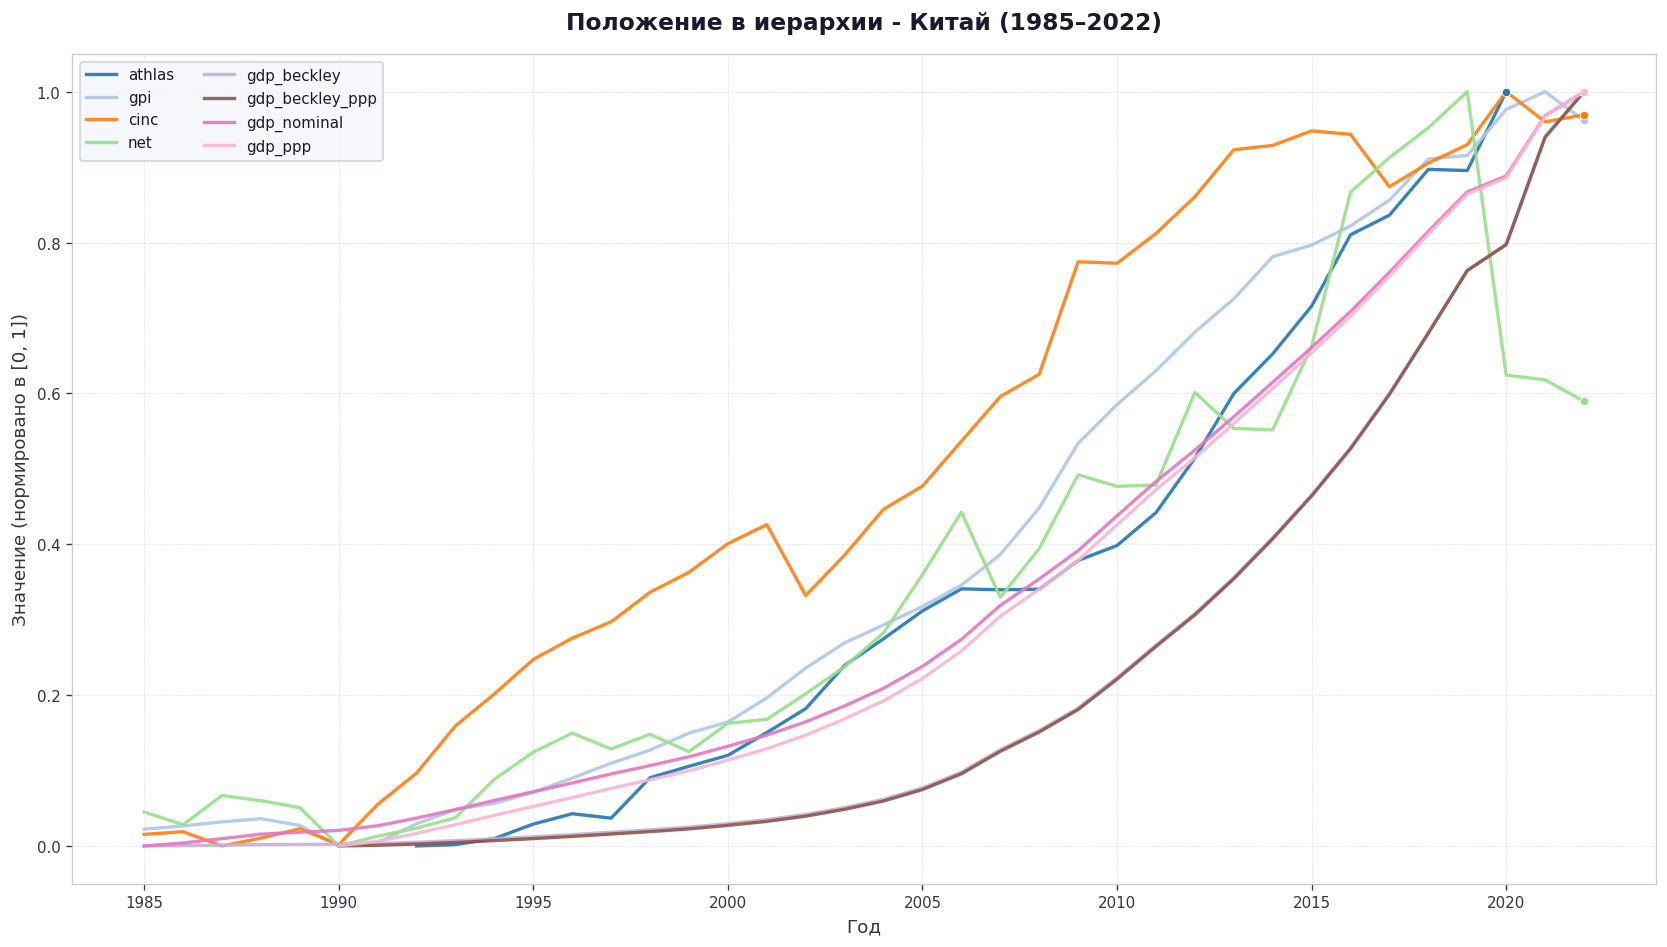

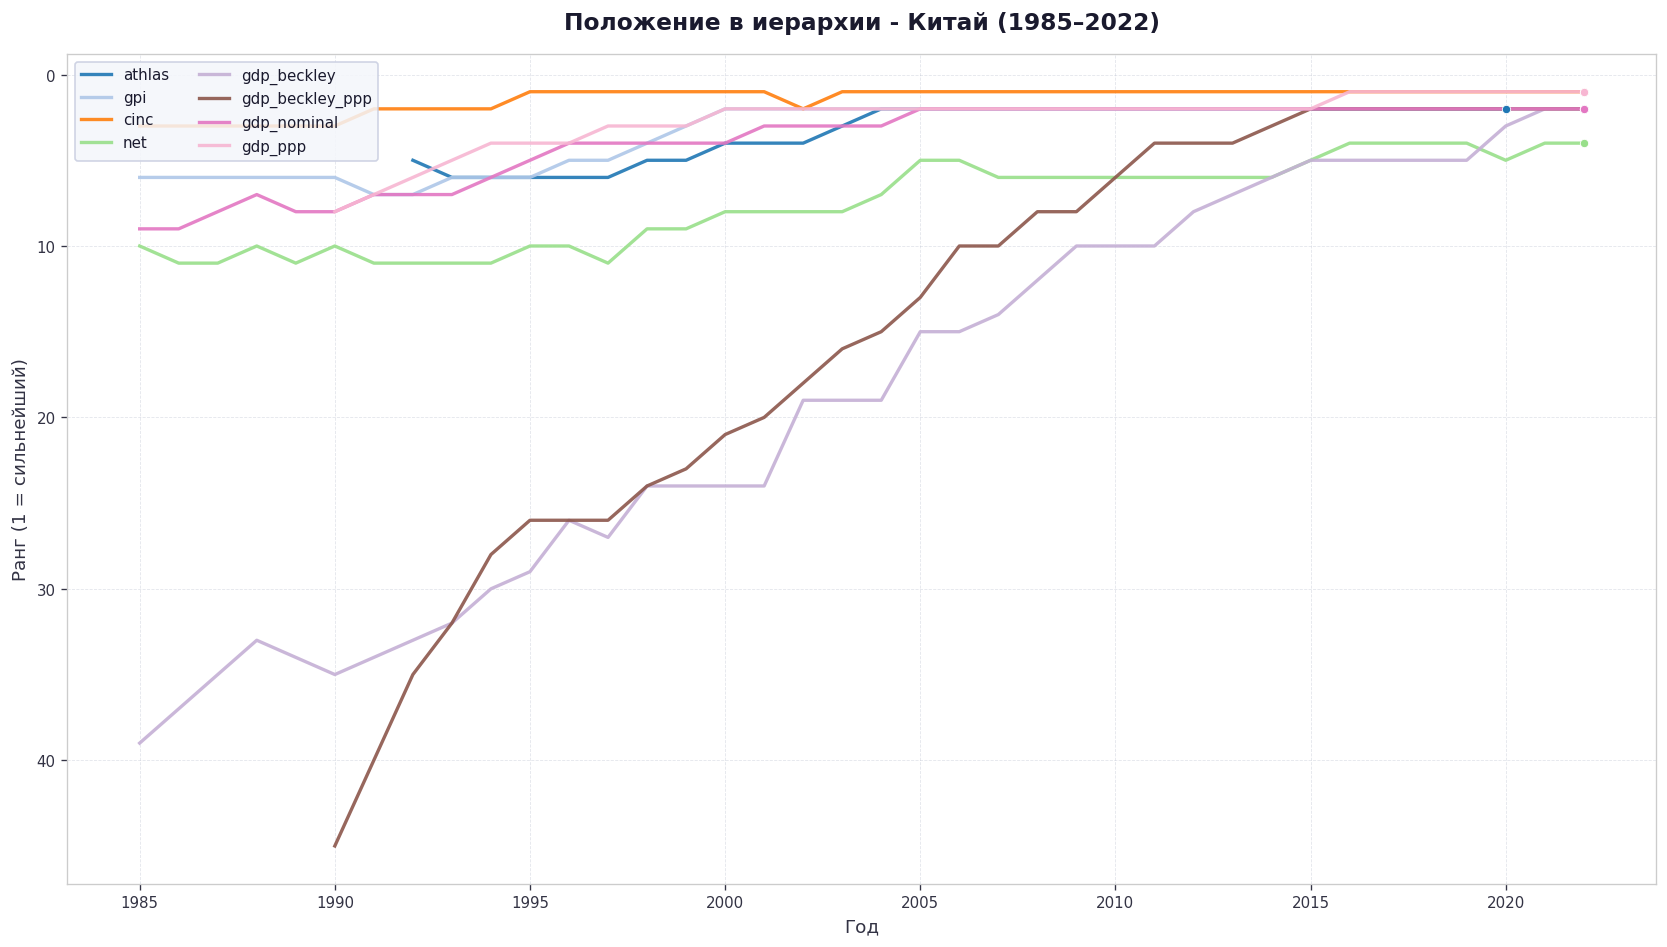

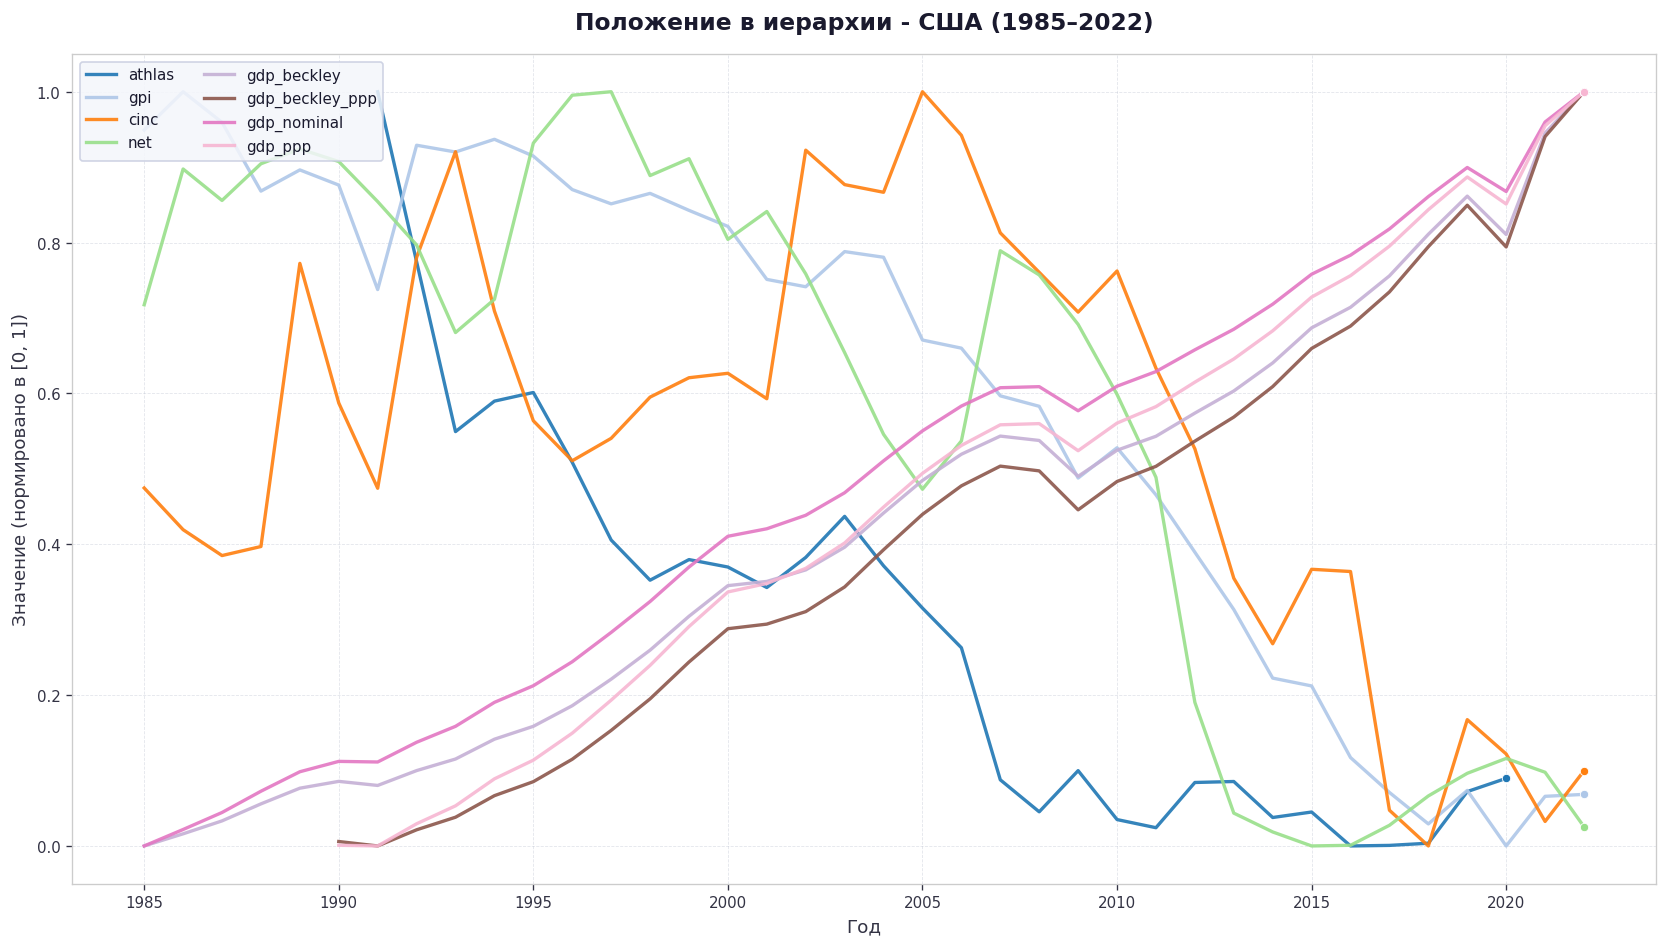

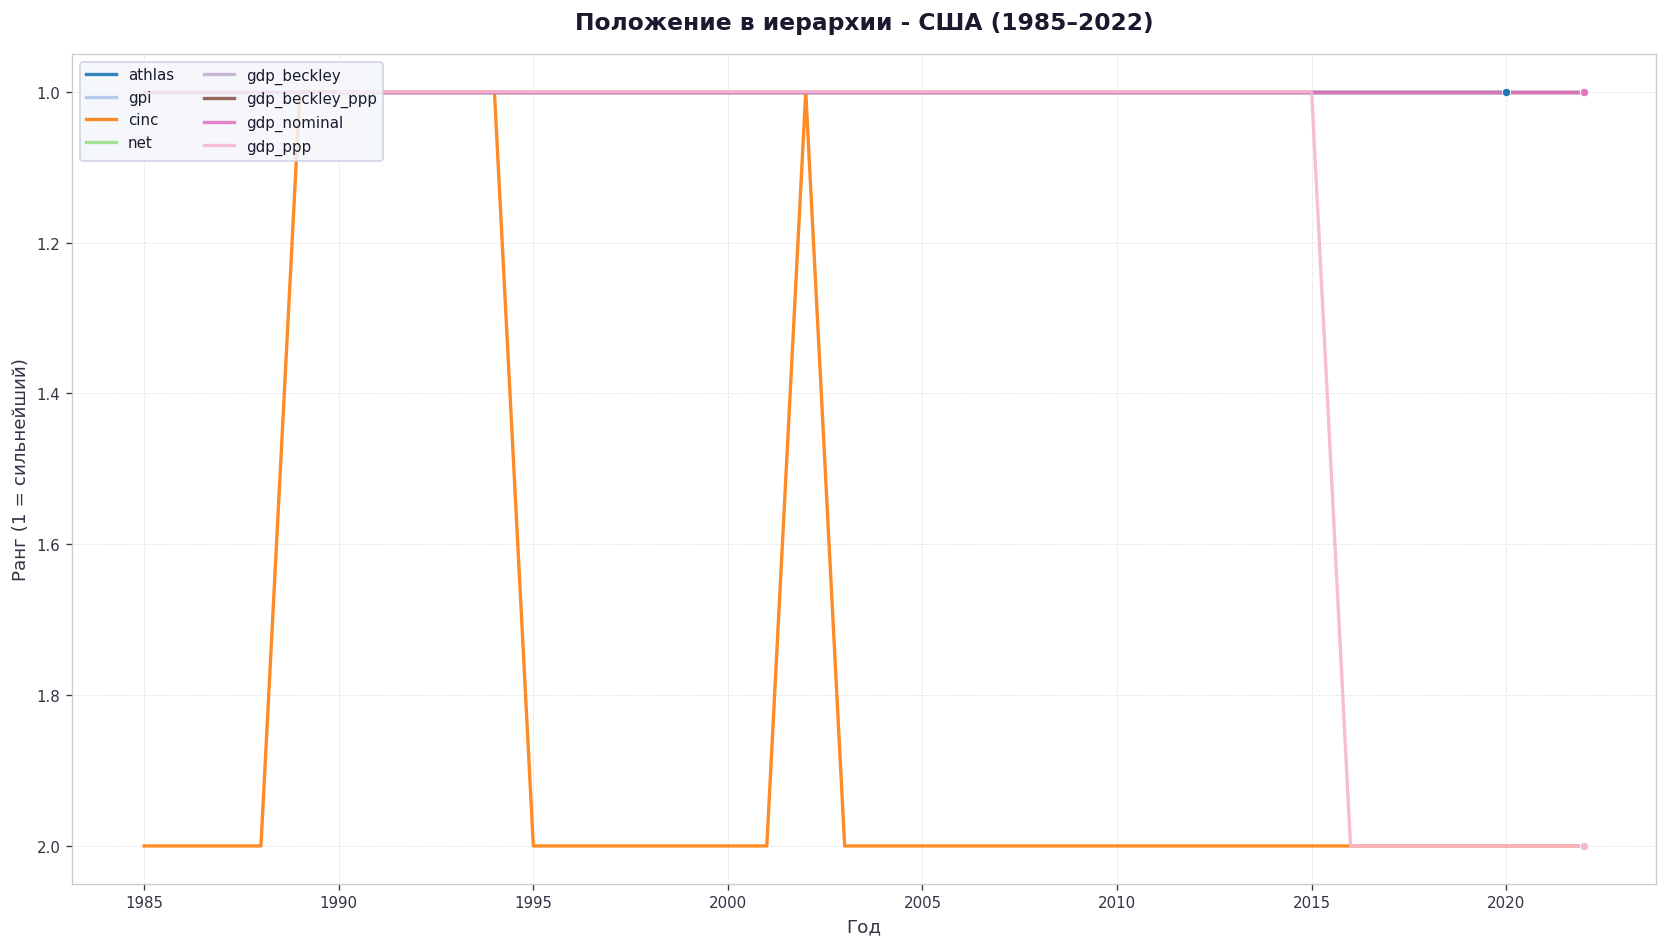

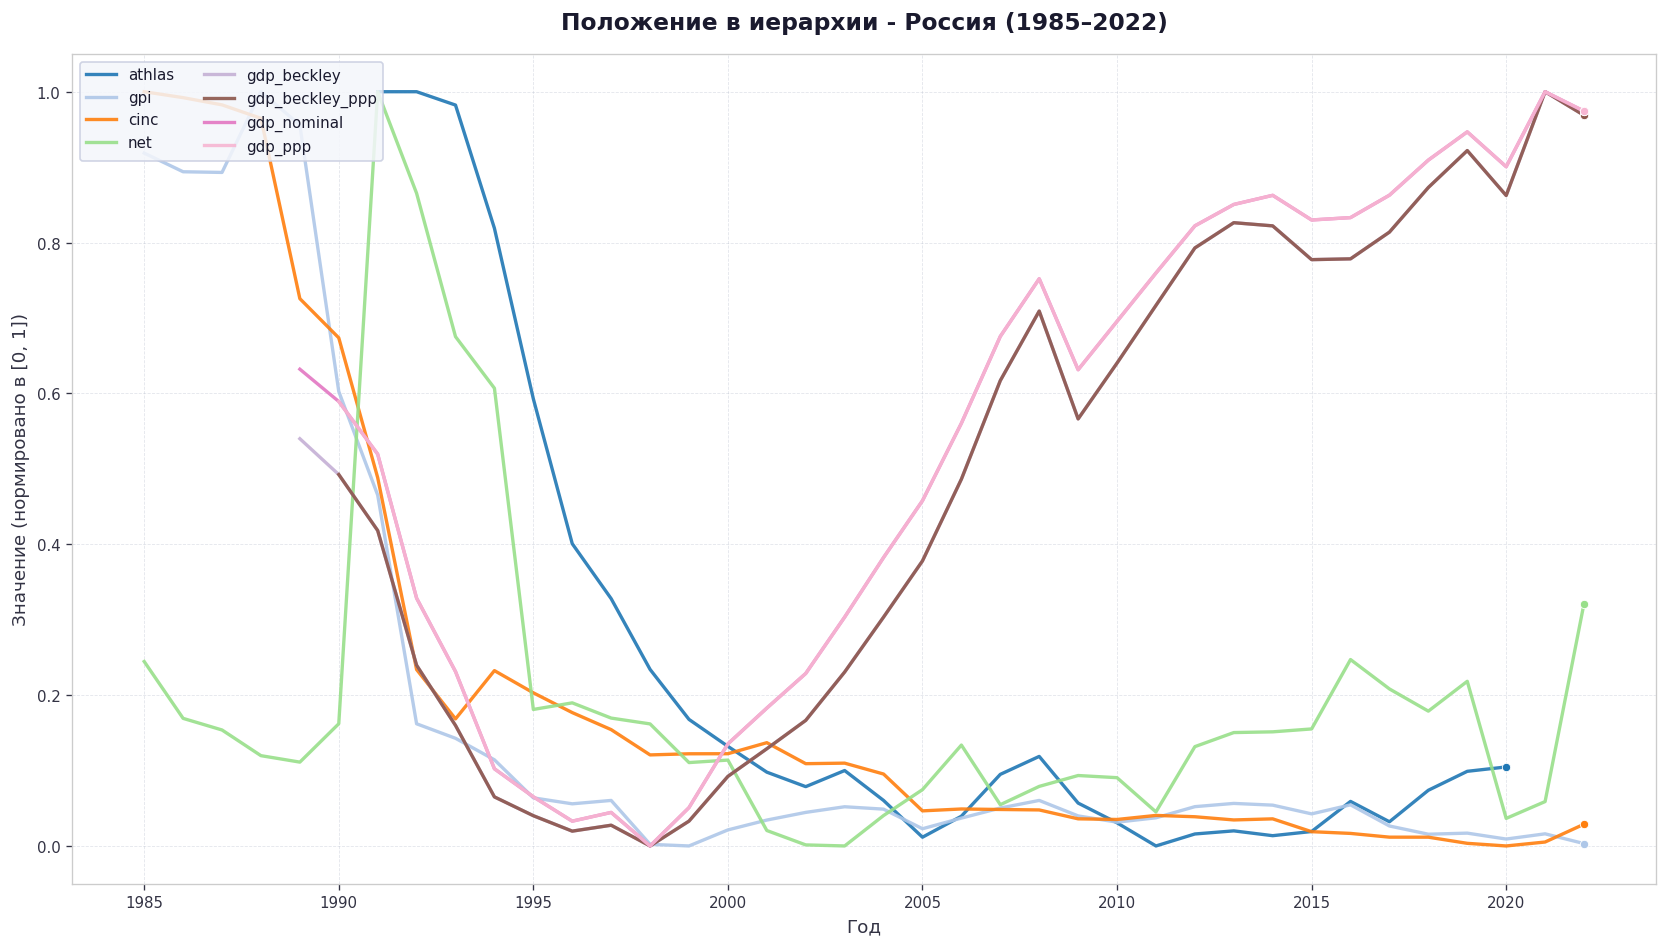

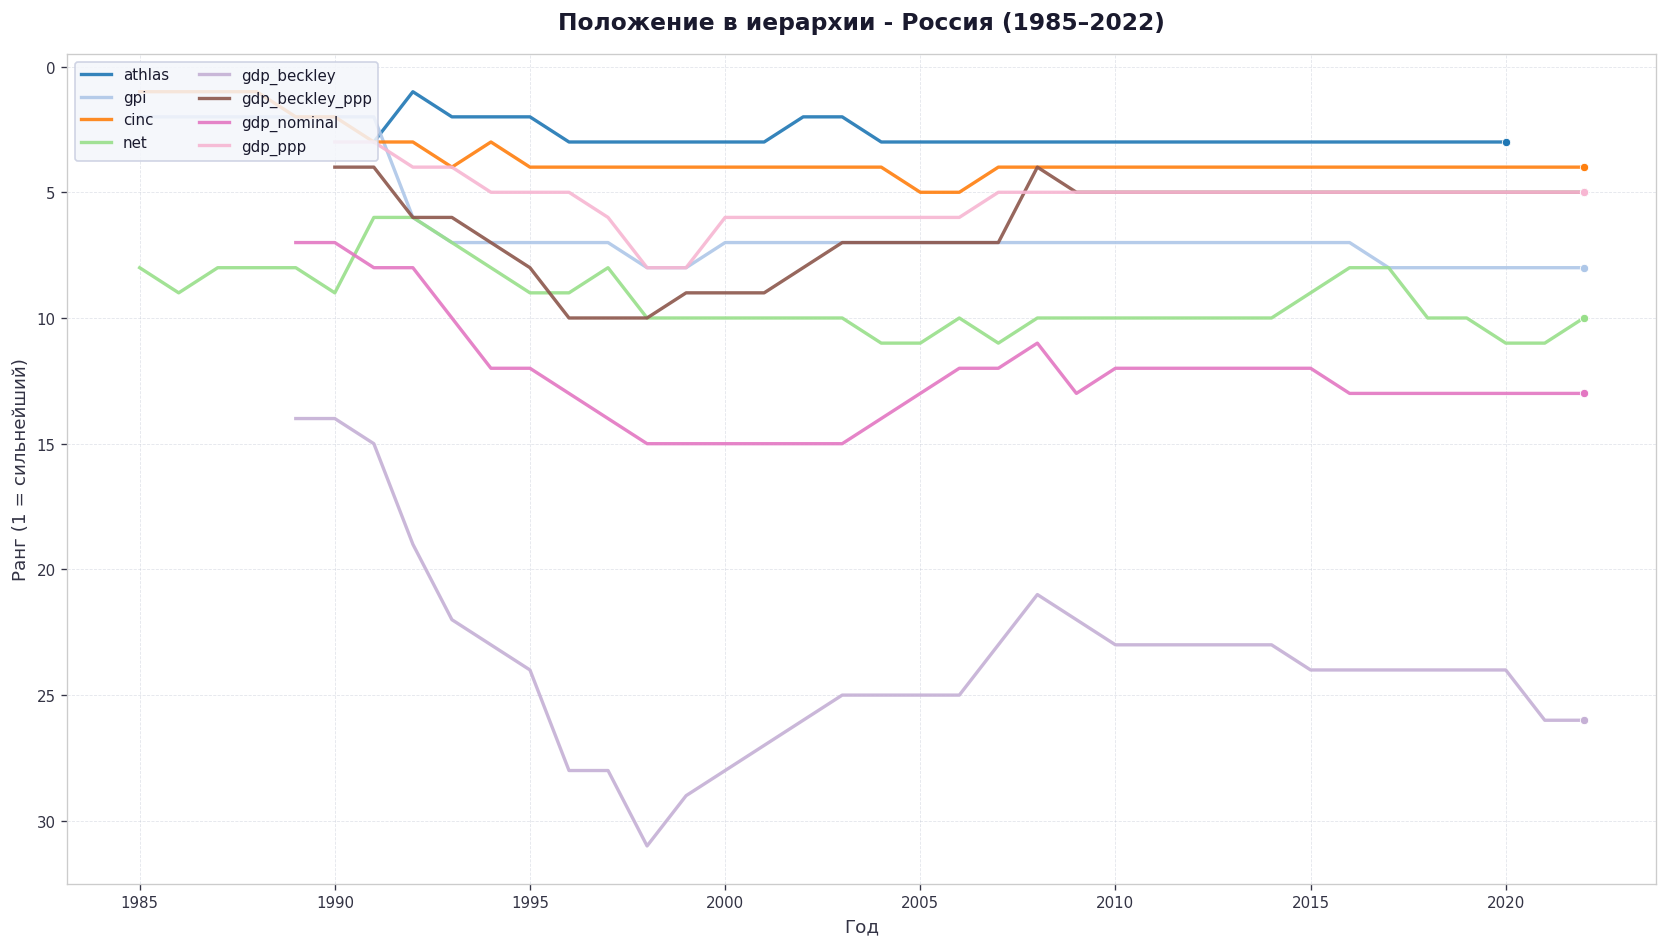

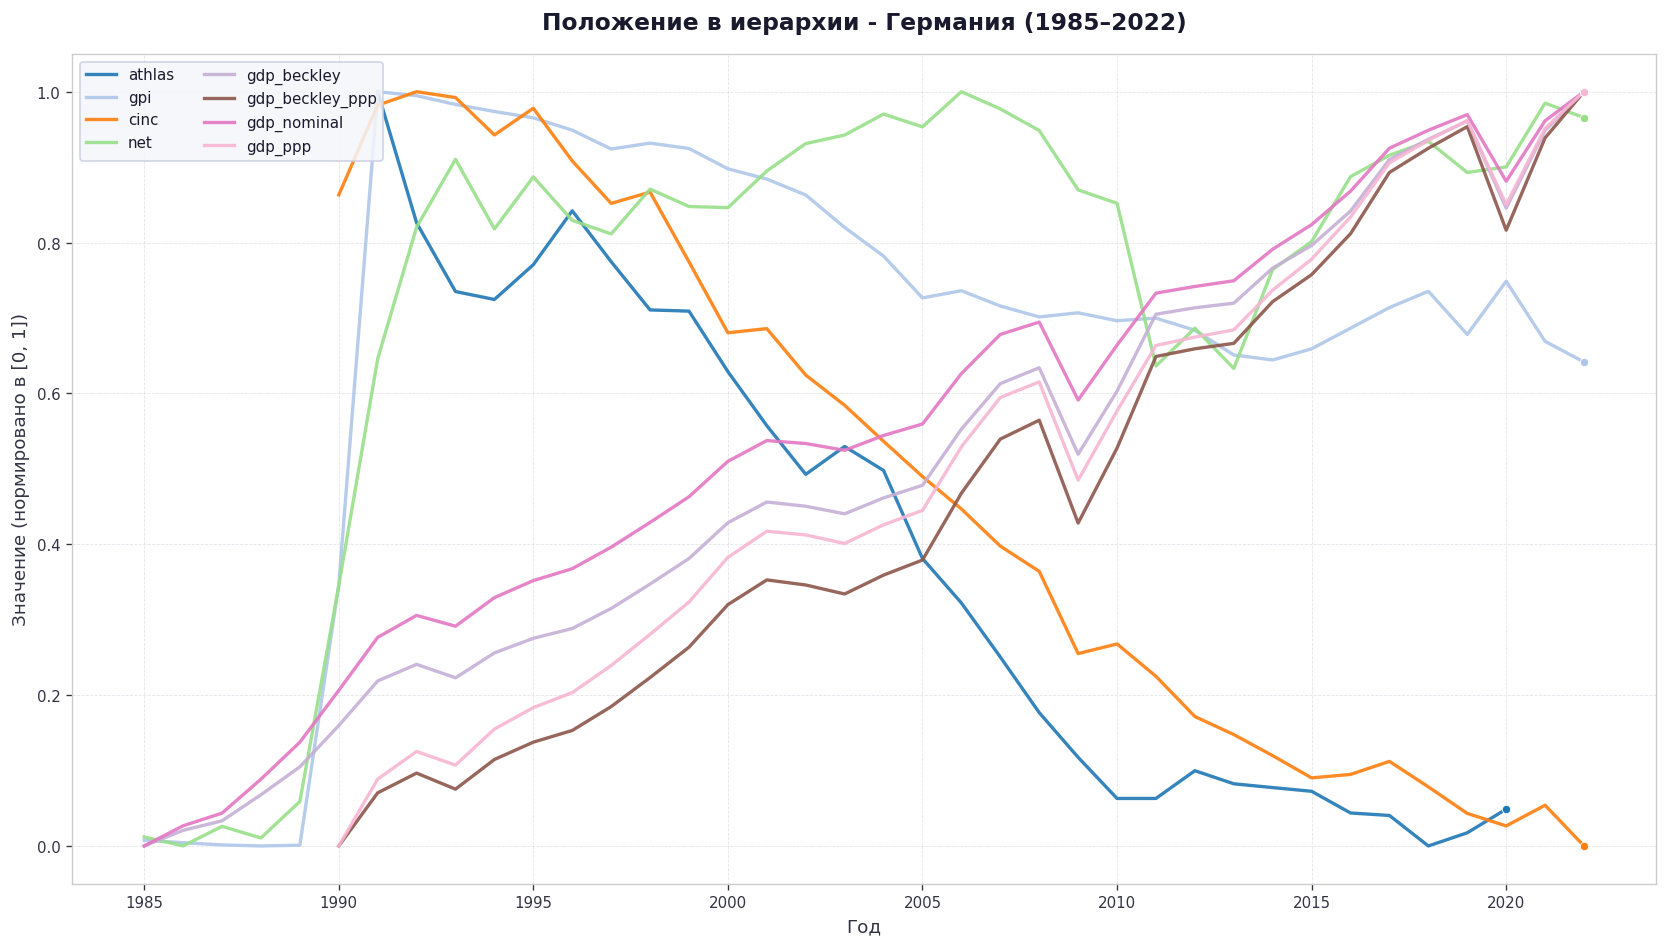

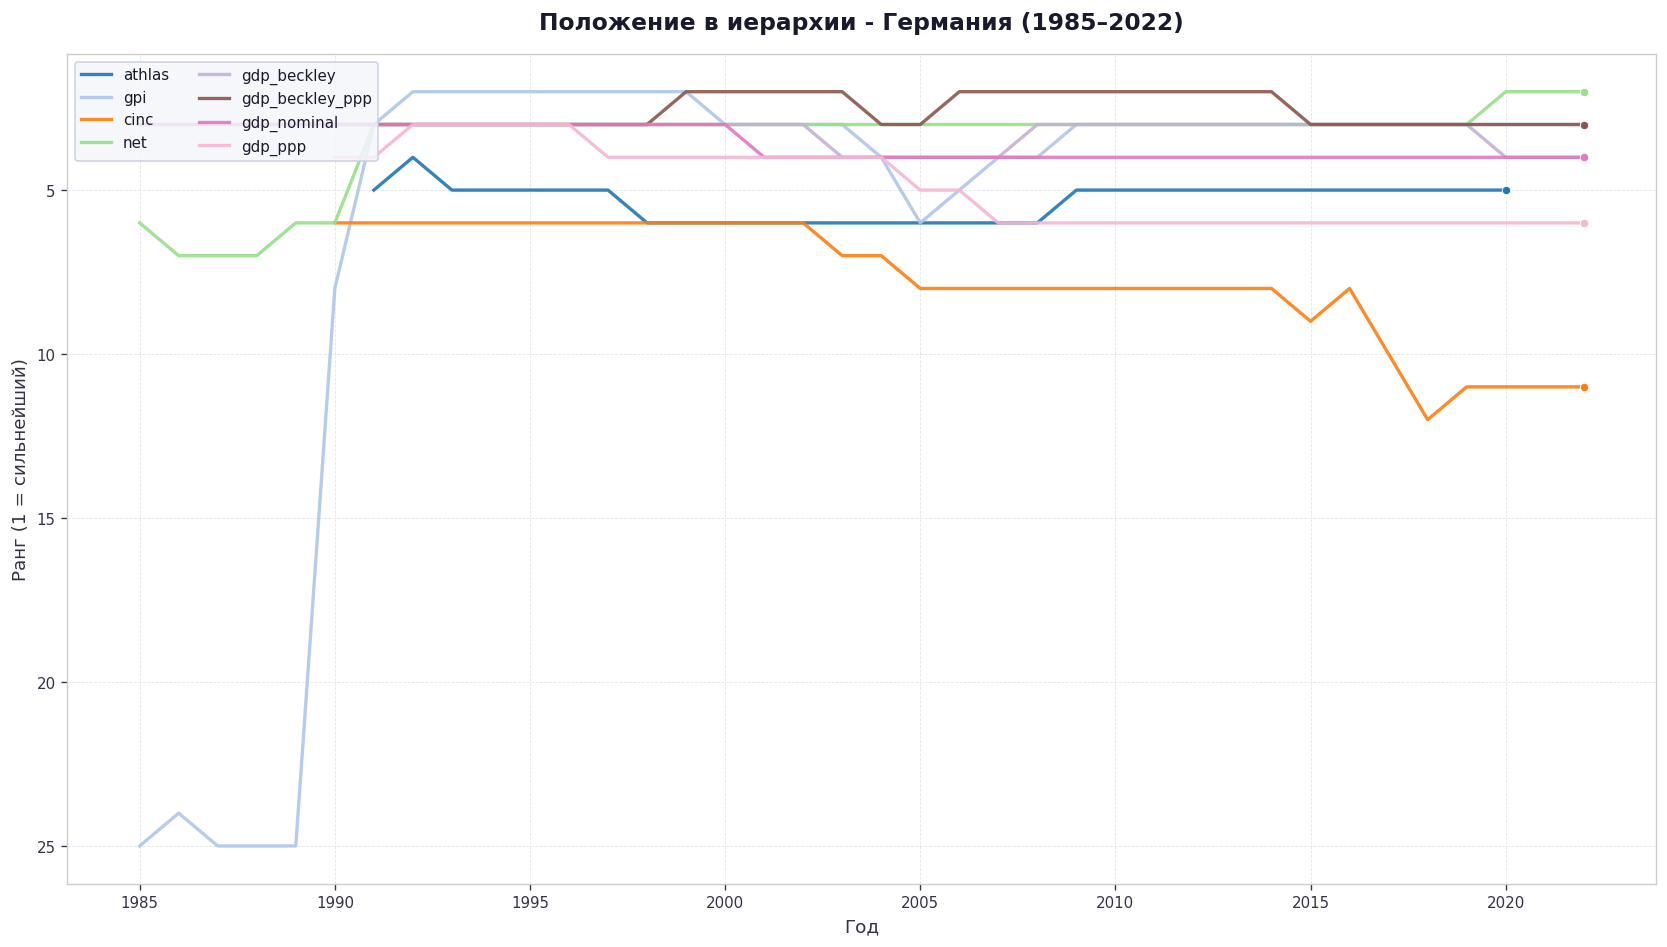

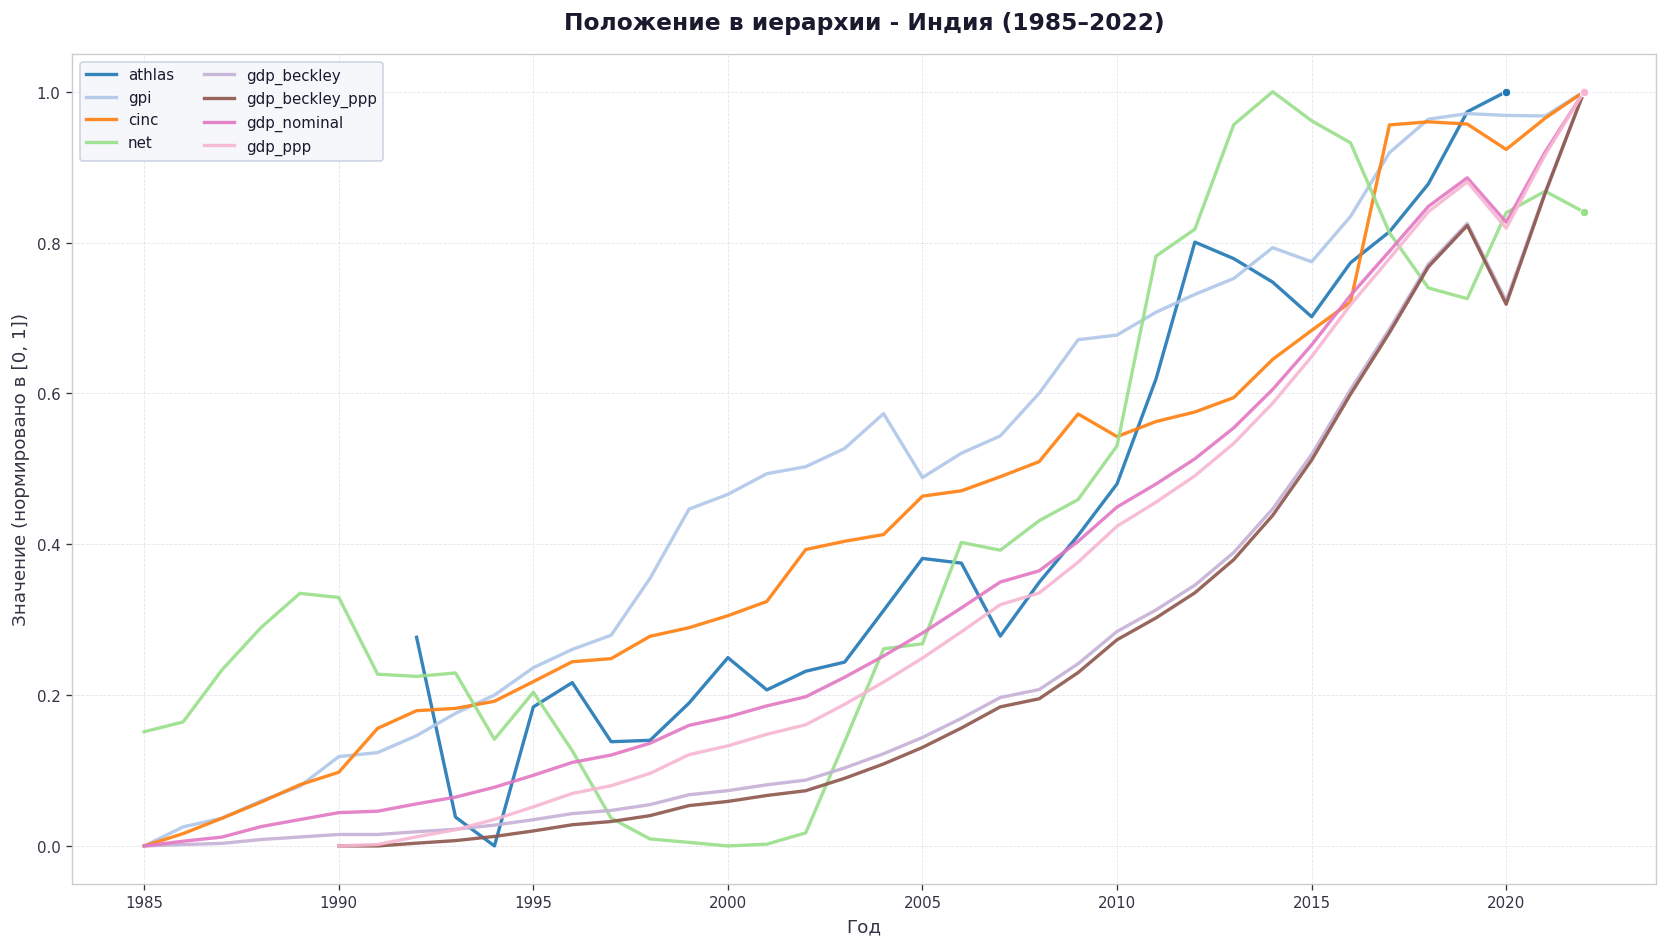

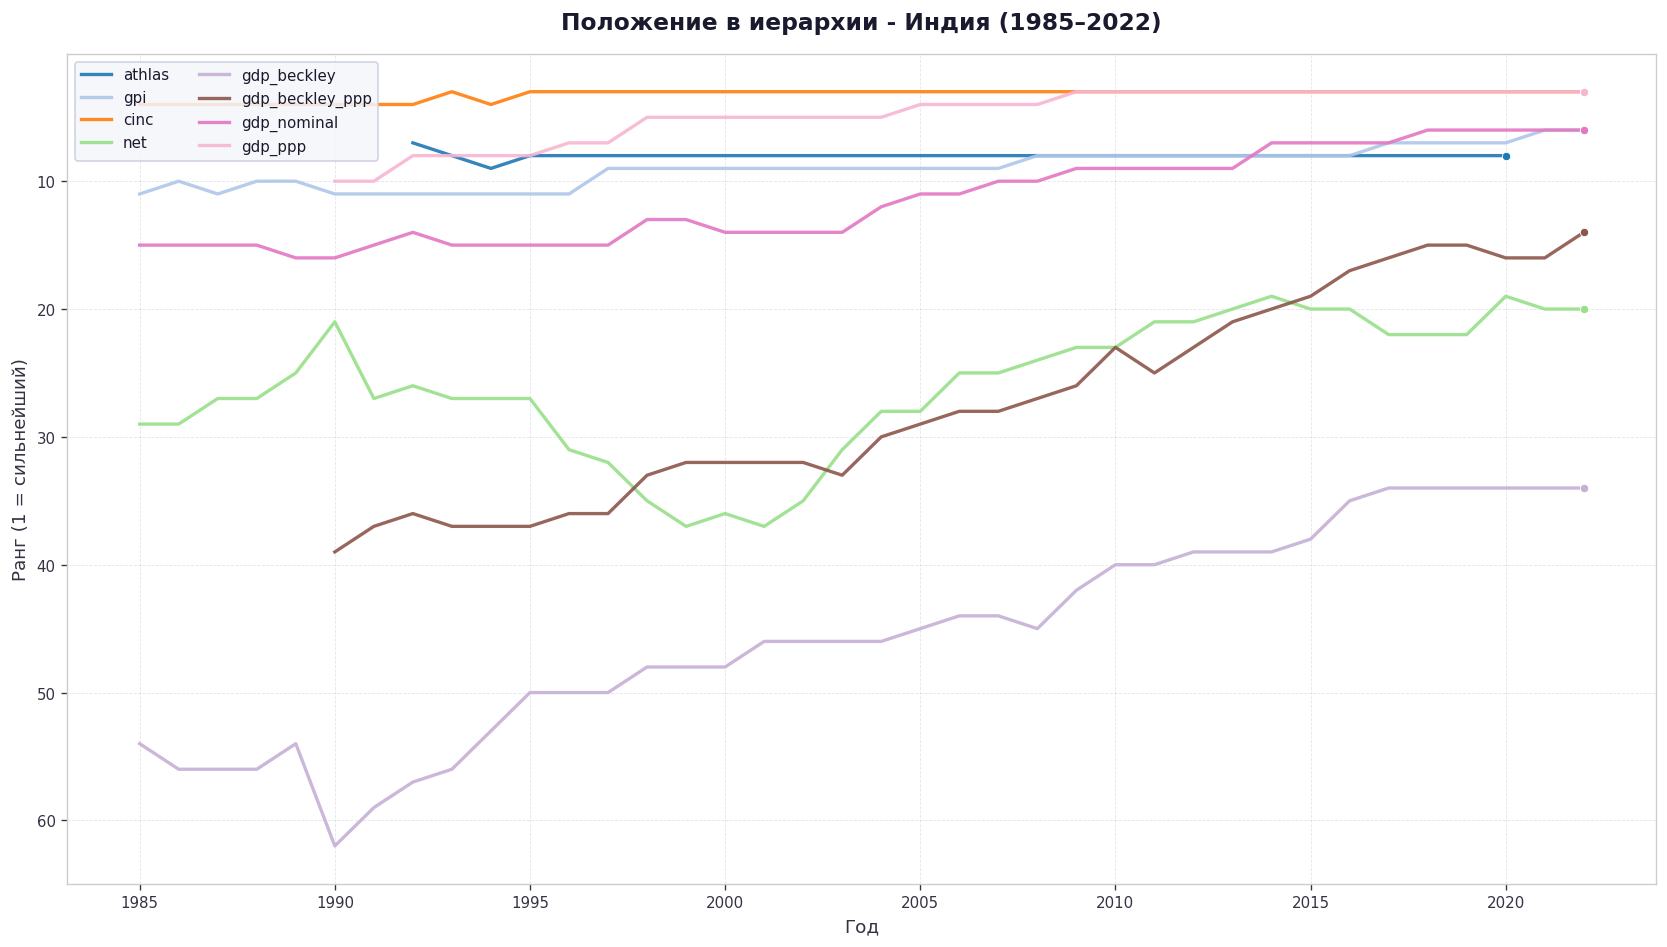

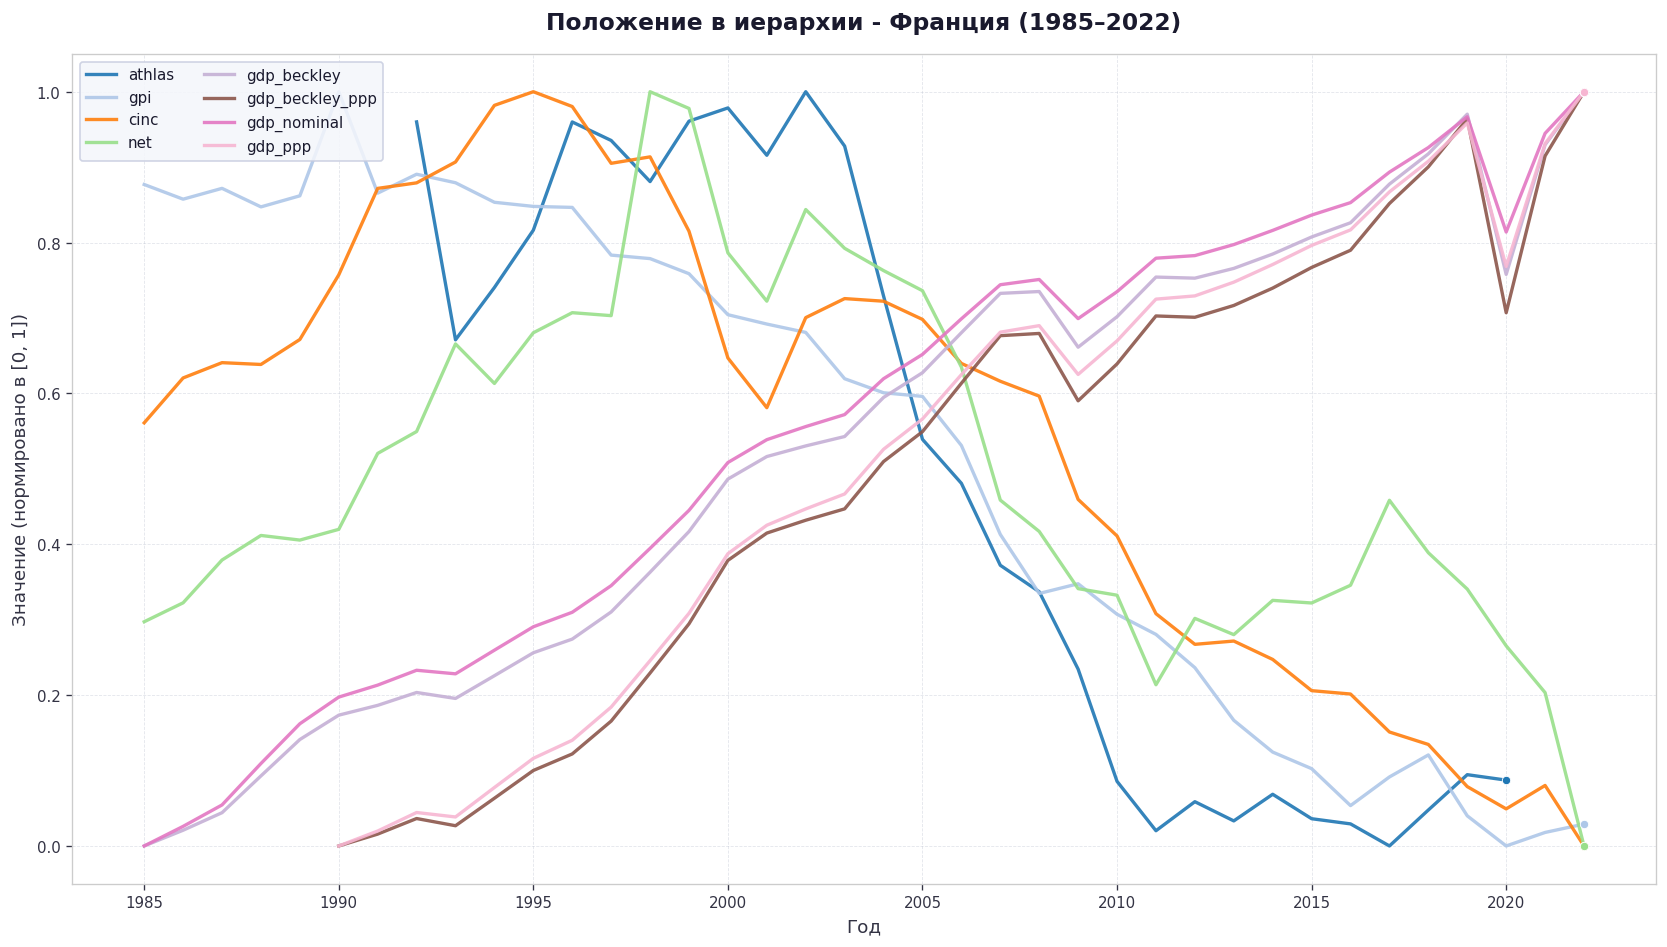

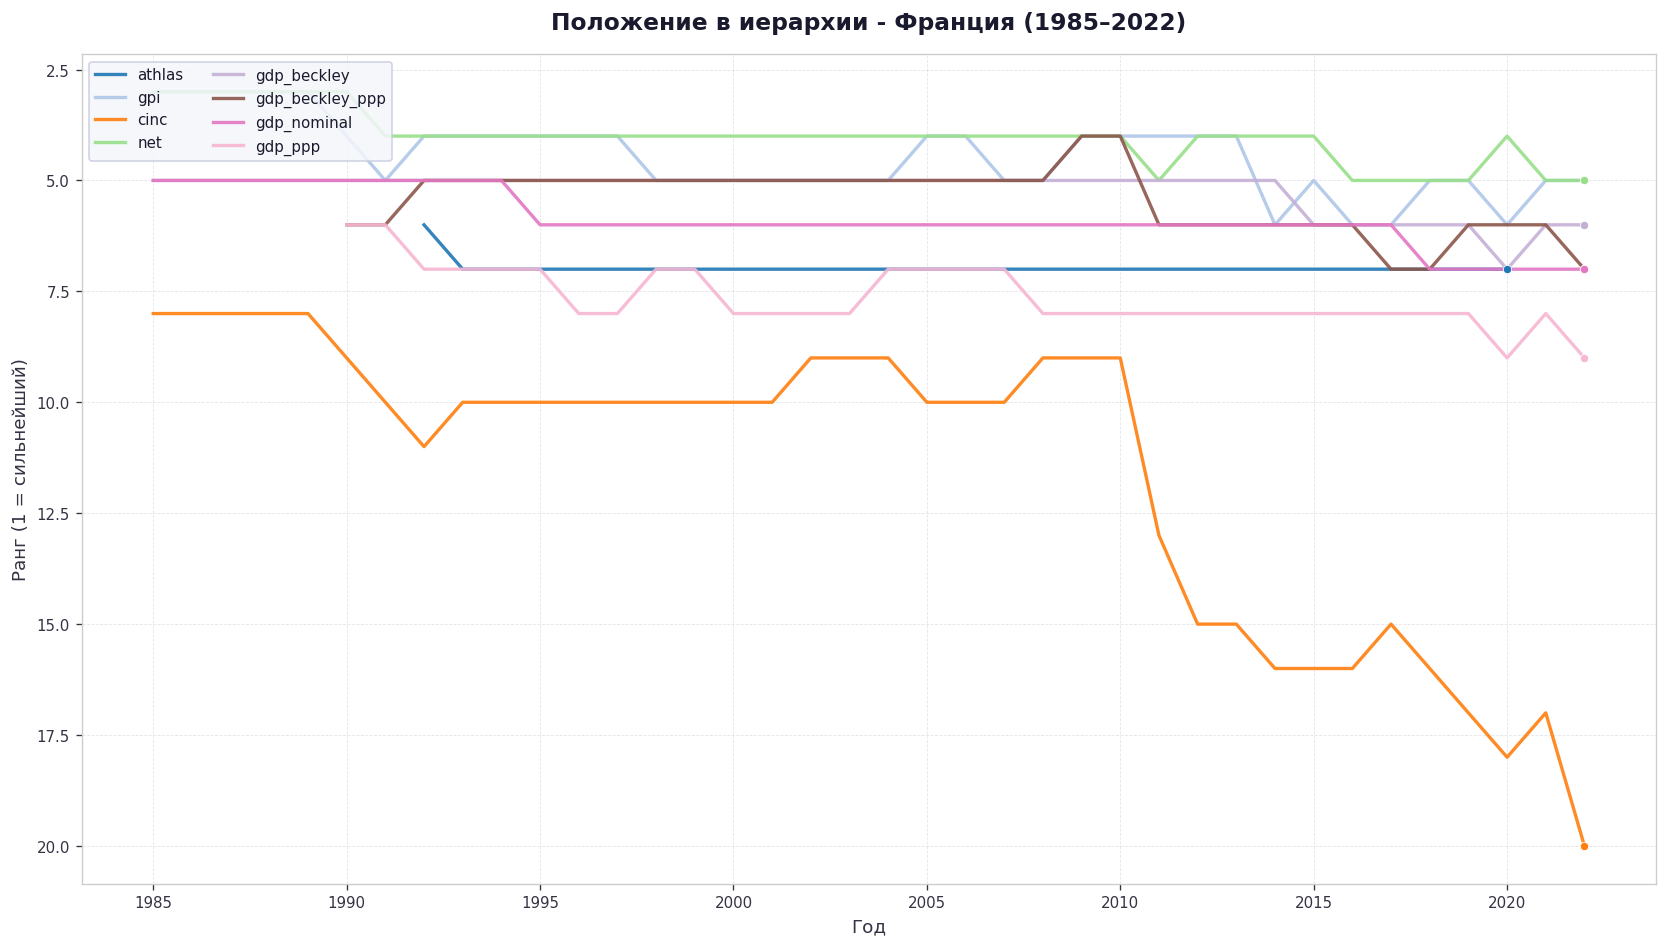

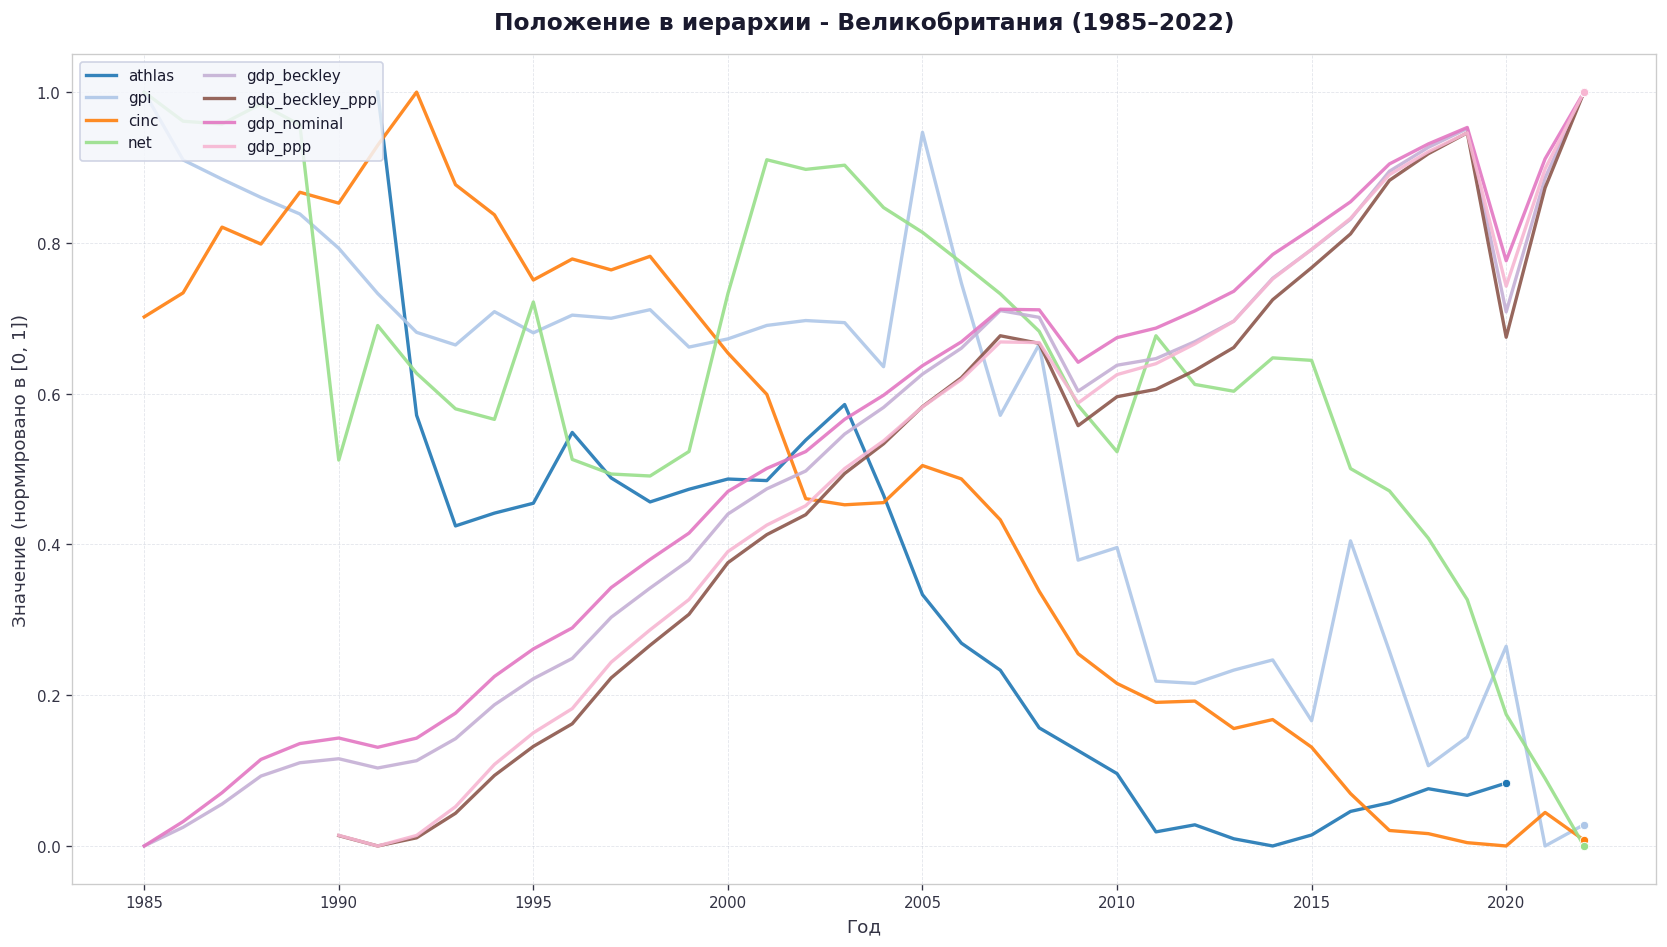

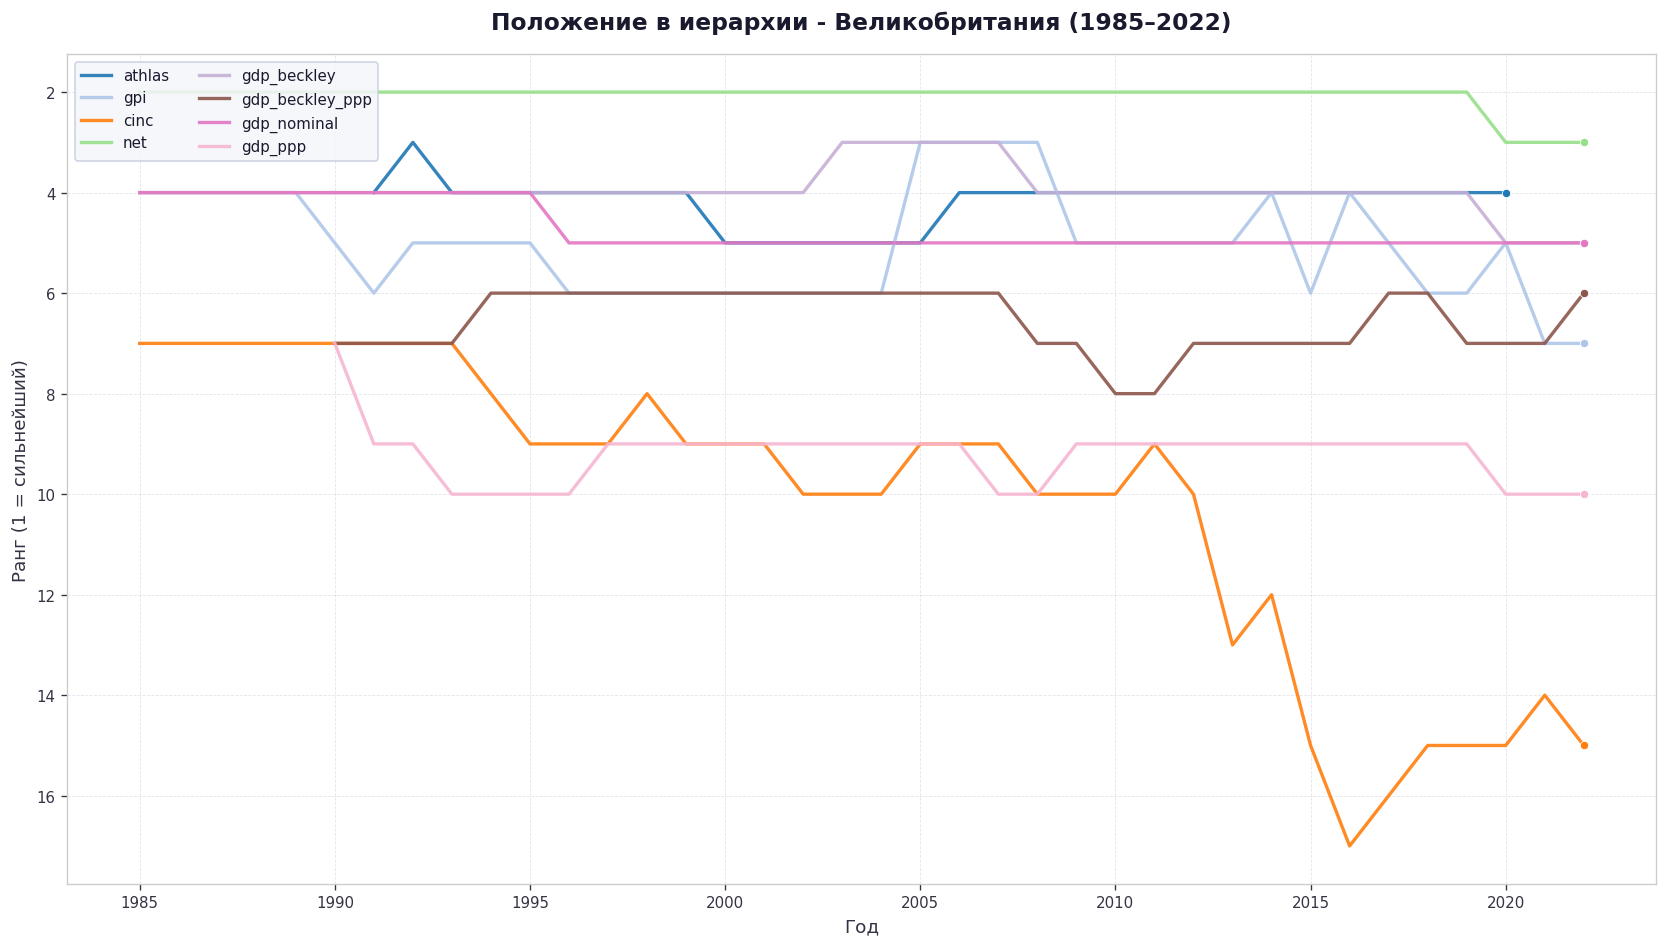

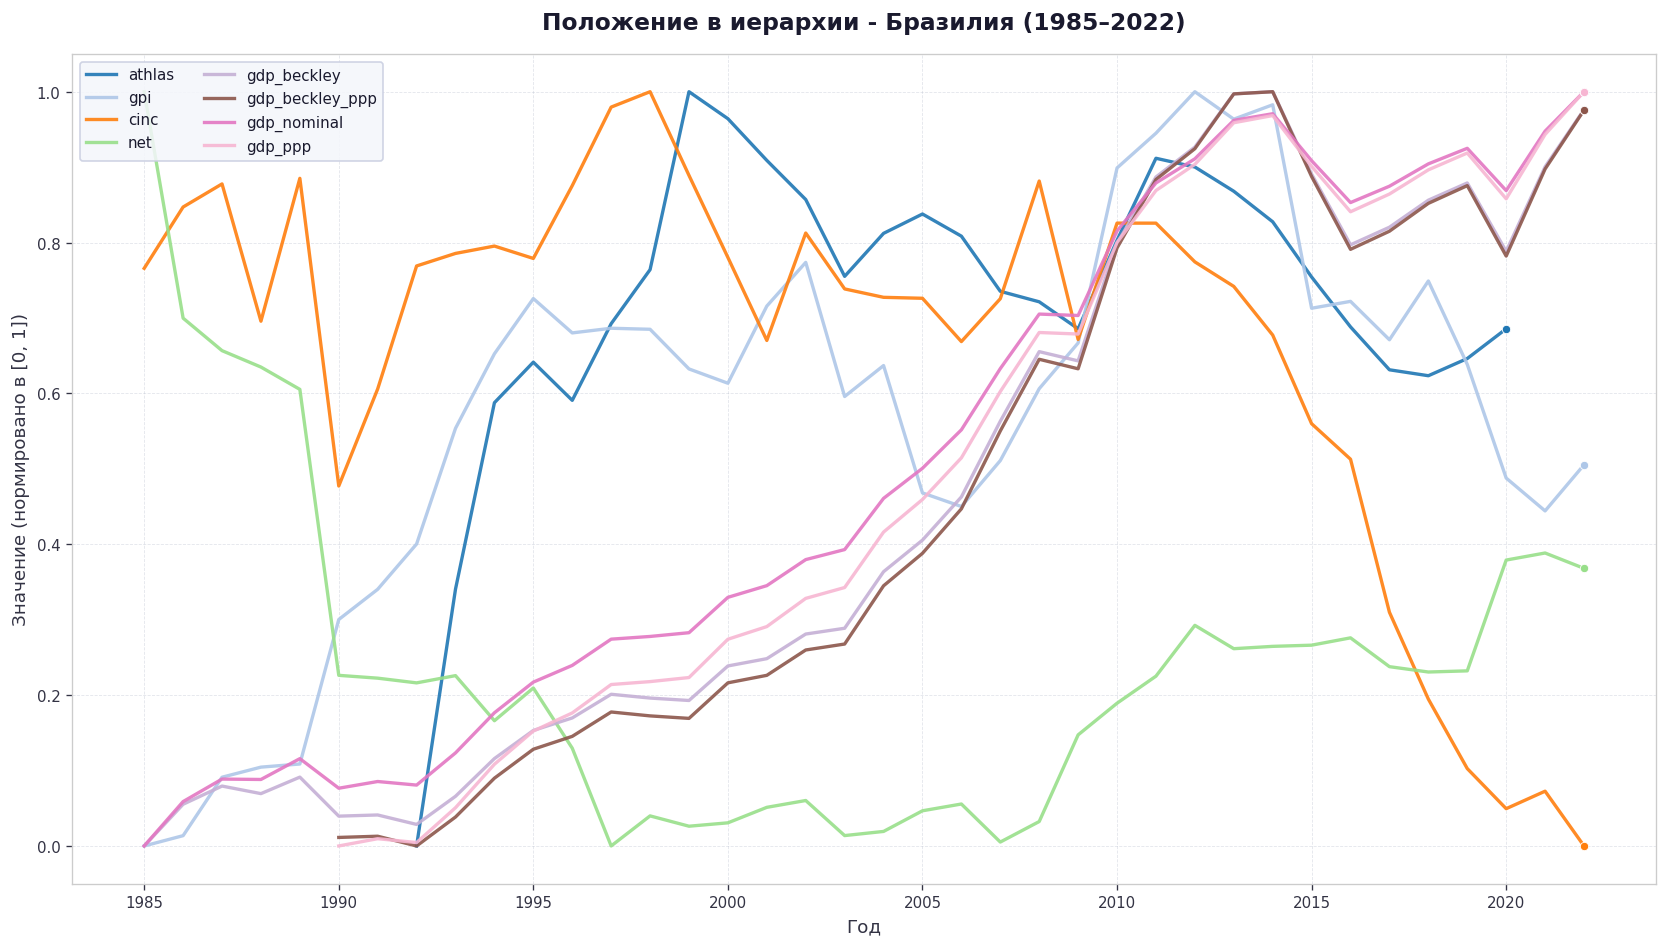

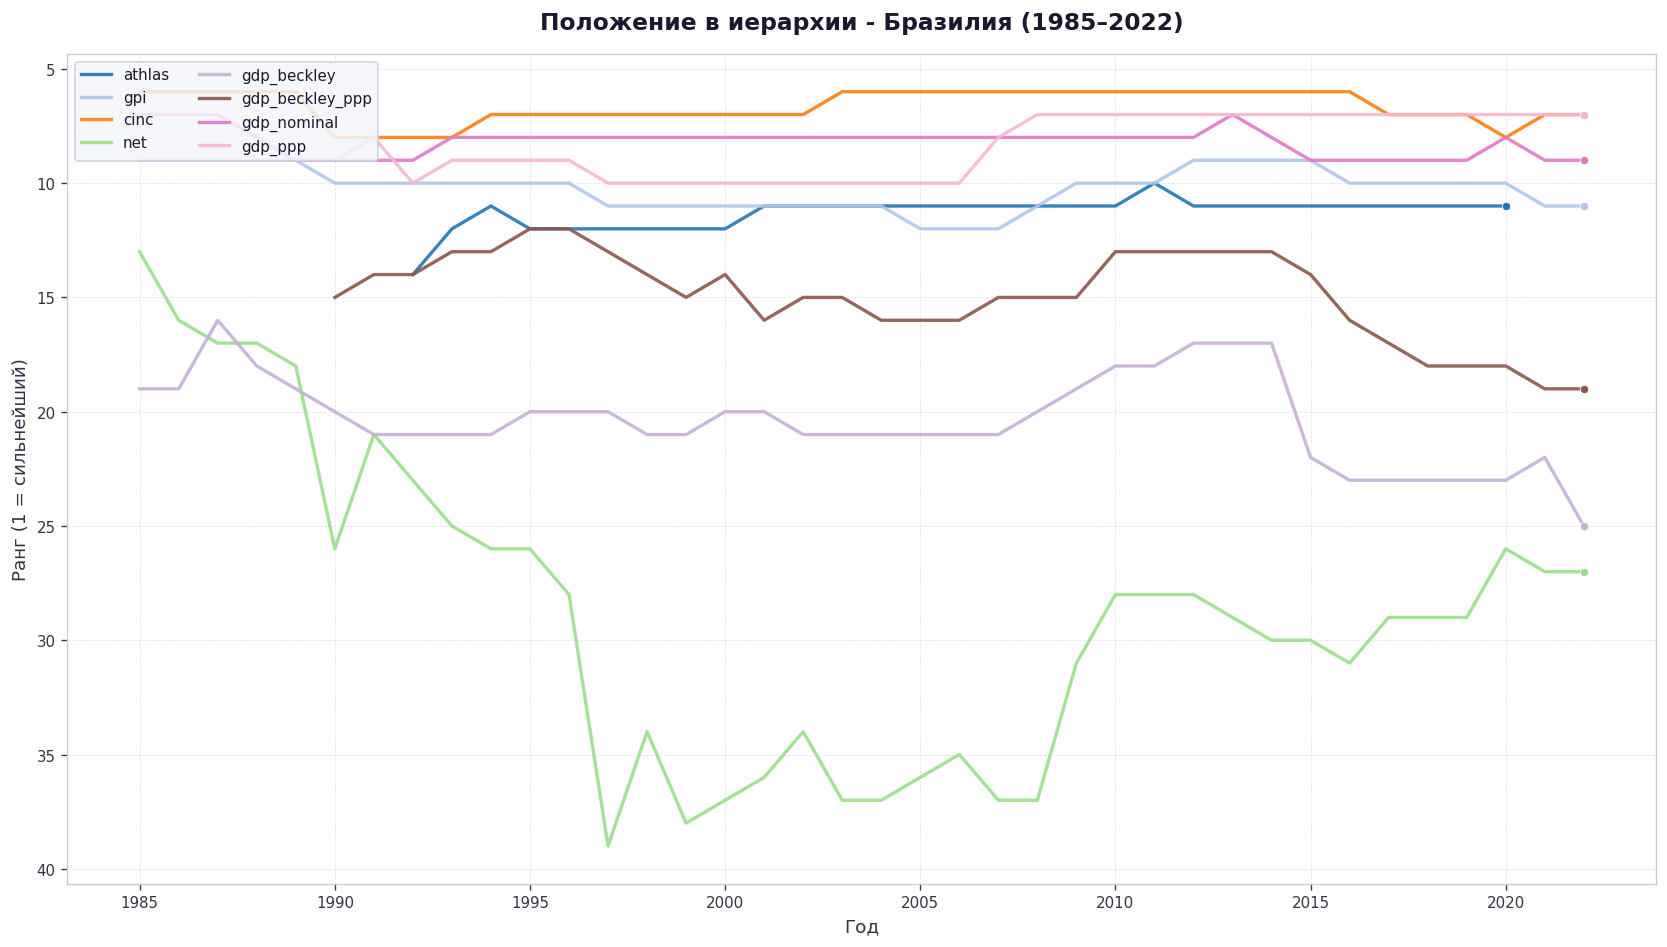

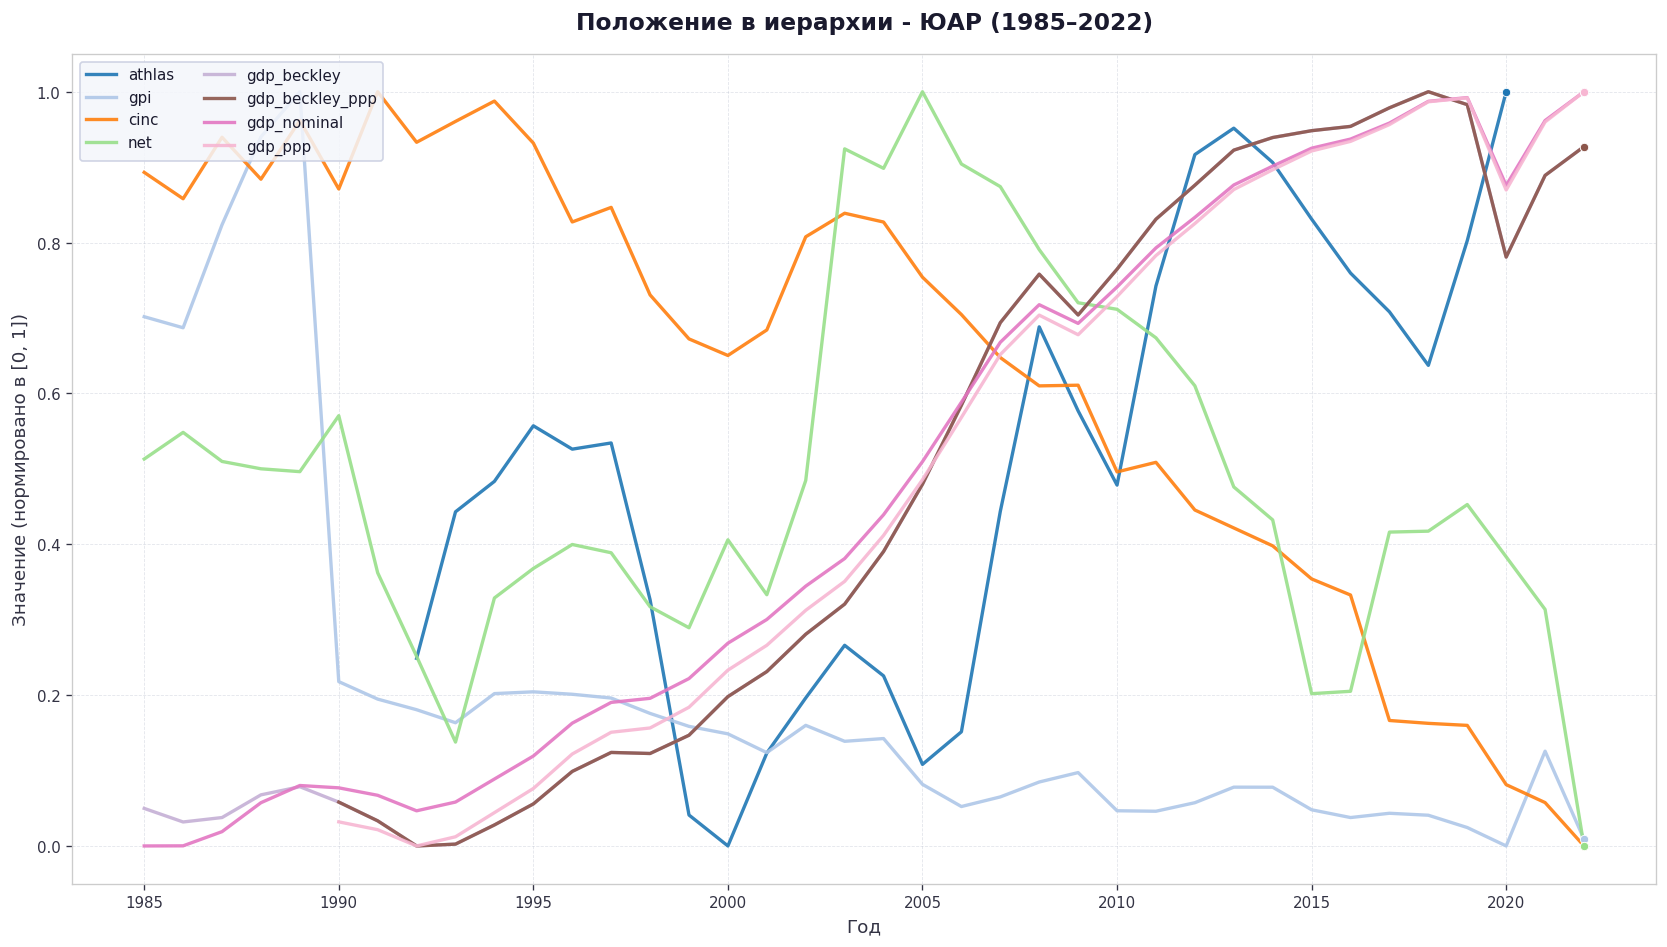

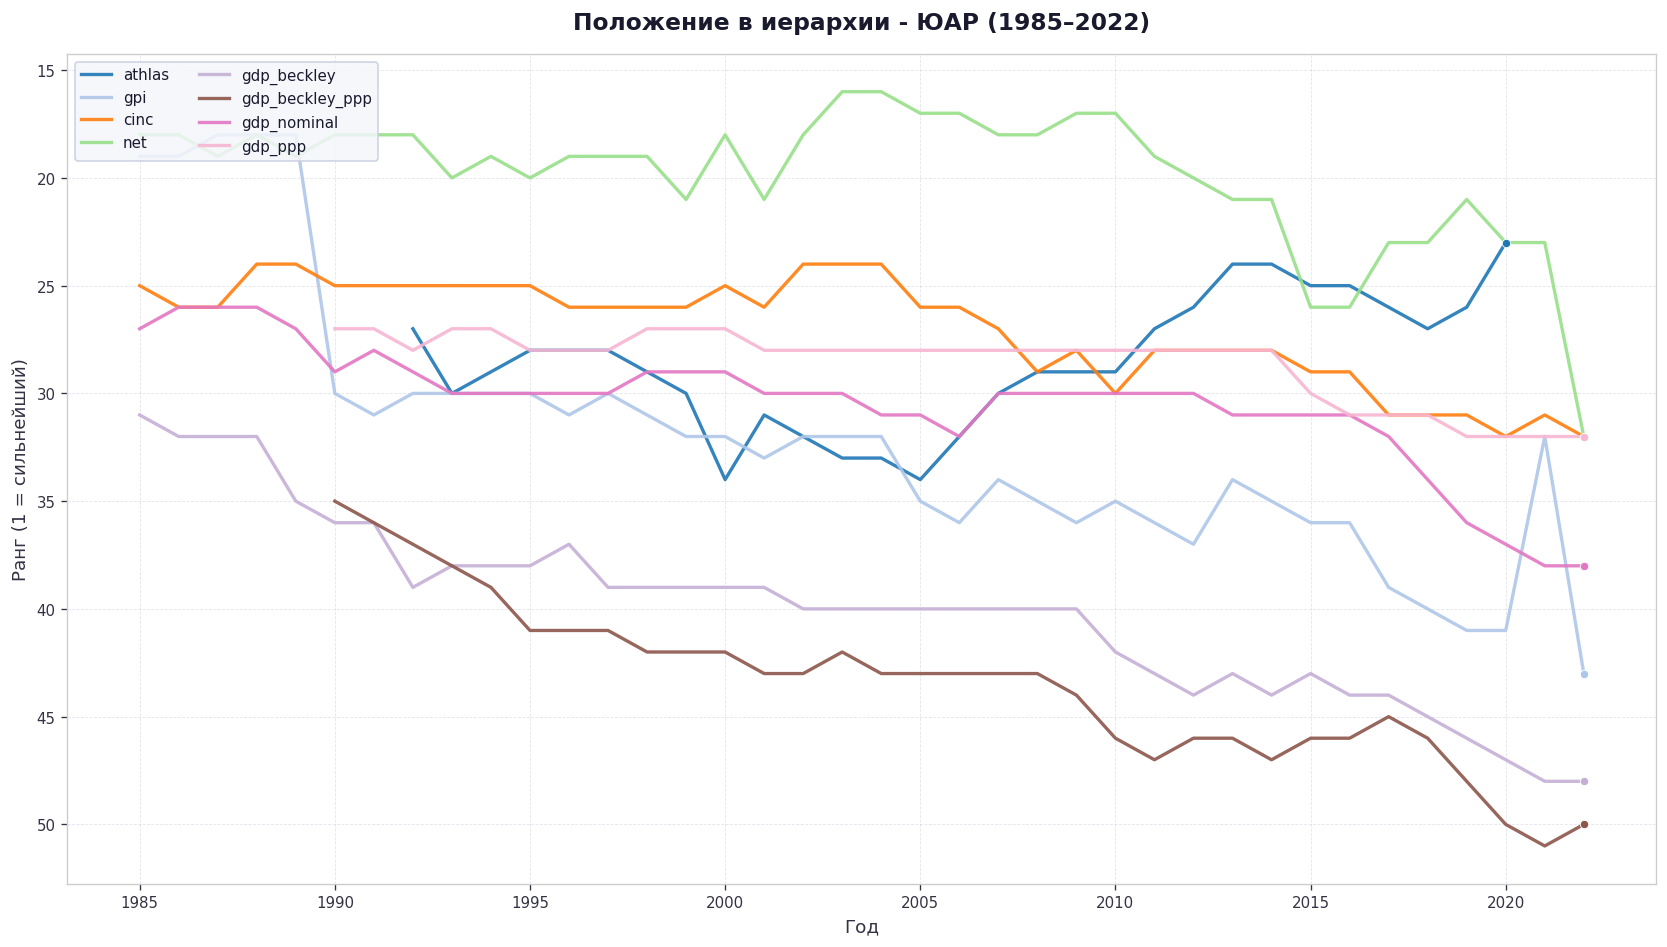

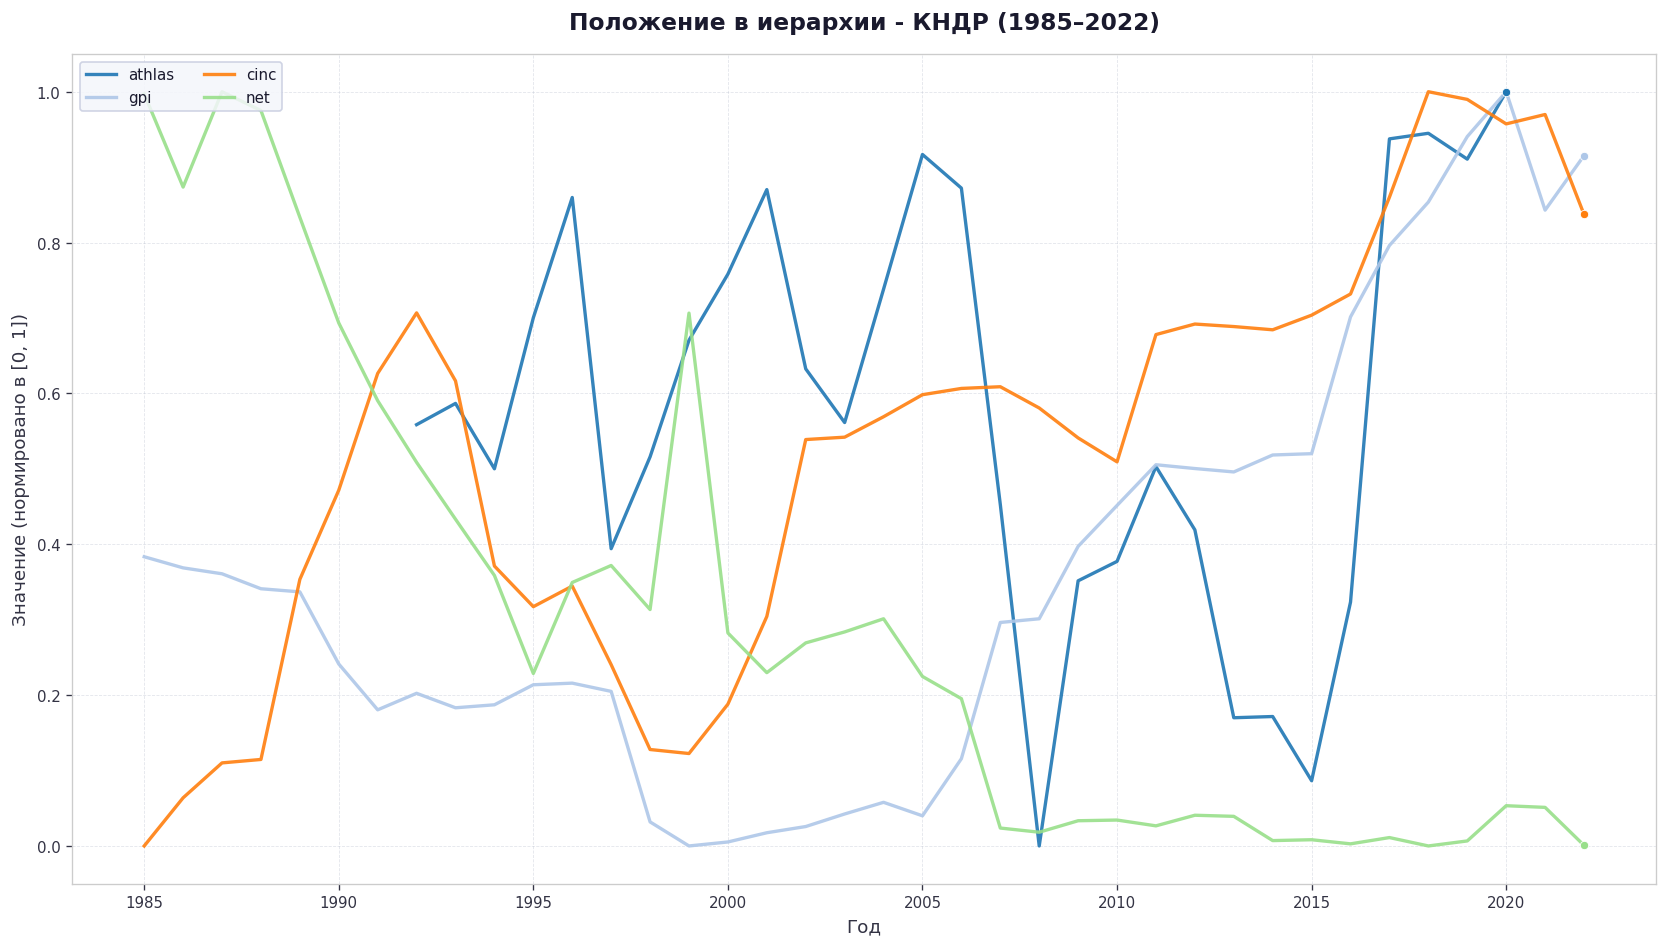

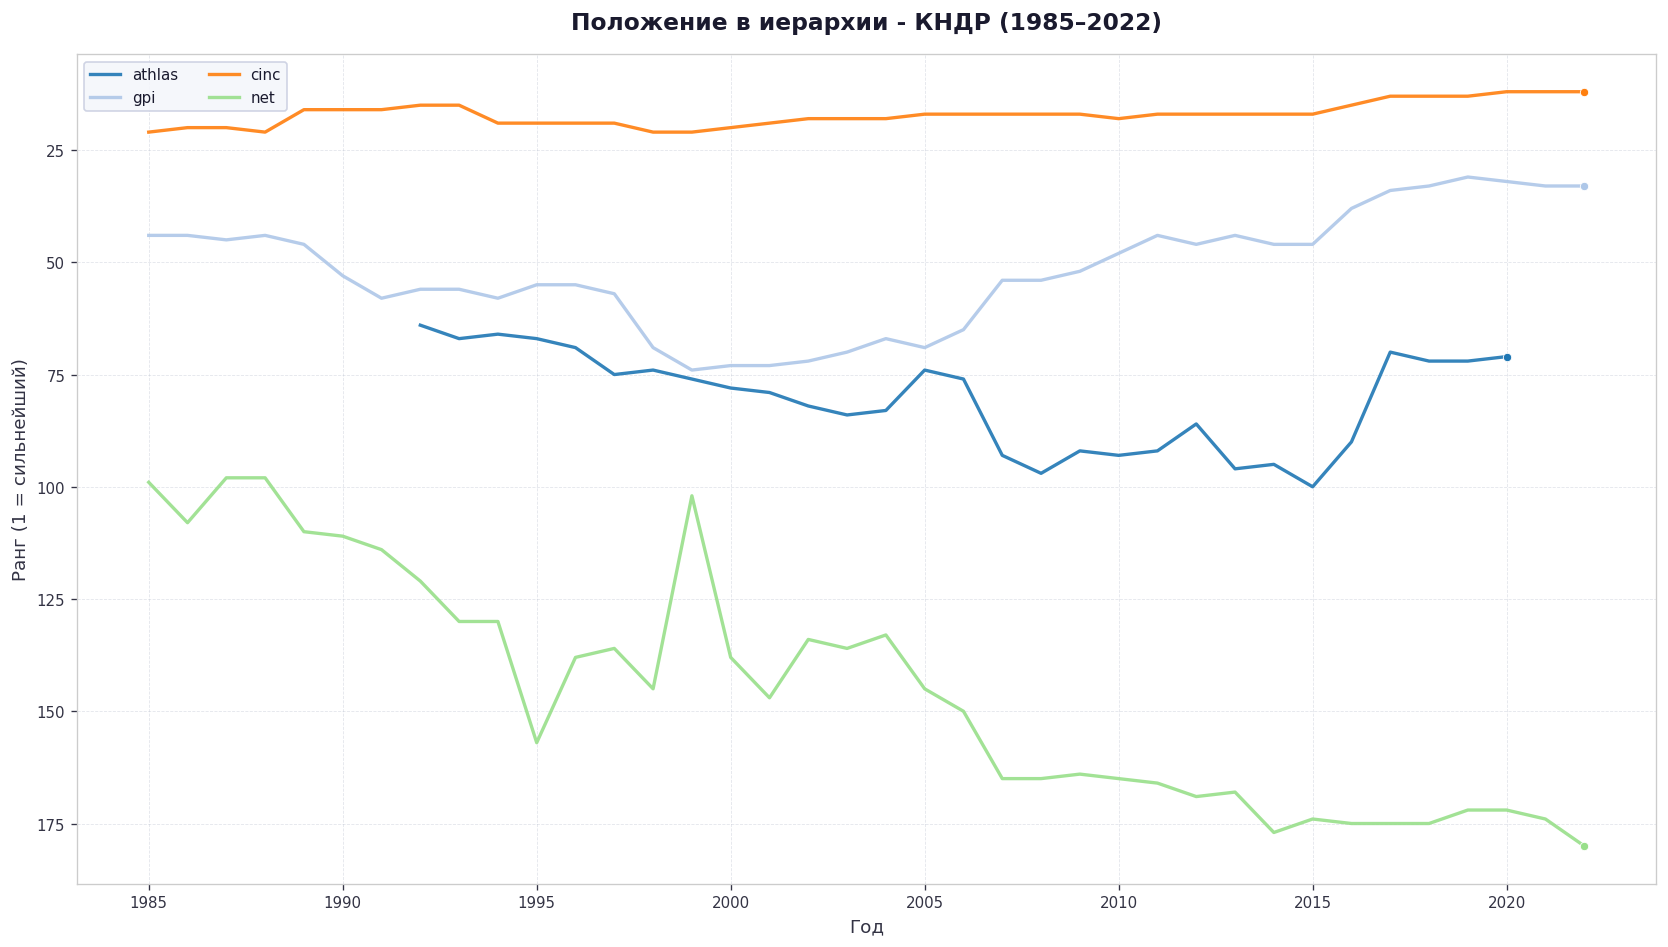

In [42]:
for country in countries:
    plot_power_metrics(
        country=country,
        metrics=power_dfs,
        ignore=ignore,
        scale='normalize',
        title=f'Положение в иерархии - {countries[country]["ru"]} (1985–2022)',
        save_path=f'{RES_PATH}/{country}_power_normalize.png',
    )
    plot_power_metrics(
            country=country,
            metrics=power_dfs,
            ignore=ignore,
            scale='rank',
            title=f'Положение в иерархии - {countries[country]["ru"]} (1985–2022)',
            save_path=f'{RES_PATH}/{country}_power_rank.png',
        )

In [79]:
import warnings
import logging

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import rankdata
import libpysal
from libpysal.weights import W, full2W, KNN

import geopandas as gpd
from esda.moran import Moran, Moran_Local

from spreg import ML_Lag, ML_Error, ML_Lag_Regimes

In [80]:
import numpy as np
import pandas as pd


_AGG = {
    'mean':   'mean',
    'min':    'min',
    'max':    'max',
    'median': 'median',
    'std':    'std',
    'sum':    'sum',
}


def _reduce_vals(vals, agg):
    """Скалярная агрегация массива (без NaN)."""
    if len(vals) == 0:
        return np.nan
    if agg == 'mean':   return float(np.mean(vals))
    if agg == 'min':    return float(np.min(vals))
    if agg == 'max':    return float(np.max(vals))
    if agg == 'median': return float(np.median(vals))
    if agg == 'std':    return float(np.std(vals, ddof=1)) if len(vals) > 1 else np.nan
    if agg == 'sum':    return float(np.sum(vals))
    raise ValueError(agg)


def build_exog_neighbors(df,
                         w,
                         country_names,
                         side_a='country_a',
                         side_b='country_b',
                         year_col='year',
                         value_col='value',
                         agg='mean',
                         strategy='binary',
                         year=None,
                         k=5,
                         threshold=None,
                         row_standardize=True,
                         drop_isolates_nan=True,
                         name_prefix='ipd',
                         fillna=None,
                         log=False):
    """
    Строит exog (n_countries, 1), используя только соседей из W.

    Параметры
    ---------
    df : pd.DataFrame — dyadic IPD (value, year, country_a, country_b)
    w  : libpysal W   — матрица весов
    country_names : list[str] — порядок регионов (совпадает с y и w.id_order)

    strategy : {'binary', 'weighted', 'topk'}
        'binary'   — все соседи (W[i,j] > 0) с равным весом; усредняем/берём
                     min/max/std по значениям IPD соседей.
        'weighted' — все соседи, но с весами W[i,j]. Для agg='mean'/'sum'
                     даёт взвешенное среднее/сумму; для 'min'/'max' веса
                     игнорируются (взятие экстремума не взвешивается).
        'topk'     — только k сильнейших соседей (по W[i,j] > 0).

    agg : {'mean','min','max','median','std','sum'}
        Как агрегировать IPD по соседям.
    year : int, optional — конкретный год; None = усреднить по годам.
    k : int — для strategy='topk'.
    threshold : float, optional — если задан, дополнительно оставляет только
        соседей с W[i,j] >= threshold (работает со всеми стратегиями).
    row_standardize : bool — нормировать ли веса W[i,·] в сумму 1
        при strategy='weighted'.
    drop_isolates_nan : bool — если True, у стран без соседей X = NaN
        (потом можно fillna).
    """
    if agg not in _AGG:
        raise ValueError(f"agg должен быть одним из {list(_AGG)}")
    if strategy not in {'binary', 'weighted', 'topk'}:
        raise ValueError("strategy ∈ {'binary','weighted','topk'}")

    country_names = list(country_names)
    n = len(country_names)

    # ---- проверка, что country_names ⊂ w.id_order ----
    id_order = list(w.id_order)
    name_to_w = {c: i for i, c in enumerate(id_order)}
    missing = [c for c in country_names if c not in name_to_w]
    if missing:
        raise ValueError(f"Регионы отсутствуют в w.id_order: {missing[:10]}")

    # ---- шаг 1: матрица M[r, p] (IPD, усреднённая по годам) ----
    cols = [side_a, side_b, year_col, value_col]
    d = df[cols].copy()
    if year is not None:
        d = d[d[year_col] == year]
    if d.empty:
        raise ValueError("После фильтра по year данных не осталось.")

    d[value_col] = pd.to_numeric(d[value_col], errors='coerce')
    if log:
        d[value_col] = np.log1p(d[value_col])

    # делаем IPD симметричным (a,b) → (b,a)
    long = pd.concat([
        d[[side_a, side_b, value_col]].rename(
            columns={side_a: 'focal', side_b: 'partner'}),
        d[[side_b, side_a, value_col]].rename(
            columns={side_b: 'focal', side_a: 'partner'}),
    ], ignore_index=True)

    # значение для пары = mean по годам (если year=None) или единственное значение
    pair_ser = long.groupby(['focal', 'partner'], sort=False)[value_col].mean()

    idx = pd.MultiIndex.from_product([country_names, country_names],
                                     names=['focal', 'partner'])
    M = pair_ser.reindex(idx).values.reshape(n, n)   # (n, n), NaN где нет пары

    # ---- шаг 2: W_sub в порядке country_names ----
    sub = [name_to_w[c] for c in country_names]
    W_sparse = w.sparse
    W_sub = np.asarray(W_sparse[sub][:, sub].todense())  # (n, n)

    # ---- шаг 3: агрегация по соседям ----
    X = np.full(n, np.nan)

    for i in range(n):
        row = W_sub[i]

        # --- отбор соседей ---
        if strategy == 'topk':
            # только положительные соседи
            pos = np.where(row > 0)[0]
            if pos.size == 0:
                continue
            # top-k по весу
            order = pos[np.argsort(-row[pos])]
            neigh = order[:k]
        else:
            # binary / weighted: все положительные соседи
            neigh = np.where(row > 0)[0]

        if neigh.size == 0:
            continue

        # дополнительный порог
        if threshold is not None:
            neigh = neigh[row[neigh] >= threshold]
            if neigh.size == 0:
                continue

        vals = M[i, neigh]
        wts = row[neigh]
        valid = ~np.isnan(vals)
        if not valid.any():
            continue
        vals = vals[valid]
        wts = wts[valid]

        # --- агрегация ---
        if strategy == 'binary' or agg in ('min', 'max', 'median'):
            X[i] = _reduce_vals(vals, agg)

        elif strategy == 'weighted':
            if agg == 'mean':
                w_use = wts / wts.sum() if row_standardize else wts
                X[i] = float(np.sum(w_use * vals) /
                             (w_use.sum() if not row_standardize else 1.0))
            elif agg == 'sum':
                w_use = wts / wts.sum() if row_standardize else wts
                X[i] = float(np.sum(w_use * vals))
            elif agg == 'std':
                w_use = wts / wts.sum() if row_standardize else wts
                m = np.sum(w_use * vals) / (w_use.sum() if not row_standardize
                                            else 1.0)
                X[i] = float(np.sqrt(np.sum(w_use * (vals - m) ** 2) /
                                     (w_use.sum() if not row_standardize
                                      else 1.0)))

        elif strategy == 'topk':
            X[i] = _reduce_vals(vals, agg)

    X = X.reshape(-1, 1)

    # ---- имя ----
    parts = [name_prefix]
    if year is not None:
        parts.append(str(year))
    parts.append(strategy)
    parts.append(agg)
    name = '_'.join(parts)

    if fillna is not None:
        X = np.where(np.isnan(X), fillna, X)

    return X, [name]

In [81]:
predictor_dfs['net_combined']

,value_human,country_b,year,country_a,value_security,value_economy,value
0,0.000000,Albania,1985,Afghanistan,0.0,0.000000,inf
1,0.000000,Albania,1986,Afghanistan,0.0,0.000000,inf
2,0.000000,Albania,1987,Afghanistan,0.0,0.000000,inf
3,0.000000,Albania,1988,Afghanistan,0.0,0.000000,inf
4,0.000000,Albania,1989,Afghanistan,0.0,0.000000,inf
...,...,...,...,...,...,...,...
1616032,0.997819,Zambia,2018,Zimbabwe,0.0,1.053009,1.689736
1616033,0.997819,Zambia,2019,Zimbabwe,0.0,0.937983,1.790348
1616034,0.756686,Zambia,2020,Zimbabwe,0.0,0.828799,2.187148
1616035,0.756686,Zambia,2021,Zimbabwe,0.0,0.772518,2.265419


In [82]:
# ======================================================================
# ПАРАМЕТРЫ (можно изменить)
# ======================================================================
HORIZON = 1                # горизонт изменения (1, 2 или 3 года)
K_NEIGHBORS = 5            # количество ближайших соседей для матрицы весов
WEIGHT_TYPE = 'inverse'#'inverse'    # 'inverse' (обратное расстояние) или 'binary' (1/0)
YEAR_FOR_MORAN = None      # если None – усредняем по всем годам; иначе укажите год
HIERARCHY_MEASURE = 'cinc'
PREDICTOR_MEASURE = 'geodistance'#'de_jure_borders'
RANKS=True
MIN_OBS=30
RANDOM_SEED=10

def get_distance_matrix(df_x, delta_mean):
    """Преобразуем df_x (country_a, country_b, value) в квадратную матрицу расстояний
    Оставляем только страны, присутствующие в delta_mean"""
    countries = set(delta_mean['country'].tolist())
    dist_matrix = pd.pivot_table(df_x, values='value', index='country_a', columns='country_b', aggfunc='mean')
    # Симметризуем (на случай если есть пропуски)
    dist_matrix = dist_matrix.combine_first(dist_matrix.T)
    # Ограничиваемся нашими странами
    common_countries = [c for c in countries if c in dist_matrix.index and c in dist_matrix.columns]
    logging.info(f"Стран, по которым есть расстояния и дельты: {len(common_countries)}")
    dist_matrix = dist_matrix.loc[common_countries, common_countries]
    return dist_matrix

# Функция для построения весов на основе K ближайших соседей
def OLD_build_weights_knn(dist_matrix, k=K_NEIGHBORS, weight_type=WEIGHT_TYPE):
    n = dist_matrix.shape[0]
    W = np.zeros((n, n))
    for i, country_i in enumerate(dist_matrix.index):
        # Сортируем расстояния до других стран (исключая саму себя, если расстояние 0)
        distances = dist_matrix.iloc[i].copy()
        distances = distances.drop(country_i, errors='ignore')
        nearest = distances.nsmallest(k)
        for country_j, dist_ij in nearest.items():
            j = dist_matrix.columns.get_loc(country_j)
            if weight_type == 'inverse':
                # Обратное расстояние (избегаем деления на 0)
                if dist_ij > 0:
                    W[i, j] = 1.0 / dist_ij
                else:
                    W[i, j] = 0.0
            elif weight_type == 'binary':
                W[i, j] = 1.0
            else:
                raise ValueError("weight_type должен быть 'inverse' или 'binary'")
    # Нормировка строк (сумма весов в строке = 1)
    row_sums = W.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1  # избегаем деления на 0
    W_normalized = W / row_sums
    logging.info(f"Матрица весов построена: {W_normalized.shape}")
    return W_normalized, dist_matrix.index

def build_weights_knn(dist_matrix, k=K_NEIGHBORS, weight_type=WEIGHT_TYPE):
    """
    Строит строко-нормированную матрицу пространственных весов W.

    Параметры
    ---------
    dist_matrix : pd.DataFrame
        Квадратная матрица (страны × страны). Содержит либо геометрические
        расстояния (для weight_type='inverse'), либо признаки смежности
        (для weight_type='binary'): значение ≠ NaN — есть связь,
        NaN — связи нет.
    k : int
        Число ближайших соседей. Используется только при weight_type='inverse'.
    weight_type : {'inverse', 'binary'}
        'inverse' — K ближайших соседей с весами 1/d.
        'binary'  — матрица смежности: вес 1 при наличии значения в dist_matrix,
                    иначе 0. Параметр k игнорируется.

    Возвращает
    ----------
    W_normalized : np.ndarray (n, n)
        Строко-нормированная матрица весов (сумма весов в строке = 1).
    country_names : pd.Index
        Страны в порядке строк/столбцов W.
    """
    n = dist_matrix.shape[0]
    country_names = dist_matrix.index

    # ------------------------------------------------------------------
    # 1. Матрица смежности (binary)
    # ------------------------------------------------------------------
    if weight_type == 'binary':
        # Наличие значения, кроме нуля (не NaN) = наличие связи
        mask = (dist_matrix.notna() & (dist_matrix != 0)).values.astype(float)
        
        # Убираем петли на диагонали (страна не может быть соседом самой себе)
        np.fill_diagonal(mask, 0.0)

        W = mask

        # Диагностика
        deg = W.sum(axis=1)
        avg_deg = deg.mean()
        n_isolated = int((deg == 0).sum())
        logging.info(
            f"Матрица смежности построена: {W.shape}, "
            f"средняя степень = {avg_deg:.2f}, "
            f"изолированных вершин = {n_isolated}"
        )
        if n_isolated > 0:
            logging.warning(
                f"Обнаружено {n_isolated} изолированных стран "
                f"(без соседей в матрице смежности). "
                f"Они получат нулевые строки в W и будут отфильтрованы позже."
            )

        row_sums = W.sum(axis=1, keepdims=True)
        row_sums[row_sums == 0] = 1.0  # защита от деления на 0
        W_normalized = W / row_sums
        return W_normalized, country_names

    # ------------------------------------------------------------------
    # 2. K ближайших соседей (inverse)
    # ------------------------------------------------------------------
    elif weight_type == 'inverse':
        W = np.zeros((n, n))
        for i, country_i in enumerate(dist_matrix.index):
            distances = (
                dist_matrix.iloc[i]
                .drop(labels=[country_i], errors='ignore')
                .dropna()  # NaN в матрице смежности не должны попадать в nsmallest
            )
            if distances.empty:
                continue
            k_eff = min(k, len(distances))
            nearest = distances.nsmallest(k_eff)
            for country_j, dist_ij in nearest.items():
                j = dist_matrix.columns.get_loc(country_j)
                W[i, j] = 1.0 / dist_ij if dist_ij > 0 else 0.0

        row_sums = W.sum(axis=1, keepdims=True)
        row_sums[row_sums == 0] = 1.0
        W_normalized = W / row_sums
        logging.info(
            f"Матрица весов построена (K={k}, {weight_type}): "
            f"{W_normalized.shape}"
        )
        return W_normalized, country_names

    else:
        raise ValueError("weight_type должен быть 'inverse' или 'binary'")


def get_spatial_lag(delta_vector, W_matrix, country_names):
    """ВЫЧИСЛЕНИЕ ПРОСТРАНСТВЕННОГО ЛАГА"""
    
    # Проверка на NaN
    nan_mask = np.isnan(delta_vector)
    if nan_mask.any():
        logging.info(f"Внимание: {nan_mask.sum()} стран имеют NaN в средних дельтах. Они будут исключены.")
        delta_vector = delta_vector[~nan_mask]
        W_matrix = W_matrix[~nan_mask][:, ~nan_mask]
        country_names = country_names[~nan_mask]
    
    # Пространственный лаг: W * delta
    lag_vector = W_matrix @ delta_vector
    #return lag_vector, delta_vector
    return lag_vector, delta_vector, W_matrix, country_names

def prepare_year_data(data_year, delta_col, dist_matrix, common_countries,
                      k_neighbors, weight_type, random_tie_break=False, seed=None,
                      ranks=True):
    """
    Принимает DataFrame data_year с колонками ['country', delta_col],
    возвращает y, W_matrix, country_names.
    Если ranks=True, ранжирует значения delta_col; иначе использует исходные.
    Также выполняет фильтрацию изолированных стран.
    """
    # Оставляем только страны из common_countries
    data_year = data_year[data_year['country'].isin(common_countries)]
    if len(data_year) < 3:
        return None, None, None

    # Ранжирование или использование исходных значений
    if ranks:
        if random_tie_break:
            if seed is not None:
                np.random.seed(seed)
            noise = np.random.uniform(-1e-6, 1e-6, size=len(data_year))
            delta_noisy = data_year[delta_col].values + noise
            ranks_sorted = rankdata(delta_noisy, method='ordinal')
            country_to_rank = dict(zip(data_year['country'], ranks_sorted))
            data_year = data_year.copy()
            data_year['rank'] = data_year['country'].map(country_to_rank).values
        else:
            data_sorted = data_year.sort_values([delta_col, 'country'])
            ranks_sorted = rankdata(data_sorted[delta_col].values, method='ordinal')
            country_to_rank = dict(zip(data_sorted['country'], ranks_sorted))
            data_year = data_year.copy()
            data_year['rank'] = data_year['country'].map(country_to_rank).values
        y = data_year['rank'].values
    else:
        y = data_year[delta_col].values

    # Построение весов
    countries_year = data_year['country'].tolist()
    dist_sub = dist_matrix.loc[countries_year, countries_year]
    W_year, country_names = build_weights_knn(dist_sub, k=k_neighbors, weight_type=weight_type)
    country_names = list(country_names)

    # Приводим порядок стран к порядку в data_year (если нужно)
    if country_names != countries_year:
        idx = [country_names.index(c) for c in countries_year]
        W_year = W_year[np.ix_(idx, idx)]
        country_names = countries_year.copy()

    # Фильтрация изолированных
    row_sums = W_year.sum(axis=1)
    keep_mask = row_sums > 0
    if (~keep_mask).any():
        y = y[keep_mask]
        W_year = W_year[keep_mask][:, keep_mask]
        country_names = [country_names[i] for i in range(len(country_names)) if keep_mask[i]]

    return y, W_year, country_names
def plot_spatial_lag(lag_vector, delta_vector, savename=None, 
                     hierarchy_name=None, k_neighbors=K_NEIGHBORS, weight_type=WEIGHT_TYPE,
                     horizon=HORIZON, predictor_measure=PREDICTOR_MEASURE, ranks=False
                    ):
    if ranks:
        delta_vector = rankdata(delta_vector)
        lag_vector = rankdata(lag_vector)
        ranked_label_file = '_ranked'
        ranked_name = ' по рангам'
    else:
        ranked_label_file = ''
        ranked_name = ' '
        
    plt.figure(figsize=(8, 6))
    sns.regplot(x=lag_vector, y=delta_vector, ci=95, scatter_kws={'alpha': 0.7})
    plt.xlabel('Пространственный лаг (средневзвешенное изменение иерархии соседей)')
    plt.ylabel('Cреднее изменение иерархии)')
    
    if hierarchy_name:
        plt.title(f'Связь между изменением иерархии{ranked_name} ({hierarchy_name}) и лагом\n (K={k_neighbors}, weight({predictor_measure})={weight_type}, h={horizon})')
    else:
        plt.title(f'Связь между изменением иерархии{ranked_name} и лагом\n(K={k_neighbors}, weight({predictor_measure})={weight_type}, h={horizon})')
    if savename is None:
        savename = f'spatial_lag{ranked_label_file}_{str(hierarchy_name)}_{str(predictor_measure)}'
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f'{RES_PATH}/{savename}.png', dpi=350)
    plt.show()

def basic_corr(lag_vector, delta_vector):
    pearson_r, pearson_p = stats.pearsonr(lag_vector, delta_vector)
    spearman_r, spearman_p = stats.spearmanr(lag_vector, delta_vector)
    logging.info("=== Корреляция между изменением положения в иерархии и пространственным лагом ===")
    logging.info(f"Пирсон: r = {pearson_r:.4f}, p-value = {pearson_p:.4f}")
    logging.info(f"Спирмен: r = {spearman_r:.4f}, p-value = {spearman_p:.4f}")
    res_dict = {
        'pearson':
        {
            'r':pearson_r,
            'p':pearson_p
        },
        'spearman':
        {
            'r':spearman_r,
            'p':spearman_p
        }
    }
    return res_dict

def get_moran(delta_vector, W_matrix, country_names, permutations=999, ranks=False):
    
    if ranks:
        logging.info('converting to ranked data')
        ranks = rankdata(delta_vector)  # по возрастанию
        delta_vector = ranks
        ranked_label = 'Ранговый '
    else:
        ranked_label = ''

    logging.info(f"=== {ranked_label}Moran's I ===")
    # Создаём объект весов libpysal из матрицы
    w = full2W(W_matrix, ids=list(country_names))
    
    moran = Moran(delta_vector, w, permutations=permutations)
    
    logging.info(f"I = {moran.I:.4f}")
    logging.info(f"p-value (перестановочный) = {moran.p_sim:.4f}")
    logging.info(f"Ожидаемое I при отсутствии автокорреляции: {moran.EI:.4f}")
    if moran.p_sim < 0.05:
        logging.info(f"{ranked_label} Moran's I значим: наблюдается пространственная автокорреляция изменения положения в иерархии.")
    else:
        logging.info(f"{ranked_label} Moran's I НЕ значим.")
    return moran

"""def compute_sar(delta_vector, w, include_sem=True, ranks=False, hierarchy_name=None, weight_type=None, display_results=True):
    # Подготовка данных: зависимая переменная - ранги, независимая - константа (или другие переменные, если есть)
    # В пространственной модели с лагом (SAR) зависимая переменная моделируется как
    #   y = rho * W * y + X * beta + epsilon
    # Мы будем использовать только константу в X, чтобы оценить чистый пространственный эффект.

    if ranks:
        logging.info('converting to ranked data')
        ranks = rankdata(delta_vector)  # по возрастанию
        delta_vector = ranks
        ranked_label = ' на рангах'
    else:
        ranked_label = ''
    
    X = np.ones((len(delta_vector), 1))  # константа
    y = delta_vector
    
    # Оценка модели SAR методом максимального правдоподобия
    model_sar = ML_Lag(y, X, w=w, name_y=hierarchy_name, name_x=['const'], name_w=weight_type)
    if display_results:
        logging.info(f"=== Пространственная регрессия (SAR){ranked_label} ===")
        logging.info(model_sar.summary)
    if include_sem:
        # Если нужно также оценить SEM (пространственная ошибка)
        model_sem = ML_Error(y, X, w=w, name_y=hierarchy_name, name_x=['const'], name_w=weight_type)
        if display_results:
            logging.info("\n=== Пространственная регрессия ошибки (SEM) на рангах ===")
            logging.info(model_sem.summary)
        return model_sar, model_sem
    return model_sar
"""
def plot_lisa_for_year(year, df_y, df_x, hierarchy_measure, horizon,
                       k_neighbors, weight_type, shapefile_path,
                       random_tie_break=False, seed=None,
                       min_obs=10, ranks=True, permutations=999,
                       figsize=(12, 10), save_path=None):
    """
    Строит LISA-карту локальных индикаторов пространственной автокорреляции
    для изменений индекса иерархии в указанный год.
    """
    # 1. Вычисляем изменение индекса для выбранного года
    df_y_for_deltas = df_y[['country', 'year', 'value']]
    delta_year = compute_deltas(df_y_for_deltas, horizons=(horizon,), year=year)
    if delta_year.empty:
        logging.warning(f"Нет данных за {year} год")
        return

    # 2. Ограничиваем странами, для которых есть расстояния
    all_countries = sorted(set(df_y['country']))
    delta_mean_for_dist = pd.DataFrame({'country': all_countries})
    full_dist_matrix = get_distance_matrix(df_x, delta_mean_for_dist)
    common_countries = full_dist_matrix.index.tolist()

    data = delta_year[delta_year['country'].isin(common_countries)]
    if len(data) < min_obs:
        logging.warning(f"Недостаточно наблюдений для {year} года")
        return

    # 3. Подготовка данных: ранжирование, веса, фильтрация изолированных
    y, W_year, country_names = prepare_year_data(
        data, 'delta_mean', full_dist_matrix, common_countries,
        k_neighbors, weight_type, random_tie_break,
        seed + year if seed is not None else None,
        ranks=ranks
    )
    if y is None or len(y) < min_obs:
        logging.warning(f"Слишком мало стран после фильтрации для {year}")
        return

    # 4. Вычисляем локальный Moran's I
    w = full2W(W_year, ids=country_names)
    moran_loc = Moran_Local(y, w, permutations=permutations, seed=seed)

    # 5. Определяем значимость и квадранты
    sig = moran_loc.p_sim < 0.05
    q = moran_loc.q

    lisa_df = pd.DataFrame({
        'country': country_names,
        'p_sim': moran_loc.p_sim,
        'q': q
    })
    lisa_df['significant'] = sig
    lisa_df['cluster'] = 'Нет значимости'
    lisa_df.loc[sig & (q == 1), 'cluster'] = 'High-High'
    lisa_df.loc[sig & (q == 3), 'cluster'] = 'Low-Low'
    lisa_df.loc[sig & (q == 4), 'cluster'] = 'High-Low'
    lisa_df.loc[sig & (q == 2), 'cluster'] = 'Low-High'

    # 6. Загружаем шейп-файл и сопоставляем названия
    def _normalize_country_name(name):
        if not isinstance(name, str):
            return name
        name = name.strip().lower()
        name = name.replace('turkey', 'türkiye')
        name = ''.join(ch for ch in name if ch.isalnum())
        return name

    gdf = gpd.read_file(shapefile_path).set_index('STATE_en_U')
    gdf['norm_name'] = gdf.index.map(_normalize_country_name)
    lisa_df['norm_country'] = lisa_df['country'].map(_normalize_country_name)
    cluster_map = dict(zip(lisa_df['norm_country'], lisa_df['cluster']))
    gdf['cluster'] = gdf['norm_name'].map(cluster_map).fillna('Нет данных')

    # 7. Строим карту
    plot_lisa_map(gdf, year, horizon, k_neighbors, weight_type, figsize, save_path)
def prepare_deltas(df_y, hierarchy_measure, horizon):
    """
    Вычисляет изменения индекса иерархии для заданного горизонта.
    Возвращает DataFrame с колонками country, year и delta_{horizon}.
    """
    # Переименовываем столбец иерархии в 'value' для совместимости с compute_deltas
    df_y_value = df_y[['country', 'year', hierarchy_measure]].rename(
        columns={hierarchy_measure: 'value'}
    )
    deltas_df = compute_deltas(
        df_y_value,
        horizons=(horizon,),
        year=None,
        return_yearly_mean=False
    )
    return deltas_df


def prepare_distance_matrix(df_x, df_y):
    """
    Готовит матрицу расстояний, ограниченную странами из df_y.
    Возвращает dist_matrix и список common_countries.
    """
    all_countries = sorted(set(df_y['country']))
    delta_mean_for_dist = pd.DataFrame({'country': all_countries})
    dist_matrix = get_distance_matrix(df_x, delta_mean_for_dist)
    common_countries = dist_matrix.index.tolist()
    return dist_matrix, common_countries


def rank_delta_values(data_year, delta_col, random_tie_break=False, seed=None):
    """
    Ранжирует изменения индекса внутри года.
    Возвращает копию data_year с добавленным столбцом rank_in_year.
    """
    if random_tie_break:
        if seed is not None:
            np.random.seed(seed)
        noise = np.random.uniform(-1e-6, 1e-6, size=len(data_year))
        delta_noisy = data_year[delta_col].values + noise
        ranks_sorted = rankdata(delta_noisy, method='ordinal')
        country_to_rank = dict(zip(data_year['country'], ranks_sorted))
        ranks = data_year['country'].map(country_to_rank).values
    else:
        data_year_sorted = data_year.sort_values([delta_col, 'country']).reset_index(drop=True)
        ranks_sorted = rankdata(data_year_sorted[delta_col].values, method='ordinal')
        country_to_rank = dict(zip(data_year_sorted['country'], ranks_sorted))
        ranks = data_year['country'].map(country_to_rank).values

    data_year = data_year.copy()
    data_year['rank_in_year'] = ranks
    return data_year


def filter_isolated(W_year, country_names, rank_vals):
    """
    Удаляет изолированные страны (с нулевой суммой весов) из матрицы весов,
    списка стран и вектора значений.
    Возвращает отфильтрованные W_year, country_names, rank_vals.
    """
    row_sums = W_year.sum(axis=1)
    keep_mask = row_sums > 0
    if (~keep_mask).any():
        rank_vals = rank_vals[keep_mask]
        W_year = W_year[keep_mask][:, keep_mask]
        country_names = [country_names[i] for i in range(len(country_names)) if keep_mask[i]]
    return W_year, country_names, rank_vals


def compute_sar_metrics(rank_vals, W_year, country_names, weight_type):
    """
    Оценивает SAR-модель и возвращает rho и p-value.
    """
    w = full2W(W_year, ids=country_names)
    try:
        model_sar = compute_sar(
            rank_vals, w,
            include_sem=False,
            ranks=False,
            hierarchy_name='rank_in_year',
            weight_type=weight_type,
            display_results=False
        )
        rho = model_sar.rho
        se_rho = np.nan
        if hasattr(model_sar, 'vm'):
            se_rho = np.sqrt(model_sar.vm[1, 1])
        elif hasattr(model_sar, 'se_rho'):
            se_rho = model_sar.se_rho
        else:
            try:
                z_rho = model_sar.z_stat[1][2]
                se_rho = rho / z_rho
            except:
                se_rho = np.nan
        if not np.isnan(se_rho):
            z_rho = rho / se_rho
            rho_p = 2 * (1 - norm.cdf(abs(z_rho)))
        else:
            rho_p = np.nan
        return rho, rho_p
    except Exception as e:
        logging.error(f"Ошибка SAR: {e}")
        return np.nan, np.nan


def process_year(data_year, dist_matrix, common_countries, year, delta_col,
                 k_neighbors, weight_type, random_tie_break=False, seed=None,
                 min_obs=10):
    """
    Обрабатывает один год: ранжирование, веса, Moran's I и SAR.
    Возвращает словарь с результатами или None, если данных недостаточно.
    """
    # 1. Отбираем страны, присутствующие в матрице расстояний
    data_year = data_year[data_year['country'].isin(common_countries)].copy()

    #страхуемся от дубликатов стран внутри года
    n_before = len(data_year)
    data_year = data_year.drop_duplicates(subset=['country'], keep='first')
    if len(data_year) < n_before:
        logging.warning(
            f"[{year}] Удалено {n_before - len(data_year)} дубликатов стран "
            f"(осталось {len(data_year)})"
        )

    if len(data_year) < min_obs:
        logging.warning(f"Недостаточно данных в {year}")
        return None

    # 2. Подготовка данных: ранжирование, веса, фильтрация изолированных
    #    (prepare_year_data уже включает фильтрацию по common_countries, но data_year уже отфильтрован)
    y, W_year, country_names = prepare_year_data(
        data_year, delta_col, dist_matrix, common_countries,
        k_neighbors, weight_type, random_tie_break,
        seed + year if seed is not None else None
    )

    # Если данных слишком мало (например, меньше 3) или после фильтрации изолированных
    if y is None or len(y) < min_obs:
        logging.warning(f"Недостаточно наблюдений после фильтрации в {year}")
        return None

    # 3. Moran's I
    moran = get_moran(y, W_year, country_names, permutations=999, ranks=False)
    moran_I = moran.I
    moran_p = moran.p_sim

    # 4. SAR
    rho, rho_p = compute_sar_metrics(y, W_year, country_names, weight_type)

    return {
        'year': year,
        'n_obs': len(y),
        'moran_I': moran_I,
        'moran_p': moran_p,
        'rho': rho,
        'rho_p': rho_p
    }


def run_yearly_analysis(deltas_df, delta_col, dist_matrix, common_countries,
                        k_neighbors, weight_type, random_tie_break=False,
                        seed=None, min_obs=10):
    """
    Выполняет анализ по всем годам и возвращает DataFrame с результатами.
    """
    years = sorted(deltas_df['year'].unique())
    results = []
    for year in years:
        logging.info(f'year is {year}')
        data_year = deltas_df[deltas_df['year'] == year][['country', delta_col]].dropna()
        res = process_year(
            data_year, dist_matrix, common_countries, year, delta_col,
            k_neighbors, weight_type, random_tie_break, seed, min_obs
        )
        if res is not None:
            results.append(res)
    return pd.DataFrame(results)


def plot_yearly_results(results_df, hierarchy_name=None, predictor_measure=None,
                       weight_type=None, horizon=None, k_neighbors=None):
    """
    Строит графики Moran's I и rho по годам.
    """
    if results_df.empty:
        print("Нет данных для построения графиков.")
        return

    plt.figure(figsize=(12, 5))
    
    # График Moran's I
    plt.subplot(1, 2, 1)
    plt.plot(results_df['year'], results_df['moran_I'], marker='o', linestyle='-', color='b')
    sig = results_df['moran_p'] < 0.05
    plt.scatter(results_df['year'][sig], results_df['moran_I'][sig],
                color='red', s=60, zorder=5, label='p < 0.05')
    plt.axhline(0, color='gray', linestyle='--', alpha=0.7)
    plt.xlabel('Год')
    plt.ylabel("Moran's I")
    #plt.title('Пространственная автокорреляция рангов изменения индекса иерархии')
    if hierarchy_name:
        plt.title(f'Пространственная автокорреляция рангов изменения индекса иерархии ({hierarchy_name})\n (K={k_neighbors}, weight({predictor_measure})={weight_type})')
    else:
        plt.title(f'Пространственная автокорреляция рангов изменения индекса иерархии\n(K={k_neighbors}, weight({predictor_measure})={weight_type})')

    plt.grid(alpha=0.3)
    plt.legend()

    # График rho (SAR)
    plt.subplot(1, 2, 2)
    plt.plot(results_df['year'], results_df['rho'], marker='s', linestyle='-', color='g')
    sig_rho = results_df['rho_p'] < 0.05
    plt.scatter(results_df['year'][sig_rho], results_df['rho'][sig_rho],
                color='red', s=60, zorder=5, label='p < 0.05')
    plt.axhline(0, color='gray', linestyle='--', alpha=0.7)
    plt.xlabel('Год')
    plt.ylabel('ρ')
    plt.title(f'Коэффициент пространственного лага (SAR) ({hierarchy_name})')
    plt.grid(alpha=0.3)
    plt.legend()

    plt.tight_layout()
    plt.savefig(f'{RES_PATH}/yearly_analysis/{hierarchy_name}_{predictor_measure}_{weight_type}.png', dpi=350)
    plt.show()

def run_yearly_spatial_analysis(df_y, df_x, hierarchy_measure, horizon,
                         k_neighbors, weight_type, predictor_measure,
                         random_tie_break=False, seed=None, min_obs=10):
    """
    Выполняет полный цикл пространственного анализа по годам:
    подготовка дельт, матрицы расстояний, расчёт Moran's I и SAR,
    вывод таблицы результатов и построение графиков.

    Параметры:
        df_y : DataFrame с колонками ['country', 'year', 'value'].
        df_x : DataFrame с колонками ['country_a', 'country_b', 'value'] (расстояния).
        hierarchy_measure : str, название столбца с индексом (обычно 'value').
        horizon : int, горизонт изменения.
        k_neighbors : int, число ближайших соседей.
        weight_type : str, 'binary' или 'inverse'.
        predictor_measure : str, название меры расстояния (для подписей графиков).
        random_tie_break : bool, добавлять ли случайный шум при ранжировании.
        seed : int или None, зерно для воспроизводимости.
        min_obs : int, минимальное число наблюдений для включения года.

    Возвращает:
        results_df : DataFrame с результатами по годам.
    """
    # 1. Подготовка данных
    deltas_df = prepare_deltas(df_y, 'value', horizon)
    delta_col = f'delta_{horizon}'

    # 2. Матрица расстояний
    dist_matrix, common_countries = prepare_distance_matrix(df_x, df_y)

    # 3. Анализ по годам
    results_df = run_yearly_analysis(
        deltas_df, delta_col, dist_matrix, common_countries,
        k_neighbors=k_neighbors,
        weight_type=weight_type,
        random_tie_break=random_tie_break,
        seed=seed,
        min_obs=min_obs
    )

    # 4. Вывод таблицы
    logging.info("\nСводная таблица по годам:")
    logging.info(results_df.to_string(index=False))

    # 5. Графики
    plot_yearly_results(
        results_df,
        k_neighbors=k_neighbors,
        weight_type=weight_type,
        predictor_measure=predictor_measure,
        hierarchy_name=hierarchy_measure
    )

    return results_df

def _prepare_data(y, exog=None, add_const=True, exog_names=None):
    """
    Вспомогательная функция: формирует матрицу X и список имён переменных.
    
    Параметры:
        y : одномерный массив зависимой переменной (используется только для определения n)
        exog : ndarray (n, k) или None
        add_const : bool, добавлять ли константу, если exog передан
        exog_names : список имён для столбцов exog (без константы)
    
    Возвращает:
        X : ndarray (n, p)
        name_x : list of str
    """
    n = len(y)
    if exog is None:
        X = np.ones((n, 1))
        name_x = ['const']
    else:
        exog = np.asarray(exog)
        if exog.ndim == 1:
            exog = exog.reshape(-1, 1)
        if add_const:
            X = np.hstack([np.ones((n, 1)), exog])
            if exog_names is None:
                names = ['const'] + [f'x{i+1}' for i in range(exog.shape[1])]
            else:
                if len(exog_names) != exog.shape[1]:
                    raise ValueError("Длина exog_names должна совпадать с числом столбцов exog")
                names = ['const'] + list(exog_names)
        else:
            X = exog
            if exog_names is None:
                names = [f'x{i+1}' for i in range(exog.shape[1])]
            else:
                if len(exog_names) != exog.shape[1]:
                    raise ValueError("Длина exog_names должна совпадать с числом столбцов exog")
                names = list(exog_names)
        name_x = names
    return X, name_x


def compute_sar(delta_vector, w, include_sem=True, ranks=False, hierarchy_name=None,
                weight_type=None, display_results=True,
                exog=None, add_const=True, exog_names=None):
    """
    Оценка пространственной авторегрессионной модели (SAR) и, опционально, модели
    пространственной ошибки (SEM). Теперь поддерживает произвольный набор объясняющих
    переменных (например, dummy для категорий).

    Параметры:
        delta_vector : array_like (n,)
            Зависимая переменная.
        w : объект W из PySAL
            Матрица пространственных весов.
        include_sem : bool
            Если True, дополнительно оценивается SEM.
        ranks : bool
            Если True, зависимая переменная ранжируется.
        hierarchy_name : str, optional
            Имя зависимой переменной для отображения.
        weight_type : str, optional
            Имя матрицы весов для отображения.
        display_results : bool
            Печатать ли сводку модели.
        exog : array_like (n, k), optional
            Матрица независимых переменных (без константы). Если None, используется только константа.
        add_const : bool
            Добавлять ли константу к exog (если exog передан). По умолчанию True.
        exog_names : list of str, optional
            Имена столбцов exog (без константы). Если None, генерируются 'x1', 'x2', ...

    Возвращает:
        model_sar или кортеж (model_sar, model_sem)
    """
    # Ранжирование зависимой переменной
    if ranks:
        logging.info('converting to ranked data')
        y = rankdata(delta_vector)
        ranked_label = ' на рангах'
    else:
        y = np.asarray(delta_vector)
        ranked_label = ''

    X, name_x = _prepare_data(y, exog=exog, add_const=add_const, exog_names=exog_names)

    # Имя зависимой переменной
    if hierarchy_name is None:
        name_y = 'y'
    else:
        name_y = hierarchy_name

    # SAR
    model_sar = ML_Lag(y, X, w=w, name_y=name_y, name_x=name_x, name_w=weight_type)
    if display_results:
        logging.info(f"=== Пространственная регрессия (SAR){ranked_label} ===")
        logging.info(model_sar.summary)

    if include_sem:
        model_sem = ML_Error(y, X, w=w, name_y=name_y, name_x=name_x, name_w=weight_type)
        if display_results:
            logging.info("\n=== Пространственная регрессия ошибки (SEM) ===")
            logging.info(model_sem.summary)
        return model_sar, model_sem
    return model_sar

def compute_sdm(delta_vector, w, include_sem=False, ranks=False, hierarchy_name=None,
                weight_type=None, display_results=True,
                exog=None, add_const=True, exog_names=None,
                w_lags=1, display_impacts=False):
    """
    Оценка пространственной модели Дарбина (SDM) и, опционально, модели
    пространственной ошибки (SEM) на тех же данных.

    Модель Дарбина:
        y = ρ * W * y + X * β + W * X * θ + ε

    Параметры:
        delta_vector : array_like (n,)
            Зависимая переменная.
        w : объект W из PySAL
            Матрица пространственных весов.
        include_sem : bool
            Если True, дополнительно оценивается SEM (для сравнения).
        ranks : bool
            Если True, зависимая переменная ранжируется.
        hierarchy_name : str, optional
            Имя зависимой переменной для отображения.
        weight_type : str, optional
            Имя матрицы весов для отображения.
        display_results : bool
            Печатать ли сводку модели.
        exog : array_like (n, k), optional
            Матрица независимых переменных (без константы). Если None,
            используется только константа.
        add_const : bool
            Добавлять ли константу к exog (если exog передан). По умолчанию True.
        exog_names : list of str, optional
            Имена столбцов exog (без константы). Если None, генерируются
            'x1', 'x2', ...
        w_lags : int
            Порядок пространственных лагов экзогенных переменных.
            w_lags=1 соответствует классической модели Дарбина.
        display_impacts : bool
            Печатать ли прямые, косвенные и полные эффекты (spatial impacts).

    Возвращает:
        model_sdm или кортеж (model_sdm, model_sem)
    """
    # Ранжирование зависимой переменной
    if ranks:
        logging.info('converting to ranked data')
        y = rankdata(delta_vector)
        ranked_label = ' на рангах'
    else:
        y = np.asarray(delta_vector)
        ranked_label = ''

    X, name_x = _prepare_data(y, exog=exog, add_const=add_const,
                              exog_names=exog_names)

    # Имя зависимой переменной
    if hierarchy_name is None:
        name_y = 'y'
    else:
        name_y = hierarchy_name

    # SDM: ML_Lag с пространственными лагами экзогенных переменных (w_lags=1)
    model_sdm = ML_Lag(y, X, w=w, w_lags=w_lags,
                       name_y=name_y, name_x=name_x, name_w=weight_type)
    if display_results:
        logging.info(f"=== Пространственная модель Дарбина (SDM){ranked_label} ===")
        logging.info(model_sdm.summary)

    # Прямые / косвенные / полные эффекты (spatial impacts)
    if display_impacts:
        try:
            impacts = model_sdm.spatial_impacts  # spreg >= 1.1
            if display_results:
                logging.info("\n=== Пространственные эффекты (SDM) ===")
                logging.info(impacts.summary)
        except Exception as e:
            logging.warning(f"Не удалось рассчитать пространственные эффекты: {e}")

    # Опционально — оценка SEM на тех же данных (для сравнения моделей)
    if include_sem:
        model_sem = ML_Error(y, X, w=w, name_y=name_y,
                             name_x=name_x, name_w=weight_type)
        if display_results:
            logging.info("\n=== Пространственная регрессия ошибки (SEM) ===")
            logging.info(model_sem.summary)
        return model_sdm, model_sem

    return model_sdm

def compute_sar_regimes(delta_vector, w, regimes, include_sem=True, ranks=False,
                        hierarchy_name=None, weight_type=None, display_results=True,
                        exog=None, add_const=True, exog_names=None, regime_lag_sep=False):
    """
    Оценка пространственной модели с пространственными режимами (spatial regimes).
    Для каждой группы (категории) оцениваются свои коэффициенты, включая пространственный
    параметр (rho для SAR, lambda для SEM).

    Параметры:
        delta_vector : array_like (n,)
            Зависимая переменная.
        w : объект W из PySAL
            Матрица пространственных весов.
        regimes : array_like (n,)
            Одномерный массив меток групп для каждого наблюдения.
            Либо список списков индексов (будет преобразован в одномерный список меток).
        include_sem : bool
            Оценивать ли также SEM с режимами.
        ranks : bool
            Ранжировать зависимую переменную.
        hierarchy_name : str, optional
            Имя зависимой переменной.
        weight_type : str, optional
            Имя матрицы весов.
        display_results : bool
            Печатать ли сводку.
        exog : array_like (n, k), optional
            Матрица независимых переменных (без константы).
        add_const : bool
            Добавлять ли константу к exog.
        exog_names : list of str, optional
            Имена переменных exog.
        regime_lag_sep : bool

    Возвращает:
        model_sar_regimes или кортеж (model_sar_regimes, model_sem_regimes)
    """
    if ranks:
        logging.info('converting to ranked data')
        y = rankdata(delta_vector)
        ranked_label = ' на рангах'
    else:
        y = np.asarray(delta_vector)
        ranked_label = ''

    X, name_x = _prepare_data(y, exog=exog, add_const=add_const, exog_names=exog_names)

    if hierarchy_name is None:
        name_y = 'y'
    else:
        name_y = hierarchy_name

    # Проверка regimes
    if regimes is None:
        raise ValueError("regimes не может быть None")
    if len(regimes) != len(y):
        raise ValueError(f"Длина regimes ({len(regimes)}) не совпадает с длиной y ({len(y)})")

    # Преобразуем regimes в одномерный список (это требование spreg)
    if isinstance(regimes, (np.ndarray, pd.Series)):
        regimes = regimes.tolist()
    elif isinstance(regimes, list):
        # Если это список списков, преобразуем в одномерный список меток
        if len(regimes) > 0 and isinstance(regimes[0], list):
            n = len(y)
            regime_labels = np.empty(n, dtype=int)
            for label, indices in enumerate(regimes):
                for idx in indices:
                    regime_labels[idx] = label
            regimes = regime_labels.tolist()
        else:
            # Уже одномерный список — оставляем как есть
            pass
    else:
        raise TypeError("regimes должен быть списком, numpy-массивом или pandas Series")

    # Дополнительная проверка: после преобразования длина должна сохраниться
    if len(regimes) != len(y):
        raise ValueError("После преобразования длина regimes не совпадает с y")

    # Оценка SAR с режимами
    model_sar_regimes = ML_Lag(y, X, w=w, regimes=regimes,
                               name_y=name_y, name_x=name_x, name_w=weight_type, regime_lag_sep=regime_lag_sep)
    if display_results:
        logging.info(f"=== Пространственная регрессия с режимами (SAR){ranked_label} ===")
        logging.info(model_sar_regimes.summary)

    if include_sem:
        model_sem_regimes = ML_Error(y, X, w=w, regimes=regimes,
                                     name_y=name_y, name_x=name_x, name_w=weight_type, regime_lag_sep=regime_lag_sep)
        if display_results:
            logging.info("\n=== Пространственная регрессия ошибки с режимами (SEM) ===")
            logging.info(model_sem_regimes.summary)
        return model_sar_regimes, model_sem_regimes
    return model_sar_regimes


In [83]:
def _remove_isolates(W_matrix, country_names, min_obs=1):
    """
    Удаляет изоляты из матрицы весов и списка стран.
    Изолят — наблюдение, у которого сумма весов по строке равна 0.
    """
    # Суммы по строкам: поддержка dense numpy и scipy.sparse
    if hasattr(W_matrix, "toarray"):
        row_sums = np.asarray(W_matrix.sum(axis=1)).ravel()
    else:
        row_sums = np.asarray(W_matrix).sum(axis=1)

    keep = row_sums > 0
    n_removed = int((~keep).sum())

    if n_removed:
        logging.info(f"Удалено изолятов: {n_removed}")

    country_names = [c for c, k in zip(country_names, keep) if k]

    if len(country_names) == 0:
        raise ValueError("После удаления изолятов не осталось наблюдений.")
    if len(country_names) < min_obs:
        logging.warning(
            f"После удаления изолятов осталось {len(country_names)} наблюдений, "
            f"что меньше min_obs={min_obs}."
        )

    if hasattr(W_matrix, "tocsr"):
        W_matrix = W_matrix.tocsr()[keep][:, keep]
    else:
        W_matrix = np.asarray(W_matrix)[keep][:, keep]

    return W_matrix, country_names


In [84]:
def spatial_analysis_pipeline(df_y, df_x, horizon, k_neighbors, weight_type,
                              year_for_moran, hierarchy_measure, predictor_measure,
                              random_tie_break=False, seed=None, min_obs=10,
                              permutations=999, include_sem=True,
                              include_regimes=True, regime_lag_sep=False,
                              ignore_super=False, remove_isolates=False,
                              secondary_predictor=None,
                              secondary_weight_type='inverse',
                              # NEW параметры режимов и враждебности:
                              regime_by='power',       # 'power' | 'hostility' | None
                              ipd_df=None,             # двусторонняя панель IPD
                              hostility_year=None,
                              hostility_agg='mean',
                              hostility_thresholds=(1.0, 2.0, 3.0),
                              hostility_labels=('friendly', 'neutral',
                                                'tense', 'hostile'),
                              hostility_use_w=True,    # True → только соседи по W
                              hostility_min_partners=1):
    """
    ... (докстринг как раньше, плюс описание новых параметров) ...

    regime_by : str | None
        'power'     — режимы по категориям державности (как раньше);
        'hostility' — режимы по категориям враждебности окружения;
        None        — режимная модель не оценивается.
    ipd_df : DataFrame, optional
        Двусторонняя панель IPD. По умолчанию — predictor_dfs['ipd'].
    hostility_use_w : bool
        Если True, «окружение» страны = её соседи по W (локально).
        Если False — все партнёры из IPD (глобально).
    """
    if ipd_df is None:
        ipd_df = predictor_dfs['ipd']

    # 1. Изменения иерархии
    deltas = compute_deltas(
        df_y,
        horizons=(horizon,),
        year=year_for_moran,
        return_yearly_mean=True
    )

    # NEW: пока НЕ категоризируем — W ещё не построен.
    # Категоризацию (power + hostility) делаем после build_weights_knn.

    # 2. Матрица расстояний
    dist_matrix = get_distance_matrix(df_x, deltas)

    # 3. Матрица весов
    W_matrix, country_names = build_weights_knn(
        dist_matrix,
        k=k_neighbors,
        weight_type=weight_type
    )

    W_matrix_2 = None
    country_names_2 = None
    if secondary_predictor:
        raise NotImplementedError("Did not finish implementation")
        # dist_matrix_2 = get_distance_matrix(secondary_predictor, deltas)
        # W_matrix_2, country_names_2 = build_weights_knn(
        #     dist_matrix_2, k=k_neighbors, weight_type=secondary_weight_type)

    # NEW: категоризация — после W, чтобы враждебность можно было считать
    # локально (по соседям).
    deltas = add_power_cat(
        deltas,
        ignore_super=ignore_super,
        ipd_df=ipd_df,
        w=(full2W(W_matrix, ids=list(country_names)) if hostility_use_w else None),
        hostility_year=hostility_year,
        hostility_agg=hostility_agg,
        hostility_thresholds=hostility_thresholds,
        hostility_labels=hostility_labels,
        min_partners=hostility_min_partners,
    )

    # 3a. Удаление изолятов (CHANGED: безопасно, если W_matrix_2 отсутствует)
    if remove_isolates:
        W_matrix, country_names = _remove_isolates(
            W_matrix, country_names, min_obs=min_obs
        )
        if W_matrix_2 is not None:
            W_matrix_2, country_names_2 = _remove_isolates(
                W_matrix_2, country_names_2, min_obs=min_obs
            )

    # 4. Вектор изменений
    delta_vector = (deltas.set_index('country')
                         .reindex(country_names)['delta_mean'].values)

    # 5. Пространственный лаг
    lag_vector, delta_vector, W_matrix, country_names = get_spatial_lag(
        delta_vector, W_matrix, country_names
    )
    if secondary_predictor and W_matrix_2 is not None:
        lag_vector_2, delta_vector_2, W_matrix_2, country_names_2 = get_spatial_lag(
            delta_vector, W_matrix_2, country_names_2
        )

    check = pd.DataFrame({'delta': delta_vector, 'lag': lag_vector},
                         index=country_names)

    # 6. Графики
    plot_spatial_lag(lag_vector, delta_vector,
                     hierarchy_name=hierarchy_measure,
                     predictor_measure=predictor_measure,
                     k_neighbors=k_neighbors, weight_type=weight_type,
                     horizon=horizon, ranks=False)
    plot_spatial_lag(lag_vector, delta_vector,
                     hierarchy_name=hierarchy_measure,
                     predictor_measure=predictor_measure,
                     k_neighbors=k_neighbors, weight_type=weight_type,
                     horizon=horizon, ranks=True)

    # 7. Корреляции
    corr = basic_corr(lag_vector, delta_vector)

    # 8. Moran's I
    moran = get_moran(delta_vector, W_matrix,
                      country_names=country_names,
                      permutations=permutations, ranks=False)
    moran_ranked = get_moran(delta_vector, W_matrix,
                             country_names=country_names,
                             permutations=permutations, ranks=True)
    binary = (delta_vector > 0).astype(int)
    moran_bin = Moran(binary, full2W(W_matrix, ids=list(country_names)),
                      permutations=permutations)
    logging.info(f"Moran's I для бинарной переменной: "
                 f"{moran_bin.I:.4f}, p = {moran_bin.p_sim:.4f}")

    # 9. SAR
    deltas_for_exog = (deltas[deltas['country'].isin(country_names)].copy()
                             .set_index('country')
                             .reindex(country_names))

    dummies = pd.get_dummies(deltas_for_exog['category'],
                             prefix='reg', drop_first=True)
    exog = np.column_stack([deltas_for_exog['delta_mean'].values, dummies.values])
    exog_names = ['delta_mean'] + list(dummies.columns)

    w = full2W(W_matrix, ids=list(country_names))

    sar_model = compute_sar(
        delta_vector, w,
        include_sem=include_sem, ranks=True,
        hierarchy_name=hierarchy_measure,
        weight_type=predictor_measure,
        exog=None, exog_names=None
    )
    if secondary_predictor and W_matrix_2 is not None:
        w_2 = full2W(W_matrix_2, ids=list(country_names))
        sar_model = compute_sar(
            delta_vector, w,
            include_sem=include_sem, ranks=True,
            hierarchy_name=hierarchy_measure,
            weight_type=predictor_measure,
            exog=None, exog_names=None,
            w_2=w_2
        )

    # 10. Пространственные режимы (NEW: переключатель)
    sar_regimes_model = None

    if include_regimes and regime_by is not None:
        if regime_by == 'power':
            regime_col = 'category'
        elif regime_by == 'hostility':
            regime_col = 'hostility'
        else:
            raise ValueError(f"regime_by='{regime_by}' не поддерживается")

        if regime_col not in deltas_for_exog.columns:
            raise KeyError(f"Колонка '{regime_col}' отсутствует в deltas. "
                           f"Проверьте add_power_cat и его параметры.")

        if regime_col == 'hostility':
            keep = deltas_for_exog[regime_col] != 'unknown'
            n_drop = (~keep).sum()
            if n_drop:
                logging.info(f"Исключены страны с hostility='unknown': {n_drop}")
                deltas_for_exog = deltas_for_exog[keep]
                delta_vector    = delta_vector[keep.values]
    
                # привести w к новой выборке
                kept = list(deltas_for_exog.index)
                pos = [list(country_names).index(c) for c in kept]
                W_sub = W_matrix[np.ix_(pos, pos)]
                w = full2W(W_sub, ids=kept)
                country_names = kept

        exog_regimes = deltas_for_exog[['delta_mean']].values
        exog_names_regimes = ['delta_mean']
        regimes_vector = deltas_for_exog[regime_col].values

        logging.info(f"=== Пространственные режимы: {regime_by} ===")
        logging.info(f"Распределение режимов: "
                     f"{pd.Series(regimes_vector).value_counts().to_dict()}")

        dist = pd.Series(regimes_vector).value_counts()
        print("Размеры режимов:")
        print(dist)
        print("Мин. размер режима:", dist.min(), "| Число столбцов X ≈",
              1 + exog.shape[1])   # +1 за константу


        sar_regimes_model = compute_sar_regimes(
            delta_vector, w,
            regimes=list(regimes_vector),
            include_sem=include_sem, ranks=True,
            hierarchy_name=hierarchy_measure,
            weight_type=predictor_measure,
            exog=exog_regimes,
            exog_names=exog_names_regimes,
            regime_lag_sep=regime_lag_sep
        )
        print(deltas_for_exog.groupby('hostility')['delta_mean']
            .agg(['count','mean','std','min','max']))

    # 11. Анализ по годам
    yearly_results_df = run_yearly_spatial_analysis(
        df_y, df_x,
        hierarchy_measure=hierarchy_measure,
        horizon=horizon, k_neighbors=k_neighbors,
        weight_type=weight_type,
        predictor_measure=predictor_measure,
        random_tie_break=random_tie_break, seed=seed,
        min_obs=min_obs
    )


    results = {
        'deltas': deltas,
        'dist_matrix': dist_matrix,
        'W_matrix': W_matrix,
        'country_names': country_names,
        'delta_vector': delta_vector,
        'lag_vector': lag_vector,
        'corr': corr,
        'moran': moran,
        'moran_ranked': moran_ranked,
        'moran_bin': moran_bin,
        'sar_model': sar_model,
        'sar_regimes_model': sar_regimes_model,
        'regime_by': regime_by,           # NEW
        'yearly_results_df': yearly_results_df,
    }
    return results

In [85]:
_AGG_FUNCS = {
    'mean':   lambda v: float(np.mean(v)),
    'min':    lambda v: float(np.min(v)),
    'max':    lambda v: float(np.max(v)),
    'median': lambda v: float(np.median(v)),
    'std':    lambda v: float(np.std(v, ddof=1)) if len(v) > 1 else np.nan,
}


def _compute_hostility_score(ipd_df, countries, w=None, year=None,
                             agg='mean', min_partners=1):
    """
    Для каждой страны из `countries` считает агрегат IPD по её окружению.

    Окружение:
      * w=None    → все партнёры из IPD (глобальное окружение);
      * w задана  → только соседи по матрице W (дружественное окружение).

    IPD симметричен: (a, b) и (b, a) дают один и тот же вклад.
    """
    df = ipd_df[['country_a', 'country_b', 'year', 'value']].copy()
    if year is not None:
        df = df[df['year'] == year]
    df['value'] = pd.to_numeric(df['value'], errors='coerce')

    # симметричное разворачивание
    long = pd.concat([
        df[['country_a', 'country_b', 'value']].rename(
            columns={'country_a': 'focal', 'country_b': 'partner'}),
        df[['country_b', 'country_a', 'value']].rename(
            columns={'country_b': 'focal', 'country_a': 'partner'}),
    ], ignore_index=True)

    # средний IPD для пары по годам
    pair = long.groupby(['focal', 'partner'], sort=False)['value'].mean()

    score = {}
    if w is None:
        grouped = pair.groupby(level='focal')
        for c in countries:
            if c not in grouped.groups:
                score[c] = np.nan
                continue
            vals = grouped.get_group(c).values
            vals = vals[~np.isnan(vals)]
            score[c] = (_AGG_FUNCS[agg](vals)
                        if len(vals) >= min_partners else np.nan)
    else:
        id_order = list(w.id_order)
        idx_of = {c: i for i, c in enumerate(id_order)}
        n = len(id_order)
        M = np.full((n, n), np.nan)
        for (f, p), v in pair.items():
            if f in idx_of and p in idx_of:
                M[idx_of[f], idx_of[p]] = v
        W_dense = np.asarray(w.sparse.todense())

        for c in countries:
            if c not in idx_of:
                score[c] = np.nan
                continue
            i = idx_of[c]
            neigh = np.where(W_dense[i] > 0)[0]
            vals = M[i, neigh]
            vals = vals[~np.isnan(vals)]
            score[c] = (_AGG_FUNCS[agg](vals)
                        if len(vals) >= min_partners else np.nan)

    return pd.Series(score, name='hostility_score')


def add_power_cat(df_y, ihes_cats=None, ignore_super=False,
                  ipd_df=None, w=None,
                  hostility_year=None, hostility_agg='mean',
                  hostility_thresholds=(1.0, 2.0, 3.0),
                  hostility_labels=('friendly', 'neutral', 'tense', 'hostile'),
                  min_partners=1, country_label='country'):
    """
    Добавляет к df_y три колонки:

      * 'category'         — уровень могущества (power category) по ihes;
      * 'hostility_score'  — агрегированный IPD окружения (число);
      * 'hostility'        — категория враждебности окружения.

    Параметры
    ---------
    df_y : pd.DataFrame
        Должен содержать колонку 'country'.
    ihes_cats : pd.DataFrame, optional
        Таблица с колонками 'country', 'year', 'value'.
        По умолчанию — power_dfs['ihes'].
    ignore_super : bool
        Если True, 'superpower' не выделяется (как в исходной версии).
    ipd_df : pd.DataFrame, optional
        Двусторонняя панель IPD с колонками value, year, country_a, country_b.
        По умолчанию — predictor_dfs['ipd'].
    w : libpysal W, optional
        Если задана, «окружение» страны = её соседи по W.
        Если None — все партнёры из IPD.
    hostility_year : int, optional
        Конкретный год. Если None — среднее по всем годам.
    hostility_agg : {'mean','min','max','median','std'}
        Как сворачивать IPD по партнёрам.
    hostility_thresholds : tuple of 3 floats
        Границы четырёх категорий: < t1, [t1, t2), [t2, t3), >= t3.
    hostility_labels : tuple of 4 str
        Имена категорий в том же порядке.
    min_partners : int
        Минимальное число партнёров для score (иначе NaN → 'unknown').
    """
    # --- 1. Power category (без изменений) ---
    def get_power_cat(x):
        if (x > 3.5) and not ignore_super:
            return 'superpower'
        if x > 2.5:
            return 'great power'
        if x > 1.5:
            return 'middle power'
        return 'small power'

    df_out = df_y.copy()

    if ihes_cats is None:
        ihes_cats = power_dfs['ihes']
    ihes_cats = ihes_cats.copy()
    ihes_cats['category'] = ihes_cats['value'].apply(get_power_cat)
    ihes_cats = (ihes_cats.drop(['year', 'value'], axis=1)
                          .drop_duplicates(subset='country'))
    df_out = df_out.merge(ihes_cats, left_on=country_label,right_on='country', how='left')
    df_out['category'] = df_out['category'].fillna('small power')

    # --- 2. Hostility category (новое) ---
    if ipd_df is None:
        ipd_df = predictor_dfs['ipd']

    countries = df_out[country_label].dropna().unique().tolist()
    scores = _compute_hostility_score(
        ipd_df, countries, w=w, year=hostility_year,
        agg=hostility_agg, min_partners=min_partners,
    )

    thresholds = tuple(hostility_thresholds)
    labels = tuple(hostility_labels)
    
    if len(labels) != len(thresholds) + 1:
        raise ValueError(
            f"Число меток ({len(labels)}) должно быть на 1 больше числа "
            f"порогов ({len(thresholds)}): ожидалось {len(thresholds) + 1} меток."
        )
    
    def get_hostility_cat(x):
        if pd.isna(x):
            return 'unknown'
        for i, t in enumerate(thresholds):
            if x < t:
                return labels[i]
        return labels[-1]


    hostility_df = pd.DataFrame({
        'country': scores.index,
        'hostility_score': scores.values,
    })
    hostility_df['hostility'] = hostility_df['hostility_score'].apply(get_hostility_cat)

    df_out = df_out.merge(hostility_df, on='country', how='left')
    df_out['hostility'] = df_out['hostility'].fillna('unknown')

    return df_out

#### Гипотезы №3.2, №3.4

In [86]:
results = dict()
for power in power_dfs:
    if 'ihes' in power:
        continue
    results[power]=dict()
    for predictor in ['geodistance','de_jure_borders']:#predictor_dfs:
        df_x = predictor_dfs[predictor]#.replace({0:1, 1:0})
        if 'net' in predictor:
            continue
        if predictor in HAS_THRESHOLD:
            weight_type='binary'
        else:
            weight_type='inverse'
        df_y = power_dfs[power]
        logging.info(f"Starting spatial analysis for {predictor} with {power} as hierarchy index")
        #try:
        results[power][predictor] = spatial_analysis_pipeline(
            df_y=df_y,
            df_x=df_x,
            horizon=3,#HORIZON,
            k_neighbors=K_NEIGHBORS,
            weight_type=weight_type,
            year_for_moran=YEAR_FOR_MORAN,
            hierarchy_measure=power,
            predictor_measure=predictor,
            random_tie_break=RANDOM_TIE_BREAK,  #True untested
            seed=RANDOM_SEED,
            min_obs=MIN_OBS,
            permutations=999,
            include_sem=True,
            regime_lag_sep=False
        )
        #except ValueError:
        #    logging.error(f'Value Error on {power}, {predictor}: {ValueError}')

NameError: name 'HAS_THRESHOLD' is not defined

#### Гипотеза о связке пространства и дружественности

In [ ]:
results = dict()
for power in power_dfs:
    if 'ihes' in power:
        continue
    results[power]=dict()
    for predictor in ['geodistance','de_jure_borders']:#predictor_dfs:
        df_x = predictor_dfs[predictor]#.replace({0:1, 1:0})
        if 'net' in predictor:
            continue
        if predictor in HAS_THRESHOLD:
            weight_type='binary'
        else:
            weight_type='inverse'
        df_y = power_dfs[power]
        logging.info(f"Starting spatial analysis for {predictor} with {power} as hierarchy index")
        #try:
        results[power][predictor] = spatial_analysis_pipeline(
            df_y=df_y,
            df_x=df_x,
            horizon=3,#HORIZON,
            k_neighbors=K_NEIGHBORS,
            weight_type=weight_type,
            year_for_moran=YEAR_FOR_MORAN,
            hierarchy_measure=power,
            predictor_measure=predictor,
            random_tie_break=RANDOM_TIE_BREAK,  #True untested
            seed=RANDOM_SEED,
            min_obs=MIN_OBS,
            permutations=999,
            include_sem=True,
            regime_lag_sep=False,
            regime_by='hostility',
            ipd_df=predictor_dfs['ipd'],
            hostility_use_w=False,           # все партнёры IPD
            hostility_year=2010,
            hostility_agg='mean',
            hostility_thresholds=(0.71, 0.84, 1.14),
            include_regimes=True)

        #except ValueError:
        #    logging.error(f'Value Error on {power}, {predictor}: {ValueError}')

In [ ]:
def print_spatial_results(results, predictor_1, predictor_2):
    for power in results:
        moran_i = round(results[power][predictor_1]['moran_ranked'].I, 3)
        moran_p = results[power][predictor_1]['moran_ranked'].p_sim
        print(f"{power} Moran's I={moran_i}{significance_stars(moran_p)} ({predictor_1})")
        moran_i = round(results[power][predictor_1]['moran_bin'].I, 3)
        moran_p = results[power][predictor_1]['moran_bin'].p_sim
        print(f"{power} binary Moran's I={moran_i}{significance_stars(moran_p)} ({predictor_1})")
        moran_i = round(results[power][predictor_2]['moran_ranked'].I, 3)
        moran_p = results[power][predictor_2]['moran_ranked'].p_sim
        print(f"{power} Moran's I={moran_i}{significance_stars(moran_p)} ({predictor_2})")
        moran_i = round(results[power][predictor_2]['moran_bin'].I, 3)
        moran_p = results[power][predictor_2]['moran_bin'].p_sim
        print(f"{power} binary Moran's I={moran_i}{significance_stars(moran_p)} ({predictor_2})")
    print("===========================================")
    print("============SPATIAL REGRESSION=============")
    for power in results:
        print(results[power][predictor_1]['sar_model'][0].summary)
        print(results[power][predictor_2]['sar_model'][0].summary)
    print("===========================================")
    print("==============SPATIAL REGIMES===============")
    for power in results:
        print(results[power][predictor_1]['sar_regimes_model'][0].summary)
        print(results[power][predictor_2]['sar_regimes_model'][0].summary)

In [ ]:
print_spatial_results(results, 'geodistance','de_jure_borders')

In [ ]:
for power in results:
    print(results[power]['geodistance']['sar_model'][0].summary)
    print(results[power]['de_jure_borders']['sar_model'][0].summary)

In [ ]:
for power in results:
    print(results[power]['geodistance']['sar_regimes_model'][0].summary)
    print(results[power]['de_jure_borders']['sar_regimes_model'][0].summary)

In [ ]:
# ======================================================================
# Moran's I на подвыборке лет
# ======================================================================
results = dict()

# Нормализуем фильтр лет: поддерживаем int, list, range, tuple
#_years_filter = FILTER_YEARS['stableyears']
_years_filter = FILTER_YEARS['turmoilyears']
if isinstance(_years_filter, (int, np.integer)):
    years_filter = [_years_filter]
elif isinstance(_years_filter, range):
    years_filter = list(_years_filter)
else:
    years_filter = list(_years_filter)

logging.info(f"Фильтр по годам: {years_filter[0]}..{years_filter[-1]} "
             f"(n={len(years_filter)})")

for power in power_dfs:
    if 'ihes' in power:
        continue
    results[power] = dict()

    for predictor in ['geodistance', 'de_jure_borders']:

        if 'net' in predictor:
            continue

        logging.info(f"Starting Moran for {predictor} / {power}")
        df_x = predictor_dfs[predictor]
        df_y = power_dfs[power]

        # 1. Фильтр по годам ДО вычисления дельт
        df_y_sub = df_y[df_y['year'].isin(years_filter)].copy()
        if df_y_sub.empty:
            logging.warning(f"[{power}] нет данных на выбранных годах")
            continue

        # 2. Дельты: усредняем по всем годам внутри подвыборки
        deltas = compute_deltas(
            df_y_sub,
            horizons=(1,),
            year=None,
            return_yearly_mean=True
        )

        # Убираем страны без дельты сразу — они всё равно не пойдут в Moran
        deltas = deltas.dropna(subset=['delta_mean'])
        if len(deltas) < 3:
            logging.warning(f"[{power}/{predictor}] слишком мало стран с дельтой")
            continue

        # 3. Матрица расстояний (только страны из deltas)
        dist_matrix = get_distance_matrix(df_x, deltas)

        # 4. Тип весов
        weight_type = 'binary' if predictor in HAS_THRESHOLD else 'inverse'

        # 5. Матрица весов
        W_matrix, country_names = build_weights_knn(
            dist_matrix,
            k=5,
            weight_type=weight_type
        )

        # 6. Вектор дельт в порядке стран W
        delta_vector = (
            deltas.set_index('country')
                  .reindex(country_names)['delta_mean']
                  .values
        )

        # 7. Убираем NaN и синхронно подрезаем W
        nan_mask = np.isnan(delta_vector)
        if nan_mask.any():
            logging.info(f"[{power}/{predictor}] удалено {nan_mask.sum()} NaN-стран")
            delta_vector = delta_vector[~nan_mask]
            W_matrix = W_matrix[~nan_mask][:, ~nan_mask]
            country_names = [c for c, m in zip(country_names, ~nan_mask) if m]

        if len(delta_vector) < 3:
            logging.warning(f"[{power}/{predictor}] <3 стран после фильтрации NaN")
            continue

        # 8. Moran's I — обычный, ранговый и бинарный
        moran = get_moran(
            delta_vector, W_matrix,
            country_names=country_names,
            permutations=999,
            ranks=False
        )
        moran_ranked = get_moran(
            delta_vector, W_matrix,
            country_names=country_names,
            permutations=999,
            ranks=True
        )

        # Бинарный Moran — по знаку дельты (рост/падение)
        binary = (delta_vector > 0).astype(int)
        moran_bin = Moran(
            binary,
            full2W(W_matrix, ids=list(country_names)),
            permutations=999
        )
        logging.info(
            f"[{power}/{predictor}] Moran (binary): "
            f"I = {moran_bin.I:.4f}, p_sim = {moran_bin.p_sim:.4f}"
        )

        # 9. Сохраняем результаты
        results[power][predictor] = {
            'n_countries': len(delta_vector),
            'years_filter': years_filter,
            'weight_type': weight_type,
            'moran':          {'I': moran.I,          'p_sim': moran.p_sim,          'p_rand': moran.p_rand,          'p_norm': moran.p_norm},
            'moran_ranked':   {'I': moran_ranked.I,   'p_sim': moran_ranked.p_sim,   'p_rand': moran_ranked.p_rand,   'p_norm': moran_ranked.p_norm},
            'moran_binary':   {'I': moran_bin.I,      'p_sim': moran_bin.p_sim,      'p_rand': moran_bin.p_rand,      'p_norm': moran_bin.p_norm},
            'country_names': country_names,
        }

In [ ]:
# --- Русские названия индексов иерархии ---
POWER_LABELS = {
    'athlas':              'Индекс национальной мощи',
    'gpi':                 'Глобальный индекс власти',
    'cinc':                'Индекс CINC',
    'gdp':                 'ВВП (номинал)',
    'net':                 'Системно-сетевой индекс',
    'gdp_beckley':         'Индекс Бэкли',
    'gdp_beckley_ppp':     'Индекс Бэкли (ППС)',
}

# --- Звёздочки значимости ---
def _stars(p):
    if p is None or (isinstance(p, float) and np.isnan(p)):
        return 'ns'
    if p < 0.001: return '***'
    if p < 0.01:  return '**'
    if p < 0.05:  return '*'
    if p < 0.10:  return '†'
    return 'ns'

def _fmt(I, p, decimals=3):
    """Форматирует I с звёздочками и запятой как десятичным разделителем."""
    if I is None or (isinstance(I, float) and np.isnan(I)):
        return '—'
    s = f"{I:.{decimals}f}".replace('.', ',')
    return f"{s}{_stars(p)}"

In [ ]:
def build_moran_table(results, decimals=3):
    """
    Строит сводную таблицу Moran's I по всем индексам и предикторам.

    Параметры
    ---------
    results : dict
        Словарь вида results[power][predictor] = {
            'moran':        {'I': ..., 'p_sim': ...},
            'moran_binary': {'I': ..., 'p_sim': ...},
            ...
        }
    decimals : int
        Число знаков после запятой.

    Возвращает
    ----------
    pd.DataFrame
        Таблица с русскими названиями индексов и колонками по предикторам.
    """
    rows = []
    for power, by_pred in results.items():
        if power not in POWER_LABELS:
            continue
        row = {'Индекс положения в иерархии': POWER_LABELS[power]}

        for predictor, label in [
            ('geodistance',    'расстояния по популяционным центрам'),
            ('de_jure_borders', 'соседства по юридическим границам'),
            ('atop','членство в военных альянсах'),
            ('atop_nato','членство в НАТО'),
            ('rta','членство в региональных торговых соглашениях'),
            ('rta_eia','членство в региональных торговых соглашениях уровня ТС/эк.союза')
        ]:
            if predictor not in by_pred:
                row[f'I|{predictor}']       = np.nan
                row[f'Ibin|{predictor}']    = np.nan#'—'
                continue
            
            m    = by_pred[predictor].get('moran')        or {}
            mbin = by_pred[predictor].get('moran_binary') or {}

            row[f'I|{predictor}']    = _fmt(m.get('I'),    m.get('p_sim'),    decimals)
            row[f'Ibin|{predictor}'] = _fmt(mbin.get('I'), mbin.get('p_sim'), decimals)

        rows.append(row)

    df = pd.DataFrame(rows).set_index('Индекс положения в иерархии')

    # Переупорядочиваем колонки в нужном порядке
    df = df[[
        'I|geodistance',    'Ibin|geodistance',
        'I|de_jure_borders', 'Ibin|de_jure_borders',
        'I|atop', 'Ibin|atop',
        'I|atop_nato','Ibin|atop_nato',
        'I|rta', 'Ibin|rta',
        'I|rta_eia', 'Ibin|rta_eia'
    ]]
    df.columns = [
        'I Морана для расстояния по популяционным центрам',
        'Бинарный I Морана (по знаку) для расстояния по популяционным центрам',
        'I Морана для соседства по юридическим границам',
        'Бинарный I Морана (по знаку) для соседства по юридическим границам',
        'I Морана для псевдососедства по военным альянсам',
        'Бинарный I Морана (по знаку) для псевдососедства по военным альянсам',
        'I Морана для псевдососедства по НАТО',
        'Бинарный I Морана (по знаку) для псевдососедства по НАТО',
        'I Морана для псевдососедства по рег.торговым соглашениям',
        'Бинарный I Морана (по знаку) для псевдососедства по рег.торговым соглашениям',
        'I Морана для псевдососедства по рег.торговым соглашениям уровня ТС/эк.союза',
        'Бинарный I Морана (по знаку) для псевдососедства по рег.торговым соглашениям уровня ТС/эк.союза',
    ]
    return df.dropna(axis=1)

In [ ]:
table = build_moran_table(results, decimals=3)
table.to_csv(f'{RES_PATH}moran_table_stableyears.csv')

#### Гипотезы №3.1, №3.3

In [ ]:
results = dict()
for power in power_dfs:
    if 'ihes' in power:
        continue
    results[power]=dict()
    for predictor in ['atop','atop_nato']:#predictor_dfs:
        df_x = predictor_dfs[predictor]#.replace({0:1, 1:0})
        if 'net' in predictor:
            continue
        if predictor in HAS_THRESHOLD:
            weight_type='binary'
        else:
            weight_type='inverse'
        df_y = power_dfs[power]
        logging.info(f"Starting spatial analysis for {predictor} with {power} as hierarchy index")
        #try:
        results[power][predictor] = spatial_analysis_pipeline(
            df_y=df_y,
            df_x=df_x,
            horizon=3,#HORIZON,
            k_neighbors=K_NEIGHBORS,
            weight_type=weight_type,
            year_for_moran=YEAR_FOR_MORAN,
            hierarchy_measure=power,
            predictor_measure=predictor,
            random_tie_break=RANDOM_TIE_BREAK,  #True untested
            seed=RANDOM_SEED,
            min_obs=MIN_OBS,
            permutations=999,
            include_sem=True,
            regime_lag_sep=False,
            remove_isolates=False  # Они и так убираются, просто на другом этапе. Диагностический параметр
        )
        #except ValueError:
        #    logging.error(f'Value Error on {power}, {predictor}: {ValueError}')

In [ ]:
print_spatial_results(results, 'atop','atop_nato')

In [ ]:
# ======================================================================
# Moran's I на подвыборке лет
# ======================================================================
results = dict()

# Нормализуем фильтр лет: поддерживаем int, list, range, tuple
#_years_filter = FILTER_YEARS['stableyears']
_years_filter = FILTER_YEARS['turmoilyears']
if isinstance(_years_filter, (int, np.integer)):
    years_filter = [_years_filter]
elif isinstance(_years_filter, range):
    years_filter = list(_years_filter)
else:
    years_filter = list(_years_filter)

logging.info(f"Фильтр по годам: {years_filter} "
             f"(n={len(years_filter)})")

for power in power_dfs:
    if 'ihes' in power:
        continue
    results[power] = dict()

    for predictor in ['atop', 'atop_nato']:

        if 'net' in predictor:
            continue

        logging.info(f"Starting Moran for {predictor} / {power}")
        df_x = predictor_dfs[predictor]
        df_y = power_dfs[power]

        # 1. Фильтр по годам ДО вычисления дельт
        df_y_sub = df_y[df_y['year'].isin(years_filter)].copy()
        if df_y_sub.empty:
            logging.warning(f"[{power}] нет данных на выбранных годах")
            continue

        # 2. Дельты: усредняем по всем годам внутри подвыборки
        deltas = compute_deltas(
            df_y_sub,
            horizons=(1,),
            year=None,
            return_yearly_mean=True
        )

        # Убираем страны без дельты сразу — они всё равно не пойдут в Moran
        deltas = deltas.dropna(subset=['delta_mean'])
        if len(deltas) < 3:
            logging.warning(f"[{power}/{predictor}] слишком мало стран с дельтой")
            continue

        # 3. Матрица расстояний (только страны из deltas)
        dist_matrix = get_distance_matrix(df_x, deltas)

        # 4. Тип весов
        weight_type = 'binary' if predictor in HAS_THRESHOLD else 'inverse'

        # 5. Матрица весов
        W_matrix, country_names = build_weights_knn(
            dist_matrix,
            k=5,
            weight_type=weight_type
        )

        # 6. Вектор дельт в порядке стран W
        delta_vector = (
            deltas.set_index('country')
                  .reindex(country_names)['delta_mean']
                  .values
        )

        # 7. Убираем NaN и синхронно подрезаем W
        nan_mask = np.isnan(delta_vector)
        if nan_mask.any():
            logging.info(f"[{power}/{predictor}] удалено {nan_mask.sum()} NaN-стран")
            delta_vector = delta_vector[~nan_mask]
            W_matrix = W_matrix[~nan_mask][:, ~nan_mask]
            country_names = [c for c, m in zip(country_names, ~nan_mask) if m]

        if len(delta_vector) < 3:
            logging.warning(f"[{power}/{predictor}] <3 стран после фильтрации NaN")
            continue

        # 8. Moran's I — обычный, ранговый и бинарный
        moran = get_moran(
            delta_vector, W_matrix,
            country_names=country_names,
            permutations=999,
            ranks=False
        )
        moran_ranked = get_moran(
            delta_vector, W_matrix,
            country_names=country_names,
            permutations=999,
            ranks=True
        )

        # Бинарный Moran — по знаку дельты (рост/падение)
        binary = (delta_vector > 0).astype(int)
        moran_bin = Moran(
            binary,
            full2W(W_matrix, ids=list(country_names)),
            permutations=999
        )
        logging.info(
            f"[{power}/{predictor}] Moran (binary): "
            f"I = {moran_bin.I:.4f}, p_sim = {moran_bin.p_sim:.4f}"
        )

        # 9. Сохраняем результаты
        results[power][predictor] = {
            'n_countries': len(delta_vector),
            'years_filter': years_filter,
            'weight_type': weight_type,
            'moran':          {'I': moran.I,          'p_sim': moran.p_sim,          'p_rand': moran.p_rand,          'p_norm': moran.p_norm},
            'moran_ranked':   {'I': moran_ranked.I,   'p_sim': moran_ranked.p_sim,   'p_rand': moran_ranked.p_rand,   'p_norm': moran_ranked.p_norm},
            'moran_binary':   {'I': moran_bin.I,      'p_sim': moran_bin.p_sim,      'p_rand': moran_bin.p_rand,      'p_norm': moran_bin.p_norm},
            'country_names': country_names,
        }

In [ ]:
table = build_moran_table(results, decimals=3)
table.to_csv(f'{RES_PATH}moran_table_atop_stableyears.csv')
table

In [ ]:
# ======================================================================
# Moran's I на подвыборке лет
# ======================================================================
results = dict()

# Нормализуем фильтр лет: поддерживаем int, list, range, tuple
_years_filter = FILTER_YEARS['stableyears']
if isinstance(_years_filter, (int, np.integer)):
    years_filter = [_years_filter]
elif isinstance(_years_filter, range):
    years_filter = list(_years_filter)
else:
    years_filter = list(_years_filter)

logging.info(f"Фильтр по годам: {years_filter} "
             f"(n={len(years_filter)})")

for power in power_dfs:
    if 'ihes' in power:
        continue
    results[power] = dict()

    for predictor in ['atop', 'atop_nato']:

        if 'net' in predictor:
            continue

        logging.info(f"Starting Moran for {predictor} / {power}")
        df_x = predictor_dfs[predictor]
        df_y = power_dfs[power]

        # 1. Фильтр по годам ДО вычисления дельт
        df_y_sub = df_y[df_y['year'].isin(years_filter)].copy()
        if df_y_sub.empty:
            logging.warning(f"[{power}] нет данных на выбранных годах")
            continue
        print(df_y_sub)

        # 2. Дельты: усредняем по всем годам внутри подвыборки
        deltas = compute_deltas(
            df_y_sub,
            horizons=(1,),
            year=None,
            return_yearly_mean=True
        )

        # Убираем страны без дельты сразу — они всё равно не пойдут в Moran
        deltas = deltas.dropna(subset=['delta_mean'])
        if len(deltas) < 3:
            logging.warning(f"[{power}/{predictor}] слишком мало стран с дельтой")
            continue

        print(deltas)

        # 3. Матрица расстояний (только страны из deltas)
        dist_matrix = get_distance_matrix(df_x, deltas)

        # 4. Тип весов
        weight_type = 'binary' if predictor in HAS_THRESHOLD else 'inverse'

        # 5. Матрица весов
        W_matrix, country_names = build_weights_knn(
            dist_matrix,
            k=5,
            weight_type=weight_type
        )

        # 6. Вектор дельт в порядке стран W
        delta_vector = (
            deltas.set_index('country')
                  .reindex(country_names)['delta_mean']
                  .values
        )

        # 7. Убираем NaN и синхронно подрезаем W
        nan_mask = np.isnan(delta_vector)
        if nan_mask.any():
            logging.info(f"[{power}/{predictor}] удалено {nan_mask.sum()} NaN-стран")
            delta_vector = delta_vector[~nan_mask]
            W_matrix = W_matrix[~nan_mask][:, ~nan_mask]
            country_names = [c for c, m in zip(country_names, ~nan_mask) if m]

        if len(delta_vector) < 3:
            logging.warning(f"[{power}/{predictor}] <3 стран после фильтрации NaN")
            continue

        lag_vector, delta_vector, W_matrix, country_names = get_spatial_lag(
        delta_vector, W_matrix, country_names)

        plot_spatial_lag(
            lag_vector, delta_vector,
            hierarchy_name=power,
            predictor_measure=predictor,
            k_neighbors=None,
            weight_type=weight_type,
            horizon=1,
            ranks=False,
            savename='testyearly.png'
        )
        plot_spatial_lag(
            lag_vector, delta_vector,
            hierarchy_name=power,
            predictor_measure=predictor,
            k_neighbors=None,
            weight_type=weight_type,
            horizon=1,
            ranks=True,
            savename='testyearly.png'
        )
        # 8. Moran's I — обычный, ранговый и бинарный
        moran = get_moran(
            delta_vector, W_matrix,
            country_names=country_names,
            permutations=999,
            ranks=False
        )
        moran_ranked = get_moran(
            delta_vector, W_matrix,
            country_names=country_names,
            permutations=999,
            ranks=True
        )

        # Бинарный Moran — по знаку дельты (рост/падение)
        binary = (delta_vector > 0).astype(int)
        moran_bin = Moran(
            binary,
            full2W(W_matrix, ids=list(country_names)),
            permutations=999
        )
        logging.info(
            f"[{power}/{predictor}] Moran (binary): "
            f"I = {moran_bin.I:.4f}, p_sim = {moran_bin.p_sim:.4f}"
        )

        # 9. Сохраняем результаты
        results[power][predictor] = {
            'n_countries': len(delta_vector),
            'years_filter': years_filter,
            'weight_type': weight_type,
            'moran':          {'I': moran.I,          'p_sim': moran.p_sim,          'p_rand': moran.p_rand,          'p_norm': moran.p_norm},
            'moran_ranked':   {'I': moran_ranked.I,   'p_sim': moran_ranked.p_sim,   'p_rand': moran_ranked.p_rand,   'p_norm': moran_ranked.p_norm},
            'moran_binary':   {'I': moran_bin.I,      'p_sim': moran_bin.p_sim,      'p_rand': moran_bin.p_rand,      'p_norm': moran_bin.p_norm},
            'country_names': country_names,
        }

In [ ]:
table = build_moran_table(results, decimals=3)
table.to_csv(f'{RES_PATH}moran_table_atop_turmoilyears.csv')
table

In [ ]:
results = dict()
for power in power_dfs:
    if 'ihes' in power:
        continue
    results[power]=dict()
    for predictor in ['rta', 'rta_eia']:#predictor_dfs:
        df_x = predictor_dfs[predictor]#.replace({0:1, 1:0})
        if 'net' in predictor:
            continue
        if predictor in HAS_THRESHOLD:
            weight_type='binary'
        else:
            weight_type='inverse'
        df_y = power_dfs[power]
        logging.info(f"Starting spatial analysis for {predictor} with {power} as hierarchy index")
        #try:
        results[power][predictor] = spatial_analysis_pipeline(
            df_y=df_y,
            df_x=df_x,
            horizon=3,#HORIZON,
            k_neighbors=K_NEIGHBORS,
            weight_type=weight_type,
            year_for_moran=YEAR_FOR_MORAN,
            hierarchy_measure=power,
            predictor_measure=predictor,
            random_tie_break=RANDOM_TIE_BREAK,  #True untested
            seed=RANDOM_SEED,
            min_obs=MIN_OBS,
            permutations=999,
            include_sem=True,
            regime_lag_sep=False,
            remove_isolates=False  # Они и так убираются, просто на другом этапе. Диагностический параметр
        )
        #except ValueError:
        #    logging.error(f'Value Error on {power}, {predictor}: {ValueError}')

In [ ]:
print_spatial_results(results, 'rta','rta_eia')

In [ ]:
# ======================================================================
# Moran's I на подвыборке лет
# ======================================================================
results = dict()

# Нормализуем фильтр лет: поддерживаем int, list, range, tuple
#_years_filter = FILTER_YEARS['stableyears']
_years_filter = FILTER_YEARS['turmoilyears']
if isinstance(_years_filter, (int, np.integer)):
    years_filter = [_years_filter]
elif isinstance(_years_filter, range):
    years_filter = list(_years_filter)
else:
    years_filter = list(_years_filter)

logging.info(f"Фильтр по годам: {years_filter} "
             f"(n={len(years_filter)})")

for power in power_dfs:
    if 'ihes' in power:
        continue
    results[power] = dict()

    for predictor in ['rta', 'rta_eia']:

        if 'net' in predictor:
            continue

        logging.info(f"Starting Moran for {predictor} / {power}")
        df_x = predictor_dfs[predictor]
        df_y = power_dfs[power]

        # 1. Фильтр по годам ДО вычисления дельт
        df_y_sub = df_y[df_y['year'].isin(years_filter)].copy()
        if df_y_sub.empty:
            logging.warning(f"[{power}] нет данных на выбранных годах")
            continue

        # 2. Дельты: усредняем по всем годам внутри подвыборки
        deltas = compute_deltas(
            df_y_sub,
            horizons=(1,),
            year=None,
            return_yearly_mean=True
        )

        # Убираем страны без дельты сразу — они всё равно не пойдут в Moran
        deltas = deltas.dropna(subset=['delta_mean'])
        if len(deltas) < 3:
            logging.warning(f"[{power}/{predictor}] слишком мало стран с дельтой")
            continue

        # 3. Матрица расстояний (только страны из deltas)
        dist_matrix = get_distance_matrix(df_x, deltas)

        # 4. Тип весов
        weight_type = 'binary' if predictor in HAS_THRESHOLD else 'inverse'

        # 5. Матрица весов
        W_matrix, country_names = build_weights_knn(
            dist_matrix,
            k=5,
            weight_type=weight_type
        )

        # 6. Вектор дельт в порядке стран W
        delta_vector = (
            deltas.set_index('country')
                  .reindex(country_names)['delta_mean']
                  .values
        )

        # 7. Убираем NaN и синхронно подрезаем W
        nan_mask = np.isnan(delta_vector)
        if nan_mask.any():
            logging.info(f"[{power}/{predictor}] удалено {nan_mask.sum()} NaN-стран")
            delta_vector = delta_vector[~nan_mask]
            W_matrix = W_matrix[~nan_mask][:, ~nan_mask]
            country_names = [c for c, m in zip(country_names, ~nan_mask) if m]

        if len(delta_vector) < 3:
            logging.warning(f"[{power}/{predictor}] <3 стран после фильтрации NaN")
            continue

        # 8. Moran's I — обычный, ранговый и бинарный
        moran = get_moran(
            delta_vector, W_matrix,
            country_names=country_names,
            permutations=999,
            ranks=False
        )
        moran_ranked = get_moran(
            delta_vector, W_matrix,
            country_names=country_names,
            permutations=999,
            ranks=True
        )

        # Бинарный Moran — по знаку дельты (рост/падение)
        binary = (delta_vector > 0).astype(int)
        moran_bin = Moran(
            binary,
            full2W(W_matrix, ids=list(country_names)),
            permutations=999
        )
        logging.info(
            f"[{power}/{predictor}] Moran (binary): "
            f"I = {moran_bin.I:.4f}, p_sim = {moran_bin.p_sim:.4f}"
        )

        # 9. Сохраняем результаты
        results[power][predictor] = {
            'n_countries': len(delta_vector),
            'years_filter': years_filter,
            'weight_type': weight_type,
            'moran':          {'I': moran.I,          'p_sim': moran.p_sim,          'p_rand': moran.p_rand,          'p_norm': moran.p_norm},
            'moran_ranked':   {'I': moran_ranked.I,   'p_sim': moran_ranked.p_sim,   'p_rand': moran_ranked.p_rand,   'p_norm': moran_ranked.p_norm},
            'moran_binary':   {'I': moran_bin.I,      'p_sim': moran_bin.p_sim,      'p_rand': moran_bin.p_rand,      'p_norm': moran_bin.p_norm},
            'country_names': country_names,
        }

In [ ]:
table = build_moran_table(results, decimals=3)
table.to_csv(f'{RES_PATH}moran_table_rta_turmoilyears.csv')
table

In [ ]:
# ======================================================================
# Moran's I на подвыборке лет
# ======================================================================
results = dict()

# Нормализуем фильтр лет: поддерживаем int, list, range, tuple
_years_filter = FILTER_YEARS['stableyears']
#_years_filter = FILTER_YEARS['turmoilyears']
if isinstance(_years_filter, (int, np.integer)):
    years_filter = [_years_filter]
elif isinstance(_years_filter, range):
    years_filter = list(_years_filter)
else:
    years_filter = list(_years_filter)

logging.info(f"Фильтр по годам: {years_filter} "
             f"(n={len(years_filter)})")

for power in power_dfs:
    if 'ihes' in power:
        continue
    results[power] = dict()

    for predictor in ['rta', 'rta_eia']:

        if 'net' in predictor:
            continue

        logging.info(f"Starting Moran for {predictor} / {power}")
        df_x = predictor_dfs[predictor]
        df_y = power_dfs[power]

        # 1. Фильтр по годам ДО вычисления дельт
        df_y_sub = df_y[df_y['year'].isin(years_filter)].copy()
        if df_y_sub.empty:
            logging.warning(f"[{power}] нет данных на выбранных годах")
            continue

        # 2. Дельты: усредняем по всем годам внутри подвыборки
        deltas = compute_deltas(
            df_y_sub,
            horizons=(1,),
            year=None,
            return_yearly_mean=True
        )

        # Убираем страны без дельты сразу — они всё равно не пойдут в Moran
        deltas = deltas.dropna(subset=['delta_mean'])
        if len(deltas) < 3:
            logging.warning(f"[{power}/{predictor}] слишком мало стран с дельтой")
            continue

        # 3. Матрица расстояний (только страны из deltas)
        dist_matrix = get_distance_matrix(df_x, deltas)

        # 4. Тип весов
        weight_type = 'binary' if predictor in HAS_THRESHOLD else 'inverse'

        # 5. Матрица весов
        W_matrix, country_names = build_weights_knn(
            dist_matrix,
            k=5,
            weight_type=weight_type
        )

        # 6. Вектор дельт в порядке стран W
        delta_vector = (
            deltas.set_index('country')
                  .reindex(country_names)['delta_mean']
                  .values
        )

        # 7. Убираем NaN и синхронно подрезаем W
        nan_mask = np.isnan(delta_vector)
        if nan_mask.any():
            logging.info(f"[{power}/{predictor}] удалено {nan_mask.sum()} NaN-стран")
            delta_vector = delta_vector[~nan_mask]
            W_matrix = W_matrix[~nan_mask][:, ~nan_mask]
            country_names = [c for c, m in zip(country_names, ~nan_mask) if m]

        if len(delta_vector) < 3:
            logging.warning(f"[{power}/{predictor}] <3 стран после фильтрации NaN")
            continue

        # 8. Moran's I — обычный, ранговый и бинарный
        moran = get_moran(
            delta_vector, W_matrix,
            country_names=country_names,
            permutations=999,
            ranks=False
        )
        moran_ranked = get_moran(
            delta_vector, W_matrix,
            country_names=country_names,
            permutations=999,
            ranks=True
        )

        # Бинарный Moran — по знаку дельты (рост/падение)
        binary = (delta_vector > 0).astype(int)
        moran_bin = Moran(
            binary,
            full2W(W_matrix, ids=list(country_names)),
            permutations=999
        )
        logging.info(
            f"[{power}/{predictor}] Moran (binary): "
            f"I = {moran_bin.I:.4f}, p_sim = {moran_bin.p_sim:.4f}"
        )

        # 9. Сохраняем результаты
        results[power][predictor] = {
            'n_countries': len(delta_vector),
            'years_filter': years_filter,
            'weight_type': weight_type,
            'moran':          {'I': moran.I,          'p_sim': moran.p_sim,          'p_rand': moran.p_rand,          'p_norm': moran.p_norm},
            'moran_ranked':   {'I': moran_ranked.I,   'p_sim': moran_ranked.p_sim,   'p_rand': moran_ranked.p_rand,   'p_norm': moran_ranked.p_norm},
            'moran_binary':   {'I': moran_bin.I,      'p_sim': moran_bin.p_sim,      'p_rand': moran_bin.p_rand,      'p_norm': moran_bin.p_norm},
            'country_names': country_names,
        }

In [ ]:
table = build_moran_table(results, decimals=3)
table.to_csv(f'{RES_PATH}moran_table_rta_stableyears.csv')
table

In [ ]:
# ======================================================================
# ЗАПУСК
# ======================================================================
logging.info('unstable only')
res_12_unstable = {}
for power_cat in power_dfs:
    if 'ihes' in power_cat:
        continue
    if 'subsystem' in power_cat:
        continue
    res_12_unstable[power_cat] = test_hypothesis_G12(
        df_y=power_dfs[power_cat],       # ← ваша таблица с athlas
        name_y=power_cat,
        df_x=predictor_dfs['geodistance'],                      # ← ваша таблица расстояний
        horizon=3,
        k_neighbors=5,
        year_for_deltas=None,           # усреднение по годам
        hostility_year=None,
        hostility_agg='mean',
        hostility_thresholds=(0.3, 0.7),
        hostility_labels=('friendly', 'neutral', 'hostile'),
        w_for_hostility=True,
        base_category='neutral',
        weight_type='inverse',
        verbose=False,
        years_filter='stableyears'
    )

In [ ]:
# ======================================================================
# ЗАПУСК
# ======================================================================
logging.info('stable only')
res_12_stable = {}
for power_cat in power_dfs:
    if 'ihes' in power_cat:
        continue
    if 'subsystem' in power_cat:
        continue
    res_12_stable[power_cat] = test_hypothesis_G12(
        df_y=power_dfs[power_cat],       # ← ваша таблица с athlas
        name_y=power_cat,
        df_x=predictor_dfs['geodistance'],                      # ← ваша таблица расстояний
        horizon=3,
        k_neighbors=5,
        year_for_deltas=None,           # усреднение по годам
        hostility_year=None,
        hostility_agg='mean',
        hostility_thresholds=(0.3, 0.7),
        hostility_labels=('friendly', 'neutral', 'hostile'),
        w_for_hostility=True,
        base_category='neutral',
        weight_type='inverse',
        verbose=False,
        years_filter='turmoilyears'
    )


In [ ]:
# ======================================================================
# Moran's I на подвыборке лет
# ======================================================================
results = dict()

# Нормализуем фильтр лет: поддерживаем int, list, range, tuple
#_years_filter = FILTER_YEARS['stableyears']
_years_filter = FILTER_YEARS['allyears']
if isinstance(_years_filter, (int, np.integer)):
    years_filter = [_years_filter]
elif isinstance(_years_filter, range):
    years_filter = list(_years_filter)
else:
    years_filter = list(_years_filter)

logging.info(f"Фильтр по годам: {years_filter} "
             f"(n={len(years_filter)})")

for power in power_dfs:
    if 'ihes' in power:
        continue
    results[power] = dict()

    for predictor in ['ipd']:

        if 'net' in predictor:
            continue

        logging.info(f"Starting Moran for {predictor} / {power}")
        df_x = predictor_dfs[predictor]
        df_y = power_dfs[power]

        # 1. Фильтр по годам ДО вычисления дельт
        df_y_sub = df_y[~df_y['year'].isin(years_filter)].copy()
        if df_y_sub.empty:
            logging.warning(f"[{power}] нет данных на выбранных годах")
            continue

        # 2. Дельты: усредняем по всем годам внутри подвыборки
        deltas = compute_deltas(
            df_y_sub,
            horizons=(1,),
            year=None,
            return_yearly_mean=True
        )
      
        # Убираем страны без дельты сразу — они всё равно не пойдут в Moran
        deltas = deltas.dropna(subset=['delta_mean'])
        if len(deltas) < 3:
            logging.warning(f"[{power}/{predictor}] слишком мало стран с дельтой")
            continue

        # 3. Матрица расстояний (только страны из deltas)
        dist_matrix = get_distance_matrix(df_x, deltas)
        
        # 4. Тип весов
        weight_type = 'binary' if predictor in HAS_THRESHOLD else 'inverse'

        # 5. Матрица весов
        W_matrix, country_names = build_weights_knn(
            dist_matrix,
            k=5,
            weight_type=weight_type
        )

        # 6. Вектор дельт в порядке стран W
        delta_vector = (
            deltas.set_index('country')
                  .reindex(country_names)['delta_mean']
                  .values
        )

        # 7. Убираем NaN и синхронно подрезаем W
        nan_mask = np.isnan(delta_vector)
        if nan_mask.any():
            logging.info(f"[{power}/{predictor}] удалено {nan_mask.sum()} NaN-стран")
            delta_vector = delta_vector[~nan_mask]
            W_matrix = W_matrix[~nan_mask][:, ~nan_mask]
            country_names = [c for c, m in zip(country_names, ~nan_mask) if m]

        if len(delta_vector) < 3:
            logging.warning(f"[{power}/{predictor}] <3 стран после фильтрации NaN")
            continue

        # 8. Moran's I — обычный, ранговый и бинарный
        moran = get_moran(
            delta_vector, W_matrix,
            country_names=country_names,
            permutations=999,
            ranks=False
        )
        moran_ranked = get_moran(
            delta_vector, W_matrix,
            country_names=country_names,
            permutations=999,
            ranks=True
        )

        # Бинарный Moran — по знаку дельты (рост/падение)
        binary = (delta_vector > 0).astype(int)
        moran_bin = Moran(
            binary,
            full2W(W_matrix, ids=list(country_names)),
            permutations=999
        )
        logging.info(
            f"[{power}/{predictor}] Moran (binary): "
            f"I = {moran_bin.I:.4f}, p_sim = {moran_bin.p_sim:.4f}"
        )

        # 9. Сохраняем результаты
        results[power][predictor] = {
            'n_countries': len(delta_vector),
            'years_filter': years_filter,
            'weight_type': weight_type,
            'moran':          {'I': moran.I,          'p_sim': moran.p_sim,          'p_rand': moran.p_rand,          'p_norm': moran.p_norm},
            'moran_ranked':   {'I': moran_ranked.I,   'p_sim': moran_ranked.p_sim,   'p_rand': moran_ranked.p_rand,   'p_norm': moran_ranked.p_norm},
            'moran_binary':   {'I': moran_bin.I,      'p_sim': moran_bin.p_sim,      'p_rand': moran_bin.p_rand,      'p_norm': moran_bin.p_norm},
            'country_names': country_names,
        }

In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from scipy import stats


# ---------- OLS + HC3 ----------
def fit_ols(X, y):
    X = np.asarray(X, float)
    y = np.asarray(y, float).reshape(-1)
    n, k = X.shape
    lr = LinearRegression().fit(X, y)
    beta = np.concatenate([[lr.intercept_], lr.coef_])
    Xc = np.column_stack([np.ones(n), X])
    resid = y - Xc @ beta
    XtX_inv = np.linalg.inv(Xc.T @ Xc)
    h = np.clip(np.diag(Xc @ XtX_inv @ Xc.T), 0, 1 - 1e-12)
    meat = Xc.T @ (((resid ** 2) / (1 - h) ** 2)[:, None] * Xc)
    vcov = XtX_inv @ meat @ XtX_inv
    se = np.sqrt(np.diag(vcov))
    t = beta / se
    p = 2 * (1 - stats.t.cdf(np.abs(t), df=n - k - 1))
    return beta, se, p, vcov, n


nato_d = predictor_dfs['atop_nato']
nato_d = nato_d[nato_d['value'] == 1]
nato = {}
for y, g in nato_d.groupby('year'):
    a = set(g.loc[g['country_a'] == 'United States', 'country_b'])
    b = set(g.loc[g['country_b'] == 'United States', 'country_a'])
    nato[int(y)] = (a | b) - {'United States'}

all_c = sorted(set(predictor_dfs['security_net']['country_a']))
nato_ever = set().union(*nato.values())
cand = [c for c in all_c if c not in nato_ever]
pool = set(np.random.default_rng(42).choice(cand, size=40, replace=False))


# ---------- агрегация влияния ----------
sn = predictor_dfs['security_net'][['country_a', 'country_b', 'year', 'value']].copy()
sn['value'] = pd.to_numeric(sn['value'], errors='coerce')

def influence(country):
    sub = sn[sn['country_a'] == country]
    v_n, v_p = [], []
    for y, g in sub.groupby('year'):
        members = nato.get(int(y), set())
        v_n += g.loc[g['country_b'].isin(members), 'value'].tolist()
        v_p += g.loc[g['country_b'].isin(pool), 'value'].tolist()
    v_n = [v for v in v_n if pd.notna(v)]
    v_p = [v for v in v_p if pd.notna(v)]
    return (sum(v_n) if v_n else np.nan,
            sum(v_p) if v_p else np.nan)


# ---------- прогон по power_dfs ----------
rows = []

for power_name, power_df in power_dfs.items():
    deltas = compute_deltas(power_df, horizons=(3,),
                            year=None, return_yearly_mean=True)
    delta_ser = deltas.set_index('country')['delta_mean']

    df = pd.DataFrame({'country': delta_ser.index,
                       'delta': delta_ser.values})
    df[['infl_nato', 'infl_nonwest']] = df['country'].apply(
        lambda c: pd.Series(influence(c)))
    df = df.dropna()

    if len(df) < 20:
        print(f"[SKIP] {power_name}: n={len(df)}")
        continue

    df['rank_delta'] = df['delta'].rank()

    beta, se, p, vcov, n = fit_ols(df[['infl_nato', 'infl_nonwest']].values,
                                   df['rank_delta'].values)

    # тест β_nato > β_nonwest
    diff = beta[1] - beta[2]
    se_d = np.sqrt(vcov[1, 1] + vcov[2, 2] - 2 * vcov[1, 2])
    z = diff / se_d
    p_one = 1 - stats.norm.cdf(z)

    rows.append({
        'power': power_name,
        'n': n,
        'beta_nato': beta[1],  'p_nato': p[1],
        'beta_nonwest': beta[2], 'p_nonwest': p[2],
        'diff': diff, 'z_diff': z, 'p_one': p_one,
    })

res = pd.DataFrame(rows)
pd.set_option('display.float_format', '{:+.4f}'.format)
print(res.to_string(index=False))

In [ ]:
horizons=(3,)
models=(LinearRegression())
res = {}

# для контроля
gdp_ppp = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP, PPP (constant 2021 international $)']
gdp_ppp=compute_deltas(gdp_ppp, horizons=horizons,
                            year=None, return_yearly_mean=False).rename({f'delta_{horizons[0]}':'value'}, axis=1)

df_x = predictor_dfs['ipd'][predictor_dfs['ipd']['country_a']==HEGEMON]
df_x_ranked = df_x.copy()
df_x_ranked=df_x_ranked.merge(gdp_ppp, left_on=('country_b','year'), right_on=('country','year'), how='left', suffixes=('','_gdp'))
df_x_ranked['value']=df_x_ranked.groupby(['year']).rank()['value']
df_x_ranked=df_x_ranked.drop(['country','country_a'], axis=1)
df_x_ranked['value_gdp']=df_x_ranked.groupby(['year']).rank(ascending=False)['value_gdp']

for power_cat in power_dfs:
    if 'gdp' in power_cat:
        continue
    elif 'beckley' in power_cat:
        continue
    elif 'subsystem' in power_cat:
        continue
    logging.info(f'Checking hypothesis 8 for {power_cat}')
    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)
    
    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    
    features = df_x_ranked.merge(deltas_ranked, left_on=('country_b','year'), right_on=('country','year'), how='inner').dropna()
    print(power_cat)
    print(features[['value',f'delta_{horizons[0]}', 'value_gdp']].corr())
    
    print(features.head())
    try:
        res[power_cat]=regression_analysis(features, target=f'delta_{horizons[0]}', models=models, feature_columns=['value','value_gdp'])
    except ValueError as E:
        res[power_cat]=({'ValueError':E},None)
#print(res)

In [ ]:
pvals = {}
coefs = {}

for power_cat in power_dfs:
    if any(k in power_cat for k in ('gdp', 'beckley', 'subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 8 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    # Привязка времени: IPD(t) → Δ(t-h .. t)
    # (для каузальной постановки лучше сдвинуть IPD назад на h)
    features = (df_x_ranked
                .merge(deltas_ranked, left_on=('country_b','year'),
                                right_on=('country','year'), how='inner')
                .dropna())

    X = features[['value', 'value_gdp']]
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country_b'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

In [ ]:
FILTER_YEARS['stableyears']

In [ ]:
# Без лишних лет

horizons=(3,)
models=(LinearRegression())
res = {}

# для контроля
gdp_ppp = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP, PPP (constant 2021 international $)']
gdp_ppp=compute_deltas(gdp_ppp, horizons=horizons,
                            year=None, return_yearly_mean=False).rename({f'delta_{horizons[0]}':'value'}, axis=1)

df_x = predictor_dfs['ipd'][predictor_dfs['ipd']['country_a']==HEGEMON]


logging.info('Режим=stableyears')
df_x = df_x[~df_x['year'].isin(FILTER_YEARS['stableyears'])]

df_x_ranked = df_x.copy()
df_x_ranked=df_x_ranked.merge(gdp_ppp, left_on=('country_b','year'), right_on=('country','year'), how='left', suffixes=('','_gdp'))
df_x_ranked['value']=df_x_ranked.groupby(['year']).rank()['value']
df_x_ranked=df_x_ranked.drop(['country','country_a'], axis=1)
df_x_ranked['value_gdp']=df_x_ranked.groupby(['year']).rank(ascending=False)['value_gdp']

pvals = {}
coefs = {}

for power_cat in power_dfs:
    if any(k in power_cat for k in ('gdp', 'beckley', 'subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 8 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    # Привязка времени: IPD(t) → Δ(t-h .. t)
    # (для каузальной постановки лучше сдвинуть IPD назад на h)
    features = (df_x_ranked
                .merge(deltas_ranked, left_on=('country_b','year'),
                                right_on=('country','year'), how='inner')
                .dropna())

    X = features[['value', 'value_gdp']]
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country_b'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

In [ ]:
# Без лишних лет

horizons=(3,)
models=(LinearRegression())
res = {}

# для контроля
gdp_ppp = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP, PPP (constant 2021 international $)']
gdp_ppp=compute_deltas(gdp_ppp, horizons=horizons,
                            year=None, return_yearly_mean=False).rename({f'delta_{horizons[0]}':'value'}, axis=1)

df_x = predictor_dfs['ipd'][predictor_dfs['ipd']['country_a']==HEGEMON]


logging.info('Режим=turmoilyears')
df_x = df_x[~df_x['year'].isin(FILTER_YEARS['turmoilyears'])]

df_x_ranked = df_x.copy()
df_x_ranked=df_x_ranked.merge(gdp_ppp, left_on=('country_b','year'), right_on=('country','year'), how='left', suffixes=('','_gdp'))
df_x_ranked['value']=df_x_ranked.groupby(['year']).rank()['value']
df_x_ranked=df_x_ranked.drop(['country','country_a'], axis=1)
df_x_ranked['value_gdp']=df_x_ranked.groupby(['year']).rank(ascending=False)['value_gdp']

pvals = {}
coefs = {}

for power_cat in power_dfs:
    if any(k in power_cat for k in ('gdp', 'beckley', 'subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 8 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    # Привязка времени: IPD(t) → Δ(t-h .. t)
    # (для каузальной постановки лучше сдвинуть IPD назад на h)
    features = (df_x_ranked
                .merge(deltas_ranked, left_on=('country_b','year'),
                                right_on=('country','year'), how='inner')
                .dropna())

    X = features[['value', 'value_gdp']]
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country_b'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

In [ ]:
# Промежуточная переменная - категории

horizons=(3,)
models=(LinearRegression())
res = {}

# для контроля
gdp_ppp = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP, PPP (constant 2021 international $)']
gdp_ppp=compute_deltas(gdp_ppp, horizons=horizons,
                            year=None, return_yearly_mean=False).rename({f'delta_{horizons[0]}':'value'}, axis=1)

df_x = predictor_dfs['ipd'][predictor_dfs['ipd']['country_a']==HEGEMON]


logging.info('Режим=allyears')
#df_x = df_x[~df_x['year'].isin(FILTER_YEARS['allyears'])]

df_x_ranked = df_x.copy()
df_x_ranked=df_x_ranked.merge(gdp_ppp, left_on=('country_b','year'), right_on=('country','year'), how='left', suffixes=('','_gdp'))
df_x_ranked['value']=df_x_ranked.groupby(['year']).rank()['value']
df_x_ranked=df_x_ranked.drop(['country','country_a'], axis=1)
df_x_ranked['value_gdp']=df_x_ranked.groupby(['year']).rank(ascending=False)['value_gdp']
df_x_ranked['category']=add_power_cat(df_x_ranked, country_label='country_b', ignore_super=True)['category']


pvals = {}
coefs = {}

for power_cat in power_dfs:
    if any(k in power_cat for k in ('gdp', 'beckley', 'subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 8 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    # Привязка времени: IPD(t) → Δ(t-h .. t)
    # (для каузальной постановки лучше сдвинуть IPD назад на h)
    features = (df_x_ranked
                .merge(deltas_ranked, left_on=('country_b','year'),
                                right_on=('country','year'), how='inner')
                .dropna()
                .reset_index(drop=True))

    # --- Категориальные переменные и взаимодействия с value ---
    # 1. Базовые категории (drop_first=True — одна категория идёт в intercept)
    cat_dummies = pd.get_dummies(
        features['category'], prefix='cat', drop_first=True, dtype=float
    )
    # 2. Взаимодействия: category × value
    interactions = cat_dummies.mul(features['value'], axis=0).add_suffix('_x_value')

    # 3. Итоговая матрица признаков: value, value_gdp, категории, взаимодействия
    X = pd.concat(
        [features[['value', 'value_gdp']], cat_dummies, interactions],
        axis=1
    )
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country_b'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    # Основной эффект value — интересующая гипотеза (взаимодействия оставляем как контроль)
    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

#### Deprecated

In [ ]:
def test_h9(power_dfs, nato_df, horizon=1, hegem=HEGEMON,
            min_partners=5, filter_years='allyears'):
    nato_df = predictor_dfs['atop_nato'][predictor_dfs['atop_nato']['value'] == 1.]
    nato_map = dict()
    for y in range(YEAR_START['predictor'], YEAR_END['predictor']):
        nato_map[y] = set(nato_df[nato_df['year'] == y]['country_a']) - {hegem}

    rows = []

    for power_name, power_df in power_dfs.items():

        deltas = compute_deltas(power_dfs[power_name], horizons=(horizon,),
                                year=None, return_yearly_mean=False)
        deltas_ranked = deltas.copy()
        deltas_ranked[f'delta_{horizon}'] = (
            deltas_ranked.groupby(['year'])
                         .rank(ascending=False)[f'delta_{horizon}']
        )
        deltas_ranked = deltas_ranked[~deltas_ranked['year'].isin(FILTER_YEARS[filter_years])]
        #print(deltas_ranked[deltas_ranked['country'].str.contains('China')])

        us = (deltas_ranked[deltas_ranked['country'] == hegem]
              [['year', f'delta_{horizon}']]
              .groupby('year')
              .mean()[f'delta_{horizon}'])
        us_dict = us.to_dict()

        recs = []
        for year, members in nato_map.items():
            if year not in us_dict:
                continue
            du = us_dict[year]
            sub = deltas_ranked[(deltas_ranked['year'] == year)
                                & (deltas_ranked['country'].isin(members))]
            for _, r in sub.iterrows():
                recs.append({'country': r['country'],
                             'year': year,
                             'delta': float(r[f'delta_{horizon}']),
                             'delta_us': float(du)})

        d = pd.DataFrame(recs).dropna()
        if len(d) < 30 or d['country'].nunique() < min_partners:
            rows.append({'power': power_name, 'n': len(d),
                         'n_partners': d['country'].nunique() if len(d) else 0,
                         'n_years': d['year'].nunique() if len(d) else 0,
                         'beta': np.nan, 'se': np.nan,
                         't': np.nan, 'p': np.nan})
            continue

        # country FE (demean)
        d = d.copy()
        d['y_dm'] = d['delta'] - d.groupby('country')['delta'].transform('mean')
        #print(d)

        try:
            r = ols_inference(
                X=d[['delta_us']],                     # DataFrame → имена сохранятся
                y=d['y_dm'].to_numpy(dtype=float),
                add_constant=True,                     # как было в fit_ols_cluster
                cluster=d['year'].to_numpy(),          # кластеризация по годам
            )
        except (np.linalg.LinAlgError, ValueError) as e:
            print(f"[SKIP] {power_name}: {e}")
            rows.append({'power': power_name, 'n': len(d),
                         'n_partners': d['country'].nunique(),
                         'n_years': d['year'].nunique(),
                         'beta': np.nan, 'se': np.nan,
                         't': np.nan, 'p': np.nan})
            continue

        rows.append({
            'power':        power_name,
            'n':            r['n'],
            'n_partners':   d['country'].nunique(),
            'n_years':      d['year'].nunique(),
            'beta':         r['params']['delta_us'],
            'se':           r['se']['delta_us'],
            't':            r['t']['delta_us'],
            'p':            r['p']['delta_us'],
        })

    return pd.DataFrame(rows)

In [ ]:
res = test_h9(
    power_dfs,
    predictor_dfs['atop_nato'],
    horizon=1,
    hegem='United States',
    min_partners=5,
)

pd.set_option('display.float_format', '{:+.4f}'.format)
print("=== Г-9: Δstatus_NATO_it ~ Δstatus_US_t + country FE, cluster by year ===")
print(res.to_string(index=False))

print("\n=== Поддержка Г-9 (β < 0, p < 0.05): ===")
sup = res[(res['beta'] < 0) & (res['p'] < 0.05)]
print("Нет" if sup.empty else
      sup[['power', 'n', 'n_partners', 'beta', 't', 'p']].to_string(index=False))

print("\n=== Против Г-9 (β > 0, p < 0.05): ===")
opp = res[(res['beta'] > 0) & (res['p'] < 0.05)]
print("Нет" if opp.empty else
      opp[['power', 'n', 'n_partners', 'beta', 't', 'p']].to_string(index=False))

In [ ]:
res = test_h9(
    power_dfs,
    predictor_dfs['atop_nato'],
    horizon=1,
    hegem='United States',
    min_partners=5,
    filter_years='stableyears'  # turmoil only
)

pd.set_option('display.float_format', '{:+.4f}'.format)
print("=== Г-9: Δstatus_NATO_it ~ Δstatus_US_t + country FE, cluster by year ===")
print(res.to_string(index=False))

print("\n=== Поддержка Г-9 (β < 0, p < 0.05): ===")
sup = res[(res['beta'] < 0) & (res['p'] < 0.05)]
print("Нет" if sup.empty else
      sup[['power', 'n', 'n_partners', 'beta', 't', 'p']].to_string(index=False))

print("\n=== Против Г-9 (β > 0, p < 0.05): ===")
opp = res[(res['beta'] > 0) & (res['p'] < 0.05)]
print("Нет" if opp.empty else
      opp[['power', 'n', 'n_partners', 'beta', 't', 'p']].to_string(index=False))

In [ ]:
res = test_h9(
    power_dfs,
    predictor_dfs['atop_nato'],
    horizon=1,
    hegem='United States',
    min_partners=5,
    filter_years='turmoilyears'  # stable only
)

pd.set_option('display.float_format', '{:+.4f}'.format)
print("=== Г-9: Δstatus_NATO_it ~ Δstatus_US_t + country FE, cluster by year ===")
print(res.to_string(index=False))

print("\n=== Поддержка Г-9 (β < 0, p < 0.05): ===")
sup = res[(res['beta'] < 0) & (res['p'] < 0.05)]
print("Нет" if sup.empty else
      sup[['power', 'n', 'n_partners', 'beta', 't', 'p']].to_string(index=False))

print("\n=== Против Г-9 (β > 0, p < 0.05): ===")
opp = res[(res['beta'] > 0) & (res['p'] < 0.05)]
print("Нет" if opp.empty else
      opp[['power', 'n', 'n_partners', 'beta', 't', 'p']].to_string(index=False))

ВВП игнорим

In [ ]:
horizons=(3,)
models=(LinearRegression())
res = {}

# для контроля
gdp_ppp = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP, PPP (constant 2021 international $)']
gdp_ppp=compute_deltas(gdp_ppp, horizons=horizons,
                            year=None, return_yearly_mean=False).rename({f'delta_{horizons[0]}':'value'}, axis=1)

df_x = predictor_dfs['unfunding']


logging.info('Режим=allyears')
#df_x = df_x[~df_x['year'].isin(FILTER_YEARS['allyears'])]

df_x_ranked = df_x.copy()
df_x_ranked=df_x_ranked.merge(gdp_ppp, left_on=('country','year'), right_on=('country','year'), how='left', suffixes=('','_gdp'))
df_x_ranked['value']=df_x_ranked.groupby(['year']).rank()['value']
#df_x_ranked=df_x_ranked.drop(['country'], axis=1)
df_x_ranked['value_gdp']=df_x_ranked.groupby(['year']).rank(ascending=False)['value_gdp']
df_x_ranked['category']=add_power_cat(df_x_ranked, country_label='country', ignore_super=True)['category']


pvals = {}
coefs = {}

for power_cat in power_dfs:
    if any(k in power_cat for k in ('gdp', 'beckley', 'subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 13 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    # Привязка времени: IPD(t) → Δ(t-h .. t)
    # (для каузальной постановки лучше сдвинуть IPD назад на h)
    features = (df_x_ranked
                .merge(deltas_ranked, left_on=('country','year'),
                                right_on=('country','year'), how='inner')
                .dropna())

    X = features[['value', 'value_gdp']]
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

In [ ]:
# Промежуточная переменная - категории

horizons=(3,)
models=(LinearRegression())
res = {}

# для контроля
gdp_ppp = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP, PPP (constant 2021 international $)']
gdp_ppp=compute_deltas(gdp_ppp, horizons=horizons,
                            year=None, return_yearly_mean=False).rename({f'delta_{horizons[0]}':'value'}, axis=1)

df_x = predictor_dfs['unfunding']


logging.info('Режим=allyears')
#df_x = df_x[~df_x['year'].isin(FILTER_YEARS['allyears'])]

df_x_ranked = df_x.copy()
df_x_ranked=df_x_ranked.merge(gdp_ppp, left_on=('country','year'), right_on=('country','year'), how='left', suffixes=('','_gdp'))
df_x_ranked['value']=df_x_ranked.groupby(['year']).rank()['value']
df_x_ranked['value_gdp']=df_x_ranked.groupby(['year']).rank(ascending=False)['value_gdp']
df_x_ranked['category']=add_power_cat(df_x_ranked, country_label='country', ignore_super=True)['category']


pvals = {}
coefs = {}

for power_cat in power_dfs:
    if any(k in power_cat for k in ('gdp', 'beckley', 'subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 8 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    # Привязка времени: IPD(t) → Δ(t-h .. t)
    # (для каузальной постановки лучше сдвинуть IPD назад на h)
    features = (df_x_ranked
                .merge(deltas_ranked, left_on=('country','year'),
                                right_on=('country','year'), how='inner')
                .dropna()
                .reset_index(drop=True))

    # --- Категориальные переменные и взаимодействия с value ---
    # 1. Базовые категории (drop_first=True — одна категория идёт в intercept)
    cat_dummies = pd.get_dummies(
        features['category'], prefix='cat', drop_first=True, dtype=float
    )
    # 2. Взаимодействия: category × value
    interactions = cat_dummies.mul(features['value'], axis=0).add_suffix('_x_value')

    # 3. Итоговая матрица признаков: value, value_gdp, категории, взаимодействия
    X = pd.concat(
        [features[['value', 'value_gdp']], cat_dummies, interactions],
        axis=1
    )
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    # Основной эффект value — интересующая гипотеза (взаимодействия оставляем как контроль)
    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

#### Deprecated

In [ ]:
horizons=(3,)
models=(LinearRegression())
res = {}

# для контроля
gdp_ppp = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP, PPP (constant 2021 international $)']
gdp_ppp=compute_deltas(gdp_ppp, horizons=horizons,
                            year=None, return_yearly_mean=False).rename({f'delta_{horizons[0]}':'value'}, axis=1)

df_x = predictor_dfs['unfunding']


logging.info('Режим=allyears')
#df_x = df_x[~df_x['year'].isin(FILTER_YEARS['allyears'])]

df_x_ranked = df_x.copy()
df_x_ranked=df_x_ranked.merge(gdp_ppp, left_on=('country','year'), right_on=('country','year'), how='left', suffixes=('','_gdp'))
df_x_ranked['value']=df_x_ranked.groupby(['year']).rank()['value']
#df_x_ranked=df_x_ranked.drop(['country'], axis=1)
df_x_ranked['value_gdp']=df_x_ranked.groupby(['year']).rank(ascending=False)['value_gdp']
df_x_ranked['category']=add_power_cat(df_x_ranked, country_label='country', ignore_super=True)['category']


pvals = {}
coefs = {}

for power_cat in power_dfs:
    if any(k in power_cat for k in ('gdp', 'beckley', 'subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 13 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    # Привязка времени: IPD(t) → Δ(t-h .. t)
    # (для каузальной постановки лучше сдвинуть IPD назад на h)
    features = (df_x_ranked
                .merge(deltas_ranked, left_on=('country','year'),
                                right_on=('country','year'), how='inner')
                .dropna())

    X = features[['value', 'value_gdp']]
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

In [ ]:
res = run_singular_regression(predictor_dfs['unfunding'], power_dfs, gdp_df=power_dfs['gdp'], expermient_label='hypothesis13_UN_funding', rank_x=True)

In [ ]:
for i in res:
    if res[i][1]:
        print(i, round(res[i][1]['cv_mean_R2'],3))
        print(i, res[i][1]['weights'])

In [ ]:
res=run_singular_regression(predictor_dfs['milexp'], power_dfs, gdp_df=power_dfs['gdp'], expermient_label='hypothesis11_milexp', rank_x=True)

In [ ]:
for i in res:
    if res[i][1]:
        print(i, round(res[i][1]['cv_mean_R2'],3))
        print(i, res[i][1]['weights'])

In [ ]:
horizons=(3,)
models=(LinearRegression())
res = {}

# для контроля
gdp_ppp = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP, PPP (constant 2021 international $)']
gdp_ppp=compute_deltas(gdp_ppp, horizons=horizons,
                            year=None, return_yearly_mean=False).rename({f'delta_{horizons[0]}':'value'}, axis=1)

df_x = predictor_dfs['milexp']


logging.info('Режим=allyears')
#df_x = df_x[~df_x['year'].isin(FILTER_YEARS['allyears'])]

df_x_ranked = df_x.copy()
df_x_ranked=df_x_ranked.merge(gdp_ppp, left_on=('country','year'), right_on=('country','year'), how='left', suffixes=('','_gdp'))
df_x_ranked['value']=df_x_ranked.groupby(['year']).rank()['value']
#df_x_ranked=df_x_ranked.drop(['country'], axis=1)
df_x_ranked['value_gdp']=df_x_ranked.groupby(['year']).rank(ascending=False)['value_gdp']
df_x_ranked['category']=add_power_cat(df_x_ranked, country_label='country', ignore_super=True)['category']


pvals = {}
coefs = {}

for power_cat in power_dfs:
    if any(k in power_cat for k in ('gdp', 'beckley', 'subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 13 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    # Привязка времени: IPD(t) → Δ(t-h .. t)
    # (для каузальной постановки лучше сдвинуть IPD назад на h)
    features = (df_x_ranked
                .merge(deltas_ranked, left_on=('country','year'),
                                right_on=('country','year'), how='inner')
                .dropna())

    X = features[['value', 'value_gdp']]
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

In [ ]:
horizons=(3,)
models=(LinearRegression())
res = {}

# для контроля
gdp_ppp = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP, PPP (constant 2021 international $)']
gdp_ppp=compute_deltas(gdp_ppp, horizons=horizons,
                            year=None, return_yearly_mean=False).rename({f'delta_{horizons[0]}':'value'}, axis=1)

df_x = predictor_dfs['milexp']


logging.info('Режим=stableyears')
df_x = df_x[~df_x['year'].isin(FILTER_YEARS['stableyears'])]

df_x_ranked = df_x.copy()
df_x_ranked=df_x_ranked.merge(gdp_ppp, left_on=('country','year'), right_on=('country','year'), how='left', suffixes=('','_gdp'))
df_x_ranked['value']=df_x_ranked.groupby(['year']).rank()['value']
#df_x_ranked=df_x_ranked.drop(['country'], axis=1)
df_x_ranked['value_gdp']=df_x_ranked.groupby(['year']).rank(ascending=False)['value_gdp']
df_x_ranked['category']=add_power_cat(df_x_ranked, country_label='country', ignore_super=True)['category']


pvals = {}
coefs = {}

for power_cat in power_dfs:
    if any(k in power_cat for k in ('gdp', 'beckley', 'subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 13 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    # Привязка времени: IPD(t) → Δ(t-h .. t)
    # (для каузальной постановки лучше сдвинуть IPD назад на h)
    features = (df_x_ranked
                .merge(deltas_ranked, left_on=('country','year'),
                                right_on=('country','year'), how='inner')
                .dropna())

    X = features[['value', 'value_gdp']]
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

In [ ]:
horizons=(3,)
models=(LinearRegression())
res = {}

# для контроля
gdp_ppp = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP, PPP (constant 2021 international $)']
gdp_ppp=compute_deltas(gdp_ppp, horizons=horizons,
                            year=None, return_yearly_mean=False).rename({f'delta_{horizons[0]}':'value'}, axis=1)

df_x = predictor_dfs['milexp']


logging.info('Режим=turmoilyears')
df_x = df_x[~df_x['year'].isin(FILTER_YEARS['turmoilyears'])]

df_x_ranked = df_x.copy()
df_x_ranked=df_x_ranked.merge(gdp_ppp, left_on=('country','year'), right_on=('country','year'), how='left', suffixes=('','_gdp'))
df_x_ranked['value']=df_x_ranked.groupby(['year']).rank()['value']
#df_x_ranked=df_x_ranked.drop(['country'], axis=1)
df_x_ranked['value_gdp']=df_x_ranked.groupby(['year']).rank(ascending=False)['value_gdp']
df_x_ranked['category']=add_power_cat(df_x_ranked, country_label='country', ignore_super=True)['category']


pvals = {}
coefs = {}

for power_cat in power_dfs:
    if any(k in power_cat for k in ('gdp', 'beckley', 'subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 13 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    # Привязка времени: IPD(t) → Δ(t-h .. t)
    # (для каузальной постановки лучше сдвинуть IPD назад на h)
    features = (df_x_ranked
                .merge(deltas_ranked, left_on=('country','year'),
                                right_on=('country','year'), how='inner')
                .dropna())

    X = features[['value', 'value_gdp']]
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

In [ ]:
# Промежуточная переменная - категории

horizons=(3,)
models=(LinearRegression())
res = {}

# для контроля
gdp_ppp = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP, PPP (constant 2021 international $)']
gdp_ppp=compute_deltas(gdp_ppp, horizons=horizons,
                            year=None, return_yearly_mean=False).rename({f'delta_{horizons[0]}':'value'}, axis=1)

df_x = predictor_dfs['milexp']

logging.info('Режим=allyears')
#df_x = df_x[~df_x['year'].isin(FILTER_YEARS['allyears'])]

df_x_ranked = df_x.copy()
df_x_ranked=df_x_ranked.merge(gdp_ppp, left_on=('country','year'), right_on=('country','year'), how='left', suffixes=('','_gdp'))
df_x_ranked['value']=df_x_ranked.groupby(['year']).rank()['value']
df_x_ranked['value_gdp']=df_x_ranked.groupby(['year']).rank(ascending=False)['value_gdp']
df_x_ranked['category']=add_power_cat(df_x_ranked, country_label='country', ignore_super=True)['category']


pvals = {}
coefs = {}

for power_cat in power_dfs:
    if any(k in power_cat for k in ('gdp', 'beckley', 'subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 8 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    # Привязка времени: IPD(t) → Δ(t-h .. t)
    # (для каузальной постановки лучше сдвинуть IPD назад на h)
    features = (df_x_ranked
                .merge(deltas_ranked, left_on=('country','year'),
                                right_on=('country','year'), how='inner')
                .dropna()
                .reset_index(drop=True))

    # --- Категориальные переменные и взаимодействия с value ---
    # 1. Базовые категории (drop_first=True — одна категория идёт в intercept)
    cat_dummies = pd.get_dummies(
        features['category'], prefix='cat', drop_first=True, dtype=float
    )
    # 2. Взаимодействия: category × value
    interactions = cat_dummies.mul(features['value'], axis=0).add_suffix('_x_value')

    # 3. Итоговая матрица признаков: value, value_gdp, категории, взаимодействия
    X = pd.concat(
        [features[['value', 'value_gdp']], cat_dummies, interactions],
        axis=1
    )
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    # Основной эффект value — интересующая гипотеза (взаимодействия оставляем как контроль)
    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

In [ ]:
horizons=(3,)
models=(LinearRegression())
res = {}

# для контроля
gdp_ppp = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP, PPP (constant 2021 international $)']
gdp_ppp=compute_deltas(gdp_ppp, horizons=horizons,
                            year=None, return_yearly_mean=False).rename({f'delta_{horizons[0]}':'value'}, axis=1)

df_x = predictor_dfs['ucdp']


logging.info('Режим=stableyears')
df_x = df_x[~df_x['year'].isin(FILTER_YEARS['stableyears'])]

df_x_ranked = df_x.copy()
df_x_ranked=df_x_ranked.merge(gdp_ppp, left_on=('country','year'), right_on=('country','year'), how='left', suffixes=('','_gdp'))
df_x_ranked['value']=df_x_ranked.groupby(['year']).rank()['value']
#df_x_ranked=df_x_ranked.drop(['country'], axis=1)
df_x_ranked['value_gdp']=df_x_ranked.groupby(['year']).rank(ascending=False)['value_gdp']
df_x_ranked['category']=add_power_cat(df_x_ranked, country_label='country', ignore_super=True)['category']


pvals = {}
coefs = {}

for power_cat in power_dfs:
    if any(k in power_cat for k in ('gdp', 'beckley', 'subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 13 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    # Привязка времени: IPD(t) → Δ(t-h .. t)
    # (для каузальной постановки лучше сдвинуть IPD назад на h)
    features = (df_x_ranked
                .merge(deltas_ranked, left_on=('country','year'),
                                right_on=('country','year'), how='inner')
                .dropna())

    X = features[['value', 'value_gdp']]
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

In [ ]:
horizons=(3,)
models=(LinearRegression())
res = {}

# для контроля
gdp_ppp = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP, PPP (constant 2021 international $)']
gdp_ppp=compute_deltas(gdp_ppp, horizons=horizons,
                            year=None, return_yearly_mean=False).rename({f'delta_{horizons[0]}':'value'}, axis=1)

df_x = predictor_dfs['ucdp']


logging.info('Режим=turmoilyears')
df_x = df_x[~df_x['year'].isin(FILTER_YEARS['turmoilyears'])]

df_x_ranked = df_x.copy()
df_x_ranked=df_x_ranked.merge(gdp_ppp, left_on=('country','year'), right_on=('country','year'), how='left', suffixes=('','_gdp'))
df_x_ranked['value']=df_x_ranked.groupby(['year']).rank()['value']
#df_x_ranked=df_x_ranked.drop(['country'], axis=1)
df_x_ranked['value_gdp']=df_x_ranked.groupby(['year']).rank(ascending=False)['value_gdp']
df_x_ranked['category']=add_power_cat(df_x_ranked, country_label='country', ignore_super=True)['category']


pvals = {}
coefs = {}

for power_cat in power_dfs:
    if any(k in power_cat for k in ('gdp', 'beckley', 'subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 13 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    # Привязка времени: IPD(t) → Δ(t-h .. t)
    # (для каузальной постановки лучше сдвинуть IPD назад на h)
    features = (df_x_ranked
                .merge(deltas_ranked, left_on=('country','year'),
                                right_on=('country','year'), how='inner')
                .dropna())

    X = features[['value', 'value_gdp']]
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

In [ ]:
horizons=(3,)
models=(LinearRegression())
res = {}

# для контроля
gdp_ppp = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP, PPP (constant 2021 international $)']
gdp_ppp=compute_deltas(gdp_ppp, horizons=horizons,
                            year=None, return_yearly_mean=False).rename({f'delta_{horizons[0]}':'value'}, axis=1)

#df_x = predictor_dfs['ucdp']
df_x = predictor_dfs['ucdp'].merge(power_dfs['cinc'][['country','year']], how='right',on=['country','year']).fillna(0)#predictor_dfs['ucdp']


logging.info('Режим=stableyears')
df_x = df_x[~df_x['year'].isin(FILTER_YEARS['stableyears'])]

df_x_ranked = df_x.copy()
df_x_ranked=df_x_ranked.merge(gdp_ppp, left_on=('country','year'), right_on=('country','year'), how='left', suffixes=('','_gdp'))
df_x_ranked['value']=df_x_ranked.groupby(['year']).rank()['value']
#df_x_ranked=df_x_ranked.drop(['country'], axis=1)
df_x_ranked['value_gdp']=df_x_ranked.groupby(['year']).rank(ascending=False)['value_gdp']
df_x_ranked['category']=add_power_cat(df_x_ranked, country_label='country', ignore_super=True)['category']


pvals = {}
coefs = {}

for power_cat in power_dfs:
    if any(k in power_cat for k in ('gdp', 'beckley', 'subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 13 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    # Привязка времени: IPD(t) → Δ(t-h .. t)
    # (для каузальной постановки лучше сдвинуть IPD назад на h)
    features = (df_x_ranked
                .merge(deltas_ranked, left_on=('country','year'),
                                right_on=('country','year'), how='inner')
                .dropna())

    X = features[['value', 'value_gdp']]
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

In [ ]:
# Промежуточная переменная - категории

horizons=(3,)
models=(LinearRegression())
res = {}

# для контроля
gdp_ppp = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP, PPP (constant 2021 international $)']
gdp_ppp=compute_deltas(gdp_ppp, horizons=horizons,
                            year=None, return_yearly_mean=False).rename({f'delta_{horizons[0]}':'value'}, axis=1)

#df_x = predictor_dfs['ucdp']
df_x = predictor_dfs['ucdp'].merge(power_dfs['cinc'][['country','year']], how='right',on=['country','year']).fillna(0)#predictor_dfs['ucdp']

logging.info('Режим=allyears')
#df_x = df_x[~df_x['year'].isin(FILTER_YEARS['allyears'])]

df_x_ranked = df_x.copy()
df_x_ranked=df_x_ranked.merge(gdp_ppp, left_on=('country','year'), right_on=('country','year'), how='left', suffixes=('','_gdp'))
df_x_ranked['value']=df_x_ranked.groupby(['year']).rank()['value']
df_x_ranked['value_gdp']=df_x_ranked.groupby(['year']).rank(ascending=False)['value_gdp']
df_x_ranked['category']=add_power_cat(df_x_ranked, country_label='country', ignore_super=True)['category']


pvals = {}
coefs = {}

for power_cat in power_dfs:
    if any(k in power_cat for k in ('gdp', 'beckley', 'subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 8 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    # Привязка времени: IPD(t) → Δ(t-h .. t)
    # (для каузальной постановки лучше сдвинуть IPD назад на h)
    features = (df_x_ranked
                .merge(deltas_ranked, left_on=('country','year'),
                                right_on=('country','year'), how='inner')
                .dropna()
                .reset_index(drop=True))

    # --- Категориальные переменные и взаимодействия с value ---
    # 1. Базовые категории (drop_first=True — одна категория идёт в intercept)
    cat_dummies = pd.get_dummies(
        features['category'], prefix='cat', drop_first=True, dtype=float
    )
    # 2. Взаимодействия: category × value
    interactions = cat_dummies.mul(features['value'], axis=0).add_suffix('_x_value')

    # 3. Итоговая матрица признаков: value, value_gdp, категории, взаимодействия
    X = pd.concat(
        [features[['value', 'value_gdp']], cat_dummies, interactions],
        axis=1
    )
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    # Основной эффект value — интересующая гипотеза (взаимодействия оставляем как контроль)
    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

In [ ]:
#US ONLY
horizons=(1,)
models=(LinearRegression())
res = {}

# для контроля
gdp_ppp = power_dfs['gdp'][power_dfs['gdp']['indicator']=='GDP, PPP (constant 2021 international $)']
gdp_ppp=compute_deltas(gdp_ppp, horizons=horizons,
                            year=None, return_yearly_mean=False).rename({f'delta_{horizons[0]}':'value'}, axis=1)

df_x = predictor_dfs['ucdp'].merge(power_dfs['cinc'][['country','year']], how='right',on=['country','year']).fillna(0)#predictor_dfs['ucdp']


logging.info('Режим=allyears')
df_x = df_x[~df_x['year'].isin(FILTER_YEARS['allyears'])]

df_x_ranked = df_x.copy()
df_x_ranked=df_x_ranked.merge(gdp_ppp, left_on=('country','year'), right_on=('country','year'), how='left', suffixes=('','_gdp'))
df_x_ranked['value']=df_x_ranked.groupby(['year']).rank()['value']
#df_x_ranked=df_x_ranked.drop(['country'], axis=1)
df_x_ranked['value_gdp']=df_x_ranked.groupby(['year']).rank(ascending=False)['value_gdp']
df_x_ranked['category']=add_power_cat(df_x_ranked, country_label='country', ignore_super=True)['category']
df_x_ranked = df_x_ranked[df_x_ranked['country']=='United States']

pvals = {}
coefs = {}

for power_cat in power_dfs:
    if any(k in power_cat for k in ('gdp', 'beckley', 'subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 13 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    # Привязка времени: IPD(t) → Δ(t-h .. t)
    # (для каузальной постановки лучше сдвинуть IPD назад на h)
    features = (df_x_ranked
                .merge(deltas_ranked, left_on=('country','year'),
                                right_on=('country','year'), how='inner')
                .dropna())

    X = features[['value', 'value_gdp']]
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

In [ ]:
df_x_ranked

#### deprecated

In [ ]:
res=run_singular_regression(predictor_dfs['ucdp'], power_dfs, gdp_df=power_dfs['gdp'], expermient_label='hypothesis15_conflicts', rank_x=True)

In [ ]:
for i in res:
    if res[i][1]:
        print(i, round(res[i][1]['cv_mean_R2'],3))
        print(i, res[i][1]['weights'])

In [ ]:
global_predictor_dfs['oil']=global_predictor_dfs['oil'].rename({'Constant 2015 US dollar':'value','Year':'year'}, axis=1)

In [ ]:
df_x = predictor_dfs['energy'][['country','year','value']]
df_x['value'] = (df_x['value'] > 0.03).astype(int) - (df_x['value'] < -0.10).astype(int)
df_x = df_x.merge(global_predictor_dfs['oil'], on='year', suffixes=('','_price'))
#df_x['value_price']=compute_deltas(df_x.rename({'value_price':'value','value':'value_'}, axis=1), horizons=horizons,
#                            year=None, return_yearly_mean=False)['delta_1']
df_x['value_price_c'] = df_x['value_price'] - df_x['value_price'].mean()
df_x['interaction'] = df_x['value'] * df_x['value_price_c']
df_x['interaction'] = df_x['value']*df_x['value_price_c']

In [ ]:
pvals = {}
coefs = {}
horizons=(1,)

for power_cat in power_dfs:
    if any(k in power_cat for k in ('subsystem', 'ihes','hitech')):
        continue
    logging.info(f'Checking hypothesis 20 for {power_cat}')

    deltas = compute_deltas(power_dfs[power_cat], horizons=horizons,
                            year=None, return_yearly_mean=False)

    deltas_ranked = deltas.copy()
    deltas_ranked[f'delta_{horizons[0]}'] = deltas_ranked.groupby(['year']).rank(ascending=False)[f'delta_{horizons[0]}']
    
    features = (df_x
                .merge(deltas_ranked, left_on=('country','year'),
                                right_on=('country','year'), how='inner')
                .dropna())

    X = features[['value','value_price_c','interaction']]
    y = features[f'delta_{horizons[0]}']

    inf = ols_inference(X, y, cluster=features['country'].values)
    print(f"=== {power_cat} ===")
    print(summary_table(inf))
    print(f"R²={inf['r2']:.4f}  adj R²={inf['adj_r2']:.4f}  "
          f"F={inf['f_stat']:.2f}  p={inf['f_pvalue']:.3e}  SE={inf['se_kind']}\n")

    pvals[power_cat] = inf['p']['value']
    coefs[power_cat] = inf['params']['value']

# FDR-поправка по всем категориям сразу
rejected, p_adj = benjamini_hochberg(list(pvals.values()), alpha=0.05)
for cat, p, pa, rej in zip(pvals, pvals.values(), p_adj, rejected):
    print(f"{cat:9s} β={coefs[cat]:+.4f}  p={p:.4f}  p_FDR={pa:.4f}  "
          f"{'reject H0' if rej else 'fail to reject'}")

In [ ]:
features[features['country'].str.contains('Russi')]

In [ ]:
res=run_singular_regression(df_x.rename({'interaction':'value','value':'value_'}, axis=1), power_dfs, gdp_df=power_dfs['gdp'], 
                            expermient_label='hypothesis20_oil', rank_x=True, horizons=horizons)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from scipy import stats


# =========================================================
# 1. OLS + HC3 (интерсепт всегда сохраняется)
# =========================================================
def fit_ols(X, y):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).reshape(-1)
    if X.ndim == 1:
        X = X.reshape(-1, 1)
    n = X.shape[0]

    Xc = np.column_stack([np.ones(n), X])

    keep = np.ones(Xc.shape[1], dtype=bool)
    keep[1:] = Xc[:, 1:].std(axis=0) > 0

    if keep.sum() < 2:
        return None

    Xc = Xc[:, keep]

    lr = LinearRegression(fit_intercept=False).fit(Xc, y)
    beta_eff = lr.coef_
    resid = y - Xc @ beta_eff

    XtX = Xc.T @ Xc
    try:
        XtX_inv = np.linalg.inv(XtX)
    except np.linalg.LinAlgError:
        XtX_inv = np.linalg.pinv(XtX)

    h = np.clip(np.diag(Xc @ XtX_inv @ Xc.T), 0, 1 - 1e-12)
    meat = Xc.T @ (((resid ** 2) / (1 - h) ** 2)[:, None] * Xc)
    vcov = XtX_inv @ meat @ XtX_inv
    se = np.sqrt(np.diag(vcov))
    t = beta_eff / se
    df = n - Xc.shape[1]
    p = 2 * (1 - stats.t.cdf(np.abs(t), df=df))

    ss_res = float(resid @ resid)
    ss_tot = float(((y - y.mean()) ** 2).sum())
    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

    return {
        'beta': beta_eff,
        'se': se,
        't': t,
        'p': p,
        'r2': r2,
        'n': n,
        'keep': keep,
        'vcov': vcov,   # <— NEW
    }

# =========================================================
# 2b. Вспомогательные функции для режима категорий
# =========================================================
def _resolve_categories(countries, ipd_df, category_source, category_col,
                        min_partners=1, ihes_cats=None, **kwargs):
    """
    Возвращает pd.Series с категориями (индекс — country).
    Если category_source задан — берём из него,
    иначе строим через add_power_cat.
    """
    if category_source is not None:
        cs = category_source.copy()
        if 'country' in cs.columns:
            cs = cs.set_index('country')
        if category_col not in cs.columns:
            raise KeyError(
                f"Колонка '{category_col}' отсутствует в category_source. "
                f"Доступные: {list(cs.columns)}")
        return cs[category_col].reindex(countries)

    tmp = pd.DataFrame({'country': list(countries)})
    tmp = add_power_cat(
        tmp, ihes_cats=ihes_cats, ipd_df=ipd_df,
        min_partners=min_partners, country_label='country', **kwargs,
    )
    return tmp.set_index('country')[category_col].reindex(countries)


def _make_result_row(power, metric, category, n, beta, se,
                     expected_sign, r2, dfree, note=''):
    """Собирает одну строку итогового DataFrame."""
    if se is None or np.isnan(se) or se == 0 or np.isnan(beta):
        t_val, p_two, p_one = np.nan, np.nan, np.nan
    else:
        t_val = beta / se
        p_two = 2 * (1 - stats.t.cdf(abs(t_val), df=dfree))
        if expected_sign == 'negative':
            p_one = stats.t.cdf(t_val, df=dfree)
        else:
            p_one = 1 - stats.t.cdf(t_val, df=dfree)
    return {
        'power': power, 'metric': metric, 'category': category,
        'n': n, 'beta': beta, 'se': se,
        't': t_val, 'p_two': p_two, 'p_one': p_one,
        'r2': r2, 'expected': expected_sign, 'note': note,
    }


def _fit_interaction_by_category(df, metric, expected_sign, category_col,
                                 power_name, min_n_per_category=7):
    """
    Модель: rank_delta ~ metric * category.
    Возвращает по одной строке на каждую категорию (свой наклон).
    Reference category — первая по алфавиту.
    """
    rows = []
    sub = df[[metric, category_col, 'rank_delta']].dropna()

    if len(sub) < 20:
        return [_make_result_row(power_name, metric, 'ALL', len(sub),
                                 np.nan, np.nan, expected_sign,
                                 np.nan, np.nan, 'insufficient_n')]

    counts = sub[category_col].value_counts()
    valid_cats = counts[counts >= min_n_per_category].index.tolist()

    if len(valid_cats) < 2:
        # Категорий мало — считаем общий наклон
        fit = fit_ols(sub[[metric]].values, sub['rank_delta'].values)
        if fit is None:
            return [_make_result_row(power_name, metric, 'ALL', len(sub),
                                     np.nan, np.nan, expected_sign,
                                     np.nan, np.nan, 'no_variance')]
        return [_make_result_row(power_name, metric, 'ALL', len(sub),
                                 fit['beta'][1], fit['se'][1],
                                 expected_sign, fit['r2'], fit['n'] - 2)]

    sub = sub[sub[category_col].isin(valid_cats)].copy()
    categories = sorted(valid_cats)
    ref_cat = categories[0]
    non_ref = categories[1:]

    # Dummy-кодирование; reference = первый
    dummies = pd.get_dummies(sub[category_col],
                             prefix='cat', drop_first=True).astype(float)
    dummy_cols = [f'cat_{c}' for c in non_ref]
    dummies = dummies.reindex(columns=dummy_cols).fillna(0.0)

    m = sub[metric].values.astype(float)
    D = dummies.values
    X = np.column_stack([m, D, m[:, None] * D])   # [metric, D…, metric×D…]

    fit = fit_ols(X, sub['rank_delta'].values)
    if fit is None:
        return [_make_result_row(power_name, metric, 'ALL', len(sub),
                                 np.nan, np.nan, expected_sign,
                                 np.nan, np.nan, 'no_variance')]

    if not fit['keep'].all():
        # какой-то регрессор оказался константным → индексы сместились
        return [_make_result_row(
            power_name, metric, 'ALL', len(sub),
            np.nan, np.nan, expected_sign, fit['r2'],
            fit['n'] - int(fit['keep'].sum()),
            'constant_regressor_dropped')]

    beta = fit['beta']
    vcov = fit['vcov']
    n_params = len(beta)
    dfree = fit['n'] - n_params

    k = len(non_ref)
    idx_metric = 1                  # 0 — intercept, 1 — metric
    idx_inter_start = 2 + k         # после metric и k дамми

    # --- reference category ---
    b_ref = beta[idx_metric]
    se_ref = np.sqrt(vcov[idx_metric, idx_metric])
    n_ref = int((sub[category_col] == ref_cat).sum())
    rows.append(_make_result_row(power_name, metric, ref_cat, n_ref,
                                 b_ref, se_ref, expected_sign,
                                 fit['r2'], dfree))

    # --- остальные категории: β_metric + β_(metric×D_cat) ---
    for i, cat in enumerate(non_ref):
        idx_int = idx_inter_start + i
        b_cat = beta[idx_metric] + beta[idx_int]
        var_cat = (vcov[idx_metric, idx_metric]
                   + vcov[idx_int, idx_int]
                   + 2 * vcov[idx_metric, idx_int])
        se_cat = np.sqrt(max(var_cat, 0.0))
        n_cat = int((sub[category_col] == cat).sum())
        rows.append(_make_result_row(power_name, metric, cat, n_cat,
                                     b_cat, se_cat, expected_sign,
                                     fit['r2'], dfree))

    return rows

# =========================================================
# 1b. Разрешение «соседства» для IPD-метрик
# =========================================================
def _build_neighbor_map(neighbors, labels=None, threshold=0.0):
    # готовый callable — отдаём как есть
    if callable(neighbors):
        return neighbors

    # dict: страна -> список соседей
    if isinstance(neighbors, dict):
        return lambda c: list(neighbors.get(c, []))

    # DataFrame: страна × страна с весами
    if isinstance(neighbors, pd.DataFrame):
        W = neighbors
    # numpy 2D: оборачиваем в DataFrame по labels
    elif isinstance(neighbors, np.ndarray):
        if neighbors.ndim != 2 or neighbors.shape[0] != neighbors.shape[1]:
            raise ValueError("neighbors ndarray must be square (N×N)")
        if labels is None:
            raise ValueError("labels required when neighbors is an ndarray")
        labels = list(labels)
        if len(labels) != neighbors.shape[0]:
            raise ValueError(
                f"labels length {len(labels)} != matrix size {neighbors.shape[0]}"
            )
        W = pd.DataFrame(neighbors, index=labels, columns=labels)
    else:
        raise TypeError(f"Unsupported neighbors type: {type(neighbors)}")

    def _f(c):
        if c not in W.index:
            return []
        row = W.loc[c].drop(labels=[c], errors='ignore')
        return row[row > threshold].index.tolist()

    return _f


def _allowed_partners(neighbor_map, focal):
    """
    Возвращает set партнёров для focal или None (без ограничений).
    Если focal отсутствует в явном словаре — не ограничиваем
    (словарь может быть разреженным).
    """
    if neighbor_map is None:
        return None
    if callable(neighbor_map) and not isinstance(neighbor_map, dict):
        return set(neighbor_map(focal))
    return neighbor_map.get(focal, None)

            
# =========================================================
# 2. Метрики разнообразия интересов по IPD
# =========================================================
def interest_diversity(ipd_df, target_countries, country_names, year=None,
                       min_partners=1, neighbors=None):
    """
    Метрики разнообразия IPD-окружения.

    neighbors : None | dict | pd.DataFrame | libpysal.W | callable
        Ограничение множества партнёров, по которым считаются метрики.
        None — все партнёры (поведение по умолчанию).
    """
    d = ipd_df[['country_a', 'country_b', 'year', 'value']].copy()
    d['value'] = pd.to_numeric(d['value'], errors='coerce')
    if year is not None:
        d = d[d['year'] == year]

    # симметричное разворачивание
    long = pd.concat([
        d[['country_a', 'country_b', 'value']].rename(
            columns={'country_a': 'focal', 'country_b': 'partner'}),
        d[['country_b', 'country_a', 'value']].rename(
            columns={'country_b': 'focal', 'country_a': 'partner'}),
    ], ignore_index=True).dropna(subset=['value'])

    # средний IPD по паре (по годам)
    pair = long.groupby(['focal', 'partner'])['value'].mean()

    neighbor_map = _build_neighbor_map(neighbors,labels=country_names)

    rows = []
    for c in target_countries:
        focal_mask = pair.index.get_level_values('focal') == c
        if not focal_mask.any():
            rows.append({'country': c, 'n_partners': 0,
                         'n_partners_used': 0,
                         'ipd_mean': np.nan, 'ipd_std': np.nan,
                         'ipd_iqr': np.nan, 'ipd_range': np.nan})
            continue

        v_series = pair[focal_mask]        # Series, index = partner

        # === фильтрация по «соседям» ===
        allowed = _allowed_partners(neighbor_map, c)
        if allowed is not None:
            partner_level = 'partner'          # или индекс уровня, см. ниже
            mask = v_series.index.get_level_values(partner_level).isin(allowed)
            v_series = v_series[mask]
        
        n_all = int(focal_mask.sum())
        n_used = len(v_series)

        if n_used < min_partners:
            rows.append({'country': c, 'n_partners': n_all,
                         'n_partners_used': n_used,
                         'ipd_mean': np.nan, 'ipd_std': np.nan,
                         'ipd_iqr': np.nan, 'ipd_range': np.nan})
            continue

        v = v_series.values
        q1, q3 = np.percentile(v, [25, 75])
        rows.append({
            'country': c,
            'n_partners': n_all,           # как раньше — все доступные
            'n_partners_used': n_used,     # NEW — после фильтра
            'ipd_mean':  float(np.mean(v)),
            'ipd_std':   float(np.std(v, ddof=1)) if n_used > 1 else np.nan,
            'ipd_iqr':   float(q3 - q1),
            'ipd_range': float(v.max() - v.min()),
        })
    return pd.DataFrame(rows).set_index('country')

# =========================================================
# 3. Основной тест Г-14
# =========================================================
def test_g14(power_dfs, ipd_df, horizon=3, min_partners=5,
             filter_years='allyears',
             use_categories=False, category_source=None,
             category_col='category', min_n_per_category=10,
             ihes_cats=None, neighbors=None, country_names=None,
             **category_kwargs):
    """
    ...
    neighbors : None | dict | DataFrame | libpysal.W | callable
        Ограничение партнёров при расчёте IPD-метрик.
        Пример: {'USA': ['CAN','MEX','GBR'], ...}
    """
    metrics = [
        ('ipd_mean',  'negative'),
        ('ipd_std',   'positive'),
        ('ipd_iqr',   'positive'),
        ('ipd_range', 'positive'),
    ]
    logging.info(f'filter_years={filter_years}, use_categories={use_categories}, '
                 f'neighbors={"off" if neighbors is None else "on"}')

    rows = []

    for power_name, power_df in power_dfs.items():
        deltas = compute_deltas(
            power_df[~power_df['year'].isin(FILTER_YEARS[filter_years])],
            horizons=(horizon,), year=None, return_yearly_mean=True)
        if deltas is None or len(deltas) == 0:
            continue
        delta_ser = deltas.set_index('country')['delta_mean']
        countries = delta_ser.index.tolist()

        div = interest_diversity(
            ipd_df[~ipd_df['year'].isin(FILTER_YEARS[filter_years])],
            countries, year=None, min_partners=min_partners,
            neighbors=neighbors, country_names=country_names)                     # <— NEW
        df = pd.DataFrame({'delta': delta_ser}).join(div)
        df = df.dropna(subset=['delta'])

        if len(df) < 20:
            print(f"[SKIP] {power_name}: n={len(df)}")
            continue

        if use_categories:
            cats = _resolve_categories(
                df.index, ipd_df, category_source, category_col,
                min_partners=min_partners, ihes_cats=ihes_cats,
                **category_kwargs)
            df[category_col] = cats

        df['rank_delta'] = df['delta'].rank()

        for metric, expected_sign in metrics:

            if use_categories:
                rows.extend(_fit_interaction_by_category(
                    df, metric, expected_sign, category_col, power_name,
                    min_n_per_category=min_n_per_category))
                continue

            sub = df[[metric, 'rank_delta']].dropna()
            if len(sub) < 20:
                rows.append(_make_result_row(
                    power_name, metric, 'ALL', len(sub),
                    np.nan, np.nan, expected_sign, np.nan, np.nan,
                    'insufficient_n'))
                continue

            fit = fit_ols(sub[[metric]].values, sub['rank_delta'].values)
            if fit is None:
                rows.append(_make_result_row(
                    power_name, metric, 'ALL', len(sub),
                    np.nan, np.nan, expected_sign, np.nan, np.nan,
                    'no_variance'))
                continue

            rows.append(_make_result_row(
                power_name, metric, 'ALL', len(sub),
                fit['beta'][1], fit['se'][1], expected_sign,
                fit['r2'], fit['n'] - 2))

    return pd.DataFrame(rows)




# =========================================================
# 4. Диагностика метрик
# =========================================================
def diagnose_metrics(power_dfs, ipd_df, horizon=3, min_partners=5,
                     neighbors=None, country_names=None):
    print("=== Диагностика метрик по power_dfs ===")
    print(f"    neighbors={'off' if neighbors is None else 'on'}")
    for power_name, power_df in power_dfs.items():
        deltas = compute_deltas(power_df, horizons=(horizon,),
                                year=None, return_yearly_mean=True)
        if deltas is None or len(deltas) == 0:
            continue
        countries = deltas['country'].tolist()
        div = interest_diversity(ipd_df, countries,
                                 min_partners=min_partners,
                                 neighbors=neighbors,
                                 country_names=country_names
                                )
        div = div[div['n_partners_used'] >= min_partners]

        print(f"\n[{power_name}]  стран: {len(div)}")
        for m in ['ipd_mean', 'ipd_std', 'ipd_iqr', 'ipd_range']:
            s = div[m].dropna()
            if s.empty:
                print(f"  {m:12s}  n=  0")
                continue
            print(f"  {m:12s}  n={len(s):3d}  mean={s.mean():+.4f}  "
                  f"std={s.std():.4f}  unique={s.nunique()}")


Г-14 подтверждается для материальных индексов (CINC, athlas, GPI): разнообразие IPD-окружения (низкий средний IPD и высокий разброс) значимо связано с ростом материальной мощи (β = −38…−70 для ipd_mean, R² = 0.05–0.15). Для экономических индексов (gdp, gdp_beckley, gdp_beckley_ppp) направление противоположно: рост связан с согласием с партнёрами (β = +47…+65, R² = 0.07–0.13). Для сетевых индексов связь слабее и противоречива. Мы интерпретируем это как двойственную роль разнообразия интересов: в силовой подсистеме оно даёт автономию и стимул к наращиванию мощи, в экономической — создаёт трение и снижает рост.



In [ ]:
interaction_info

In [ ]:
interaction_info

In [ ]:
interaction_info

In [ ]:
distance_matrix.loc['Russian Federation'].sort_values(ascending=True)[0:55]

In [ ]:
interaction_info[interaction_info['country_a']=='Russian Federation'].sort_values('value').head(50)

In [ ]:
interaction_info = predictor_dfs['net_combined'].groupby(['country_a','country_b']).mean()['value']
interaction_info = interaction_info.replace({np.inf:np.nan}).dropna().astype(float).reset_index()
distance_matrix = get_distance_matrix(interaction_info, power_dfs['net'])
W_interaction, country_names = build_weights_knn(distance_matrix, k=10, weight_type='inverse')

In [ ]:
# =========================================================
# 5. Запуск
# =========================================================
diagnose_metrics(power_dfs, predictor_dfs['ipd'],
                 horizon=3, min_partners=5, neighbors=W_interaction,
                 country_names=country_names
                )

res = test_g14(power_dfs, predictor_dfs['ipd'], neighbors=W_interaction,
               horizon=3, min_partners=5, filter_years='allyears',country_names=country_names)

pd.set_option('display.float_format', '{:+.4f}'.format)

print("\n=== Г-14: rank(Δ status) ~ разнообразие IPD окружения ===")
print(res.to_string(index=False))

print("\n=== Поддержка Г-14 (β в ожидаемую сторону, p_one < 0.05) ===")
sup = res[res['p_one'] < 0.05]
if sup.empty:
    print("Нет значимых подтверждений")
else:
    print(sup[['power', 'metric', 'n', 'beta', 't',
               'p_one', 'r2']].to_string(index=False))

print("\n=== Против Г-14 (β в обратную сторону, p_two < 0.05) ===")
opp = res[
    (((res['expected'] == 'negative') & (res['beta'] > 0)) |
     ((res['expected'] == 'positive') & (res['beta'] < 0)))
    & (res['p_two'] < 0.05)
]
if opp.empty:
    print("Нет значимых противоположных результатов")
else:
    print(opp[['power', 'metric', 'n', 'beta', 't',
               'p_two', 'r2']].to_string(index=False))


# =========================================================
# 6. Сводка по метрикам
# =========================================================
print("\n=== Сводка по метрикам ===")
summary = (res.groupby('metric')
             .agg(n_indices=('power', 'count'),
                  n_support=('p_one', lambda s: (s < 0.05).sum()),
                  n_against=('p_two', lambda s: (s < 0.05).sum()),
                  median_beta=('beta', 'median'),
                  median_r2=('r2', 'median'))
             .reset_index())
print(summary.to_string(index=False))

In [ ]:
# =========================================================
# 6. Запуск по turmoil years
# =========================================================
diagnose_metrics(power_dfs, predictor_dfs['ipd'],
                 horizon=3, min_partners=5, neighbors=W_interaction,
                 country_names=country_names
                )

res = test_g14(power_dfs, predictor_dfs['ipd'], neighbors=W_interaction,
               horizon=3, min_partners=5, filter_years='turmoilyears',country_names=country_names)

pd.set_option('display.float_format', '{:+.4f}'.format)

print("\n=== Г-14: rank(Δ status) ~ разнообразие IPD окружения ===")
print(res.to_string(index=False))

print("\n=== Поддержка Г-14 (β в ожидаемую сторону, p_one < 0.05) ===")
sup = res[res['p_one'] < 0.05]
if sup.empty:
    print("Нет значимых подтверждений")
else:
    print(sup[['power', 'metric', 'n', 'beta', 't',
               'p_one', 'r2']].to_string(index=False))

print("\n=== Против Г-14 (β в обратную сторону, p_two < 0.05) ===")
opp = res[
    (((res['expected'] == 'negative') & (res['beta'] > 0)) |
     ((res['expected'] == 'positive') & (res['beta'] < 0)))
    & (res['p_two'] < 0.05)
]
if opp.empty:
    print("Нет значимых противоположных результатов")
else:
    print(opp[['power', 'metric', 'n', 'beta', 't',
               'p_two', 'r2']].to_string(index=False))


# =========================================================
# 6. Сводка по метрикам
# =========================================================
print("\n=== Сводка по метрикам ===")
summary = (res.groupby('metric')
             .agg(n_indices=('power', 'count'),
                  n_support=('p_one', lambda s: (s < 0.05).sum()),
                  n_against=('p_two', lambda s: (s < 0.05).sum()),
                  median_beta=('beta', 'median'),
                  median_r2=('r2', 'median'))
             .reset_index())
print(summary.to_string(index=False))

In [ ]:
# =========================================================
# 6. Запуск по turmoil years
# =========================================================
diagnose_metrics(power_dfs, predictor_dfs['ipd'],
                 horizon=3, min_partners=5, neighbors=W_interaction,
                 country_names=country_names
                )

res = test_g14(power_dfs, predictor_dfs['ipd'], neighbors=W_interaction,
               horizon=3, min_partners=5, filter_years='stableyears',country_names=country_names)

pd.set_option('display.float_format', '{:+.4f}'.format)

print("\n=== Г-14: rank(Δ status) ~ разнообразие IPD окружения ===")
print(res.to_string(index=False))

print("\n=== Поддержка Г-14 (β в ожидаемую сторону, p_one < 0.05) ===")
sup = res[res['p_one'] < 0.05]
if sup.empty:
    print("Нет значимых подтверждений")
else:
    print(sup[['power', 'metric', 'n', 'beta', 't',
               'p_one', 'r2']].to_string(index=False))

print("\n=== Против Г-14 (β в обратную сторону, p_two < 0.05) ===")
opp = res[
    (((res['expected'] == 'negative') & (res['beta'] > 0)) |
     ((res['expected'] == 'positive') & (res['beta'] < 0)))
    & (res['p_two'] < 0.05)
]
if opp.empty:
    print("Нет значимых противоположных результатов")
else:
    print(opp[['power', 'metric', 'n', 'beta', 't',
               'p_two', 'r2']].to_string(index=False))


# =========================================================
# 6. Сводка по метрикам
# =========================================================
print("\n=== Сводка по метрикам ===")
summary = (res.groupby('metric')
             .agg(n_indices=('power', 'count'),
                  n_support=('p_one', lambda s: (s < 0.05).sum()),
                  n_against=('p_two', lambda s: (s < 0.05).sum()),
                  median_beta=('beta', 'median'),
                  median_r2=('r2', 'median'))
             .reset_index())
print(summary.to_string(index=False))

In [ ]:
res_cat = test_g14(power_dfs, predictor_dfs['ipd'],
                   horizon=3, min_partners=5,
                   filter_years='allyears',
                   neighbors=W_interaction,
                   country_names=country_names,
                   use_categories=True,
                   category_col='category',      # 'category' | 'hostility' | ...
                   min_n_per_category=7,
                   ignore_super=True
                  )

print("\n=== Г-14: rank(Δ status) ~ metric * power_category ===")
print(res_cat.to_string(index=False))


#### OLD Spatial analysis

In [ ]:
for y in range(YEAR_START, YEAR_END+1):
    plot_lisa_for_year(y, df_y, df_x, HIERARCHY_MEASURE, 3,
                       K_NEIGHBORS, WEIGHT_TYPE, '../geoshapes/v22_2608.shp',
                       random_tie_break=False, seed=None,
                       min_obs=10, ranks=True, permutations=999, 
                       save_path=f'{RES_PATH}lisa/{HIERARCHY_MEASURE}_{PREDICTOR_MEASURE}_{y}.png')

In [ ]:
threshold = np.percentile(np.abs(delta_vector), 20)  # например, 20-й процентиль
mask = np.abs(delta_vector) > threshold
print(f"Осталось стран после фильтрации: {mask.sum()} из {len(delta_vector)}")

# Пересчитываем Moran для подвыборки
y_filt = delta_vector[mask]
W_filt = W_matrix[np.ix_(mask, mask)]
w_filt = full2W(W_filt, ids=list(np.array(country_names)[mask]))
moran_filt = Moran(rankdata(y_filt), w_filt, permutations=999)
print(f"Moran's I без малых изменений: {moran_filt.I:.4f}, p = {moran_filt.p_sim:.4f}")

In [ ]:
binary = (delta_vector > 0).astype(int)
moran_bin = Moran(binary, w, permutations=999)
print(f"Moran's I для бинарной переменной: {moran_bin.I:.4f}, p = {moran_bin.p_sim:.4f}")

In [ ]:
#status_combined = pd.read_csv('../data/status_combined.csv')
#hierarchy_variance=status_combined[['year', 'weighted_centrality']].groupby(['year']).var()

In [ ]:
corrs = {}
alliance_dyads = predictor_dfs['atop'].groupby('year').sum()
alliance_dyads['value']=alliance_dyads['value']/alliance_dyads['value'].max()
for y in power_dfs:
    if y == 'gdp':
        hierarchy_variance=power_dfs[y][power_dfs[y]['indicator']=='GDP (constant 2015 US$)'][['value','year']].groupby(['year']).var()#
    else:
        hierarchy_variance=power_dfs[y][['value','year']].groupby(['year']).var()
    hierarchy_variance=hierarchy_variance/hierarchy_variance.max()
    features = alliance_dyads.merge(hierarchy_variance, on='year')[['value_x','value_y']]
    plt.plot(features)
    plt.title(y)
    plt.legend(['Число альянсов',f"Дисперсия по {y}"])
    plt.savefig(f'{RES_PATH}variance/alliance_{y}.png', dpi=200)
    plt.show()
    try:
        corrs[y]=dict()
        corrs[y]['r'],corrs[y]['p_value']=pearsonr(features['value_x'],features['value_y'])
        corrs[y]['r'] = round(corrs[y]['r'], 3)
        corrs[y]['n'] = features.dropna().shape[0]
    except ValueError:
        continue

In [ ]:
hiearchy_variance_corr_alliance = pd.DataFrame.from_dict(corrs, orient='index')
hiearchy_variance_corr_alliance.to_csv(f'{RES_PATH}variance/hiearchy_variance_corr_alliance.csv')
hiearchy_variance_corr_alliance

In [ ]:
corrs = {}
alliance_dyads = predictor_dfs['rta'].groupby('year').sum()
alliance_dyads['value']=alliance_dyads['value']/alliance_dyads['value'].max()
for y in power_dfs:
    if y == 'gdp':
        
        #hierarchy_variance=power_dfs[y][power_dfs[y]['indicator']=='GDP (constant 2015 US$)'][['value','year']].groupby(['year']).var()#
        hierarchy_measure=power_dfs[y][power_dfs[y]['indicator']=='GDP (constant 2015 US$)'][['value','year']]
        deltas = compute_deltas(hierarchy_measure,
            horizons=(1,),
            return_yearly_mean=False
        )
        hierarchy_variance = deltas.groupby(['year']).var().rename({'delta_1':'value'}, axis=1).dropna()
    else:
        hierarchy_measure=power_dfs[y]
        deltas = compute_deltas(hierarchy_measure,
            horizons=(1,),
            return_yearly_mean=False
        )[['year','delta_1']]
        #print(deltas)
        hierarchy_variance = deltas.groupby(['year']).var().rename({'delta_1':'value'}, axis=1).dropna()
    hierarchy_variance=hierarchy_variance/hierarchy_variance.max()
    features = alliance_dyads.merge(hierarchy_variance, on='year')[['value_x','value_y']]
    plt.plot(features)
    plt.title(y)
    plt.legend(['Число рег.тор.соглашений',f"Дисперсия по {y}"])
    plt.savefig(f'{RES_PATH}/variance/rta_{y}.png', dpi=200)
    plt.show()
    try:
        corrs[y]=dict()
        corrs[y]['r'],corrs[y]['p_value']=pearsonr(features['value_x'],features['value_y'])
        corrs[y]['r'] = round(corrs[y]['r'], 3)
        corrs[y]['n'] = features.dropna().shape[0]
    except ValueError:
        continue

In [ ]:
corrs = {}
alliance_dyads = predictor_dfs['rta'].groupby('year').sum()
for y in power_dfs:
    if y == 'gdp':
        hierarchy_variance=power_dfs[y][power_dfs[y]['indicator']=='GDP (constant 2015 US$)'][['value','year']].groupby(['year']).var()#
    else:
        hierarchy_variance=power_dfs[y][['value','year']].groupby(['year']).var()#
    features = alliance_dyads.merge(hierarchy_variance, on='year')[['value_x','value_y']]
    try:
        corrs[y]=dict()
        corrs[y]['r'],corrs[y]['p_value']=pearsonr(features['value_x'],features['value_y'])
        corrs[y]['r'] = round(corrs[y]['r'], 3)
        corrs[y]['n'] = features.dropna().shape[0]
    except ValueError:
        continue

In [ ]:
hiearchy_variance_corr_rta = pd.DataFrame.from_dict(corrs, orient='index')
hiearchy_variance_corr_rta.to_csv(f'{RES_PATH}variance/hiearchy_variance_corr_rta.csv')
hiearchy_variance_corr_rta

In [ ]:
# альянс расширился за последние 3 года
allies_n = predictor_dfs['atop'].drop('country_b', axis=1).groupby(['year','country_a']).sum().reset_index()  # rta тоже нет
allies_n['delta_1'] = allies_n['value'] - allies_n['value'].shift(3)
allies_n=allies_n.rename({'country_a':'country'}, axis=1)

In [ ]:
p=compute_deltas(power_dfs['net'], horizons=(1, 2, 3))

In [ ]:
p.merge(allies_n, on=['country','year']).loc[:,'delta_1_x':'delta_1_y'].corr()

##### accession

In [ ]:
from utils.utils import get_empty_country_df

In [ ]:
from scipy.stats import pearsonr
import numpy as np

In [ ]:
def get_continuos_data(
    df,
    year_start=YEAR_START['predictor'] - 5,
    year_end=YEAR_END['predictor'],
    filter_nonaligned=FILTER_NONALLIED,
    rolling=5,
    reverse=True
):
    empty_df = get_empty_country_df(years=[year_start, year_end])
    empty_df = (
        empty_df
        .reset_index()
        .drop('alter', axis=1)
        .drop_duplicates()
        .rename({'ego': 'country'}, axis=1)
    )

    df = df[['country', 'year', 'value']]
    empty_df = (
        empty_df
        .merge(df, on=['country', 'year'], how='left')
        .fillna(0)
    )

    # print(empty_df)

    if reverse:
        empty_df = (
            empty_df
            .set_index('year')#[::-1]
            .groupby(['country'])
            .rolling(rolling)
            .mean()[::-1]['value']#.mean()[::-1]['value']
            .reset_index()
        )
    else:
        empty_df = (
            empty_df
            .set_index('year')#[::-1]
            .groupby(['country'])
            .rolling(rolling)
            .mean()['value']
            #.mean()[::-1]['value']#.mean()[::-1]['value']
            .reset_index()
        )

    empty_df['value'] = empty_df['value'].fillna(0)
    empty_df = empty_df[['year', 'country', 'value']].sort_values('value')
    # empty_df = empty_df.replace(0.4, 0.2)   # закомментированная строка

    # Filtering countries never joining alliances
    if filter_nonaligned:   # используется параметр (а не глобальная FILTER_NONALLIED)
        empty_df = empty_df.merge(
            empty_df.groupby('country').sum()['value'] > 0,
            on='country',
            suffixes=('', '_bool')
        )
        empty_df = empty_df[empty_df['value_bool'] == True]

    return empty_df

In [ ]:
rta_m = rta.process_rta_data(f'{PREDICTORS_DATA_DIR}AllRTAs_fixeu.csv').rename({'Country':'country','Entry Year':'year'}, axis=1)
rta_m = rta_m[rta_m['Status']=='In Force']
rta_m['value'] = 1
rta_m['year'] = rta_m['year'].astype(int)

# Filtering Customs union AND Economic integration area only
rta_m=rta_m[(rta_m['Type'].str.contains('CU'))&(rta_m['Type'].str.contains('EIA'))]

EUONLY=False
FILTER_NONALLIED = True
REVERSE=False

rolling_rotate = (1, 3, 5, 10)  # Проверка гипотез Г-1.1, Г-1.3, Г-1.3У
#rolling_rotate = (15, 20)  # Проверка гипотезы Г-1.1У
horizons = (1, 3, 5)  # Проверка гипотез Г-1.1, Г-1.3, Г-1.3У
#horizons = (3,5)  # Проверка гипотезы Г-1.1У

if EUONLY:
    rta_m = rta_m[(rta_m['RTA Name']=='EU Treaty')|(rta_m['RTA Name']=='EU (28) Enlargement')|(rta_m['RTA Name'].str.contains('EC '))].sort_values('year').drop_duplicates(subset='country')

    #rta_m=rta_m[['country','year','value']]

In [ ]:
r = dict()
for rolling in rolling_rotate:
    rta_cdf = get_continuos_data(rta_m, rolling=rolling, filter_nonaligned=FILTER_NONALLIED, reverse=REVERSE)
    rta_cdf['value'] = rta_cdf['value'].apply(lambda x: 1 if x>0 else 0)
    # fix
    if 'value_bool'  in rta_cdf.columns: 
        rta_cdf=rta_cdf.drop('value_bool', axis=1)
    if not EUONLY:
        rta_cdf.loc[9000]=[2012, 'Venezuela', 1]
    countries_all = set(rta_cdf['country'])
    for power_cat in FILTER_THRESHOLDS:
        filter_threshold = FILTER_THRESHOLDS[power_cat]
        keep_countries = set(power_dfs['ihes'][(power_dfs['ihes']['value']<filter_threshold[1])&(power_dfs['ihes']['value']>filter_threshold[0])]['country'])
        if power_cat == 'small':
            filter_threshold = FILTER_THRESHOLDS['middleplus']
            keep_countries = set(power_dfs['ihes'][(power_dfs['ihes']['value']<filter_threshold[1])&(power_dfs['ihes']['value']>filter_threshold[0])]['country'])
            keep_countries = countries_all - keep_countries
        if power_cat == 'all':
            keep_countries = countries_all
        print(power_cat, keep_countries)
        rta_cdf_power = rta_cdf[rta_cdf['country'].isin(keep_countries)]
        for years_cat in FILTER_YEARS:
            filter_years = FILTER_YEARS[years_cat]
            rta_cdf_years=rta_cdf_power[~rta_cdf_power['year'].isin(filter_years)]
            for power_df in power_dfs:
                if power_df == 'gdp':
                    continue
                if power_df == 'net_subsystem':
                    p = compute_deltas(power_dfs[power_df][power_dfs[power_df]['indicator'] == 'economy'],
                                       horizons=horizons)
                else:
                    p = compute_deltas(power_dfs[power_df], horizons=horizons)
        
                print(filter_years, years_cat)
                print(f"Power_df = {power_df}")
                print("P")
                print(p)
                features = p.merge(rta_cdf_years, on=['country', 'year'])
                print(features)
                if power_df not in r:
                    r[power_df] = dict()
        
                for horizon in horizons:
                    col = f'delta_{horizon}'
                    temp_df = features.loc[:, [col,'value']]
                    value_col = temp_df['value']
                    
                    mask = temp_df[col].notna() & value_col.notna()
                    if mask.sum() < 3:
                        print(f"mask.sum is {mask.sum()}")
                        continue
        
                    x = temp_df.loc[mask, col]
                    y = value_col[mask]
        
                    # Пропускаем, если одна из переменных постоянна (нулевая дисперсия)
                    if np.std(x) == 0 or np.std(y) == 0:
                        print("Zero dispersion")
                        continue
        
                    corr, p_val = pearsonr(x, y)
        
                    n_0=y.value_counts()[0]
                    n_1=y.value_counts()[1]
                    print(n_0, n_1)
                    if (n_1<10):
                        n_short_warn = f' (n1={n_1})'
                    else:
                        n_short_warn = ''
                    if (n_0<10):
                        n_short_warn = n_short_warn  + f' (n0={n_0})'
        
                    if corr is not None:
                        stars = significance_stars(p_val)
                        r[power_df][f'delta_{horizon}_r{rolling}_{power_cat}_{years_cat}'] = f"{corr:.3f}{stars}{n_short_warn}"
                        print(f'delta_{horizon}_r{rolling}_{power_cat}_{years_cat} OK')
                    else:
                        r[power_df][f'delta_{horizon}_r{rolling}_{power_cat}_{years_cat}'] = "NaN"
                        print(f'delta_{horizon}_r{rolling}_{power_cat}_{years_cat} NOOK')
if FILTER_NONALLIED:
    filter_nonallied_label = '_alliedonly'
else:
    filter_nonallied_label = ''
if EUONLY:
    eu_label = '_euonly'
else:
    eu_label = ''
if ~REVERSE:
    reverse_label = '_backwards'
else:
    reverse_label = ''
print(f'FILTER_NON_ALIGNED={FILTER_NONALLIED}')
if rolling_rotate == (15, 20):  # Проверка гипотезы Г-1.1У
    pd.DataFrame(r).dropna(how='all').to_csv(f'{RES_PATH}rta_ingress_corr_longterm{filter_nonallied_label}{eu_label}{reverse_label}.csv')
elif rolling_rotate == (1, 3, 5, 10):  # Проверка гипотез Г-1.1, Г-1.3, Г-1.3У
    pd.DataFrame(r).dropna(how='all').to_csv(f'{RES_PATH}rta_ingress_corr{filter_nonallied_label}{eu_label}{reverse_label}.csv')
else:
    print("Unknown rolling_rotate, refusing to save")

In [ ]:
# Почему с R1 так мало?

In [ ]:
pd.DataFrame(r)

In [ ]:
FILTER_NATO=False
FILTER_NONALLIED=True
FILTER_BILATERAL=False
REVERSE=False


rolling_rotate = (1, 3, 5, 10)  # Проверка гипотез Г-4, Г-4.1
horizons = (1, 3, 5)  # Проверка гипотез Г-4, Г-4.1

In [ ]:
atop_m = pd.read_csv(f'{PREDICTORS_DATA_DIR}atop/atop5_1m.csv')
atop_m = atop_m[atop_m['yrent']>=YEAR_START['predictor']]
atop_m = atop_m[atop_m['defense']==1]
atop_m = convert_country_df(atop_m, 'member', numeric_type='cow', print_convertions=False)
atop_m=atop_m.rename({'member':'country', 'yrent':'year','defense':'value'}, axis=1)

atop_m=atop_m.sort_values('year').drop_duplicates(subset=['atopid','country'])

# filtering NATO
atop_m_nato = atop_m[atop_m['atopid']==NATO_ATOP_ID]

if FILTER_BILATERAL:
    atop_m=atop_m[atop_m['bilat']==1]

In [ ]:
r = dict()
for rolling in rolling_rotate:
    if FILTER_NATO:
        atop_cdf = get_continuos_data(atop_m_nato, rolling=rolling, filter_nonaligned=FILTER_NONALLIED, reverse=REVERSE)#
    else:
        atop_cdf = get_continuos_data(atop_m, rolling=rolling, filter_nonaligned=FILTER_NONALLIED, reverse=REVERSE)#
    atop_cdf['value'] = atop_cdf['value'].apply(lambda x: 1 if x>0 else 0)
    # fix
    if 'value_bool'  in atop_cdf.columns: 
        atop_cdf=atop_cdf.drop('value_bool', axis=1)
        atop_cdf=atop_cdf.sort_values('year').drop_duplicates()
    countries_all = set(atop_cdf['country'])
    for power_cat in FILTER_THRESHOLDS:
        filter_threshold = FILTER_THRESHOLDS[power_cat]
        keep_countries = set(power_dfs['ihes'][(power_dfs['ihes']['value']<filter_threshold[1])&(power_dfs['ihes']['value']>filter_threshold[0])]['country'])
        if power_cat == 'small':
            filter_threshold = FILTER_THRESHOLDS['middleplus']
            keep_countries = set(power_dfs['ihes'][(power_dfs['ihes']['value']<filter_threshold[1])&(power_dfs['ihes']['value']>filter_threshold[0])]['country'])
            keep_countries = countries_all - keep_countries
        if power_cat == 'all':
            keep_countries = countries_all
        print(power_cat, keep_countries)
        atop_cdf_power = atop_cdf[atop_cdf['country'].isin(keep_countries)]
        for years_cat in FILTER_YEARS:
            filter_years = FILTER_YEARS[years_cat]
            atop_cdf_years=atop_cdf_power[~atop_cdf_power['year'].isin(filter_years)]
            for power_df in power_dfs:
                if power_df == 'gdp':
                    continue
                if power_df == 'net_subsystem':
                    p = compute_deltas(power_dfs[power_df][power_dfs[power_df]['indicator'] == 'security'],
                                       horizons=horizons)
                else:
                    p = compute_deltas(power_dfs[power_df], horizons=horizons)
        
                print(filter_years, years_cat)
                print(f"Power_df = {power_df}")
                print("P")
                print(p)
                features = p.merge(atop_cdf_years, on=['country', 'year'])
                print(features)
                if power_df not in r:
                    r[power_df] = dict()
        
                for horizon in horizons:
                    col = f'delta_{horizon}'
                    temp_df = features.loc[:, [col,'value']]
                    value_col = temp_df['value']
                    
                    mask = temp_df[col].notna() & value_col.notna()
                    if mask.sum() < 3:
                        print(f"mask.sum is {mask.sum()}")
                        continue
        
                    x = temp_df.loc[mask, col]
                    y = value_col[mask]
        
                    # Пропускаем, если одна из переменных постоянна (нулевая дисперсия)
                    if np.std(x) == 0 or np.std(y) == 0:
                        print("Zero dispersion")
                        continue
        
                    corr, p_val = pearsonr(x, y)
        
                    n_0=y.value_counts()[0]
                    n_1=y.value_counts()[1]
                    print(n_0, n_1)
                    if (n_1<10):
                        n_short_warn = f' (n1={n_1})'
                    else:
                        n_short_warn = ''
                    if (n_0<10):
                        n_short_warn = n_short_warn  + f' (n0={n_0})'
        
                    if corr is not None:
                        stars = significance_stars(p_val)
                        r[power_df][f'delta_{horizon}_r{rolling}_{power_cat}_{years_cat}'] = f"{corr:.3f}{stars}{n_short_warn}"
                        print(f'delta_{horizon}_r{rolling}_{power_cat}_{years_cat} OK')
                    else:
                        r[power_df][f'delta_{horizon}_r{rolling}_{power_cat}_{years_cat}'] = "NaN"
                        print(f'delta_{horizon}_r{rolling}_{power_cat}_{years_cat} NOOK')
if FILTER_NONALLIED:
    filter_nonallied_label = '_alliedonly'
else:
    filter_nonallied_label = ''
if FILTER_NATO:
    nato_label = '_natoonly'
else:
    nato_label = ''
if FILTER_BILATERAL:
    bilat_label='nobilat'
else:
    bilat_label=''
if ~REVERSE:
    reverse_label = '_backwards'
else:
    reverse_label = ''

print(f'FILTER_NON_ALIGNED={FILTER_NONALLIED}')
if rolling_rotate == (15, 20):  
    pd.DataFrame(r).dropna(how='all').to_csv(f'{RES_PATH}atop_ingress_corr_longterm{filter_nonallied_label}{nato_label}{bilat_label}{reverse_label}.csv')
elif rolling_rotate == (1, 3, 5, 10):  # Проверка гипотез Г-4, Г-4.1
    pd.DataFrame(r).dropna(how='all').to_csv(f'{RES_PATH}atop_ingress_corr{filter_nonallied_label}{nato_label}{bilat_label}{reverse_label}.csv')
else:
    print("Unknown rolling_rotate, refusing to save")

In [ ]:
pd.DataFrame(r)

In [ ]:
# По идее гипотеза была именно про статус. МБ иерархия восприятия и поменялась, проверить не можем - слишком мало новых альянсов в 2022-2026 (для КНДР работает)

### Гипотезы 19 IHES Analysis

In [ ]:
ihes = pd.read_csv(f"{POWER_DATA_DIR}ihes_data.csv", index_col='Unnamed: 0')

In [ ]:
SPHERES = ['economy', 'security', 'green','human']
specialised = dict()
unspecialised = dict()
res = dict()

delta_2022_2026 = pd.DataFrame((ihes[ihes['wave']=='2026'].set_index('states')['power_rates'] - ihes[ihes['wave']=='2022_2023'].set_index('states')['power_rates']).dropna())
delta_2022_2026 = delta_2022_2026.reset_index()

delta_2022_2025 = pd.DataFrame((ihes[ihes['wave']=='2025'].set_index('states')['power_rates'] - ihes[ihes['wave']=='2022_2023'].set_index('states')['power_rates']).dropna())
delta_2022_2025 = delta_2022_2025.reset_index()


for sphere in SPHERES:
    specialised[sphere] = set(ihes[(ihes[f'roles_{sphere}'] / ihes['roles']) > 0.4]['states'])
    unspecialised[sphere] = set(ihes[(ihes[f'roles_{sphere}'] / ihes['roles']) < 0.1]['states'])
    delta_2022_2026[f'specialised_{sphere}'] = delta_2022_2026['states'].apply(lambda x: x in specialised[sphere]) 
    delta_2022_2026[f'unspecialised_{sphere}'] = delta_2022_2026['states'].apply(lambda x: x in unspecialised[sphere])
    delta_2022_2025[f'specialised_{sphere}'] = delta_2022_2025['states'].apply(lambda x: x in specialised[sphere]) 
    delta_2022_2025[f'unspecialised_{sphere}'] = delta_2022_2025['states'].apply(lambda x: x in unspecialised[sphere]) 
    res[sphere, 2026] = dict()
    res[sphere, 2026]['r_specialised'] = round(pearsonr(delta_2022_2026['power_rates'],delta_2022_2026[f'specialised_{sphere}']).statistic, 3)
    res[sphere, 2026]['p-value_specialised'] = round(pearsonr(delta_2022_2026['power_rates'],delta_2022_2026[f'specialised_{sphere}']).pvalue, 3)
    res[sphere, 2026]['n_specialised'] = len(specialised[sphere])
    res[sphere, 2026]['r_unspecialised'] = round(pearsonr(delta_2022_2026['power_rates'],delta_2022_2026[f'unspecialised_{sphere}']).statistic, 3)
    res[sphere, 2026]['p-value_unspecialised'] = round(pearsonr(delta_2022_2026['power_rates'],delta_2022_2026[f'unspecialised_{sphere}']).pvalue, 3)
    res[sphere, 2026]['n_unspecialised'] = len(unspecialised[sphere])
    res[sphere, 2025] = dict()
    res[sphere, 2025]['r_specialised'] = round(pearsonr(delta_2022_2025['power_rates'],delta_2022_2025[f'specialised_{sphere}']).statistic, 3)
    res[sphere, 2025]['p-value_specialised'] = round(pearsonr(delta_2022_2025['power_rates'],delta_2022_2025[f'specialised_{sphere}']).pvalue, 3)
    res[sphere, 2025]['n_specialised'] = len(specialised[sphere])
    res[sphere, 2025]['r_unspecialised'] = round(pearsonr(delta_2022_2025['power_rates'],delta_2022_2025[f'unspecialised_{sphere}']).statistic, 3)
    res[sphere, 2025]['p-value_unspecialised'] = round(pearsonr(delta_2022_2025['power_rates'],delta_2022_2025[f'unspecialised_{sphere}']).pvalue, 3)
    res[sphere, 2025]['n_unspecialised'] = len(unspecialised[sphere])


In [ ]:
res

In [ ]:
pearsonr(delta_2022_2026['power_rates'],delta_2022_2026['specialised_economy'] )

In [ ]:
delta_2022_2026.set_index('states').corr()['power_rates']

In [ ]:
delta_2022_2025.set_index('states').corr()['power_rates']

In [ ]:
delta_2022_2025

In [ ]:
specialised

### Various

In [ ]:
models={'Linear Regression': LinearRegression(),
            'Ridge': Ridge(alpha=1.0),
            'Lasso': Lasso(alpha=0.01)}

In [ ]:
#df_x = predictor_dfs['rta']#['geodistance']#['ipd']
#df_x = pairwise_deltas(df_y, True).rename({'delta':'value'}, axis=1)#predictor_dfs['economy_net']
#df_x = predictor_dfs['atop_nato']
df_x = predictor_dfs['combined']
df_y = power_dfs['net']

deltas = compute_deltas(df_y, horizons=(1, 2, 3))

features = build_neighbor_features(df_x, deltas, top_k_list=(5, 10, 15, 20),return_neighbor_lists=True)

In [ ]:
features.sample(10)#.loc[:,'top5_change_1y':]#[features['country_a']=='United States']

In [ ]:
features[['top5_change_1y', 'top10_change_1y','country_a_change_1y']].corr()['country_a_change_1y']

In [ ]:
res = regression_analysis(features)#, models=models)

In [ ]:
list(predictor_dfs.keys())[5:]

In [ ]:
# Regression
r_sq = {}
models=models
for x_label in ['devdiff']:#predictor_dfs:
    logging.info(f"РАБОТАЕМ С {x_label} В КАЧЕСТВЕ X")
    df_x = predictor_dfs[x_label]
    reg_res[x_label] = dict()
    r_sq[x_label] = dict()
    for y_label in power_dfs:
        if (y_label!='gdp') & (y_label!='net_subsystem'):
            logging.info(f"РАБОТАЕМ С {y_label} В КАЧЕСТВЕ Y (X - {x_label})")
            df_y = power_dfs[y_label]
            #deltas = compute_deltas(df_y, horizons=(1, 2, 3))
            deltas = compute_deltas(df_y, horizons=(1,2,3,5,))
            if x_label in HAS_THRESHOLD:
                features = build_neighbor_features(df_x, deltas, threshold=True)
                #features = build_neighbor_features(df_x, deltas, threshold=True, horizons=(1,2,3),own_change_horizon=5)
            else:
                features = build_neighbor_features(df_x, deltas, top_k_list=(5, 10, 15, 20))
                #features = build_neighbor_features(df_x, deltas, top_k_list=(5, 10),horizons=(1,2,3), own_change_horizon=5)
            #reg_res[x_label][y_label]=regression_analysis(features)
            try:
                reg_res[x_label][y_label]=regression_analysis(features, models=models)
                r_sq[x_label][y_label]=round(reg_res[x_label][y_label][1]['cv_mean_R2'],3)
            except ValueError:
                continue

In [ ]:
# Correlations
p = {}
corr_res = {}
models=models
for x_label in predictor_dfs:
    logging.info(f"РАБОТАЕМ С {x_label} В КАЧЕСТВЕ X")
    df_x = predictor_dfs[x_label]
    corr_res[x_label] = dict()
    p[x_label] = dict()
    for y_label in power_dfs:
        if (y_label!='gdp') & (y_label!='net_subsystem'):
            logging.info(f"РАБОТАЕМ С {y_label} В КАЧЕСТВЕ Y (X - {x_label})")
            df_y = power_dfs[y_label]
            #deltas = compute_deltas(df_y, horizons=(1, 2, 3))
            deltas = compute_deltas(df_y, horizons=(1,2,3,5,))
            if x_label in HAS_THRESHOLD:
                features = build_neighbor_features(df_x, deltas, threshold=True)
                #features = build_neighbor_features(df_x, deltas, threshold=True, horizons=(1,2,3),own_change_horizon=5)
            else:
                features = build_neighbor_features(df_x, deltas, top_k_list=(5, 10, 15, 20))
                #features = build_neighbor_features(df_x, deltas, top_k_list=(5, 10),horizons=(1,2,3), own_change_horizon=5)
            #reg_res[x_label][y_label]=regression_analysis(features)
            try:
                first_column = 'neighbor_change_1y' if 'neighbor_change_1y' in features.columns else 'top5_change_1y'
                corr_res[x_label][y_label] = features.loc[:,first_column:].corr()['country_a_change_1y'].drop('country_a_change_1y')
                p[x_label][y_label] = round(corr_res[x_label][y_label].max(), 3)
                print(p[x_label][y_label])
                #reg_res[x_label][y_label]=regression_analysis(features, models=models)
                #r_sq[x_label][y_label]=round(reg_res[x_label][y_label][1]['cv_mean_R2'],3)
            except ValueError:
                continue

In [ ]:
p

In [ ]:
p

In [ ]:
r_sq

In [ ]:
r_sq

In [ ]:
#+ идея - отфильтровать небольшие изменения + 5 лет промежуток


In [ ]:
# R^2 = 0.2491 ± 0.1872 <-- YEARS FILTERING + 2.5 THRESHOLD только на CINC 

In [ ]:
all_dfs = []

for group_name, group_data in reg_res.items():
    # Проверяем, есть ли внутри 'net' и является ли он кортежем длины 2
    if 'net' in group_data and isinstance(group_data['net'], tuple) and len(group_data['net']) == 2:
        df_part, meta_dict = group_data['net']
        
        # Создаём копию, чтобы не менять оригинал
        df_copy = df_part.copy()
        
        # Добавляем колонку с именем группы
        df_copy['group'] = group_name
        
        # Добавляем все метаданные как отдельные колонки (с префиксом 'best_')
        for key, value in meta_dict.items():
            # Если значение не является скалярным (например, Pipeline) – преобразуем в строку
            if not isinstance(value, (str, int, float, bool)) or value is None:
                value = str(value)
            # Добавляем колонку с именем 'best_' + key
            col_name = f'best_{key}'
            df_copy[col_name] = value
        
        all_dfs.append(df_copy)
    else:
        print(f"Пропускаем группу '{group_name}': структура 'net' не соответствует ожидаемой")

# Объединяем все DataFrame
final_df = pd.concat(all_dfs, ignore_index=True)

print(final_df.shape)
print(final_df.columns.tolist())


In [ ]:
final_df

In [ ]:
power_dfs['athlas']

In [ ]:
power_dfs

In [ ]:
# 1. Отбираем только те, где нет колонки indicator
filtered = {
    name: data[['country', 'year', 'value']].rename(columns={'value': name})
    for name, data in power_dfs.items()
    if 'indicator' not in data.columns
}

# 2. Создаём лаговые колонки и объединяем всё в одну таблицу
merged = None
for name, data in filtered.items():
    # Сортируем для корректного сдвига внутри каждой страны
    data = data.sort_values(['country', 'year'])
    for lag in [1, 2, 3]:
        data[f'{name}_delta{lag}'] = data.groupby('country')[name].shift(lag)
    
    # Объединяем с общей таблицей
    if merged is None:
        merged = data
    else:
        merged = merged.merge(data, on=['country', 'year'], how='outer')

# 3. Считаем полную корреляционную матрицу Спирмена
full_corr = merged.set_index(['country', 'year']).corr(method='spearman')

# 4. Оставляем только строки для исходных показателей (без суффиксов _delta*)
#    и все столбцы (исходные + лаговые)
original_cols = [
    col for col in full_corr.columns
    if not any(suffix in col for suffix in ['_delta1', '_delta2', '_delta3'])
]
result = full_corr.loc[original_cols, :]

# Вывод
print(result)

In [ ]:
result.T

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# df — ваш словарь DataFrame.
# 1. Отбираем только те DataFrame, где нет колонки indicator
filtered = {
    name: data[['country', 'year', 'value']].rename(columns={'value': name})
    for name, data in power_dfs.items()
    if 'indicator' not in data.columns
}

# 2. Создаём лаговые колонки и объединяем всё в одну таблицу
merged = None
for name, data in filtered.items():
    # Сортируем для корректного сдвига внутри каждой страны
    data = data.sort_values(['country', 'year'])
    for lag in [1, 2, 3]:
        data[f'{name}_delta{lag}'] = data.groupby('country')[name].shift(lag)
    
    # Объединяем с общей таблицей
    if merged is None:
        merged = data
    else:
        merged = merged.merge(data, on=['country', 'year'], how='outer')

# 3. Считаем полную корреляционную матрицу Спирмена
full_corr = merged.set_index(['country', 'year']).corr(method='spearman')

# 4. Оставляем строки для исходных показателей (без суффиксов _delta*)
original_cols = [
    col for col in full_corr.columns
    if not any(suffix in col for suffix in ['_delta1', '_delta2', '_delta3'])
]
result = full_corr.loc[original_cols, :]

# 5. Создаём маску: True для ячеек, где исходный показатель коррелирует со своим же лагом
mask = pd.DataFrame(False, index=result.index, columns=result.columns)
for idx in result.index:
    for col in result.columns:
        if col.startswith(f'{idx}_delta'):
            mask.loc[idx, col] = True

# Применяем маску (заменяем на NaN)
result_masked = result.mask(mask)

# 6. Строим heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(
    result_masked,
    annot=True,           # показывать значения
    fmt=".2f",            # формат чисел
    cmap='coolwarm',      # цветовая схема
    mask=mask,            # скрыть собственные лаги
    cbar=True,
    linewidths=0.5
)
plt.title('Spearman correlations: original indicators vs other indicators and their lags')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from functools import reduce

# 1. Отбираем DataFrame без колонки indicator
filtered = {}
for name, data in power_dfs.items():
    if 'indicator' not in data.columns:
        # Оставляем только нужные колонки и переименовываем value в имя показателя
        filtered[name] = data[['country', 'year', 'value']].rename(columns={'value': name})

if not filtered:
    raise ValueError("Нет DataFrame без колонки 'indicator'")

# 2. Создаём общий набор всех уникальных country-year
all_frames = list(filtered.values())
country_year_frames = [power_dfs[['country', 'year']].drop_duplicates() for power_dfs in all_frames]
common_country_year = reduce(
    lambda left, right: pd.merge(left, right, on=['country', 'year'], how='outer'),
    country_year_frames
).drop_duplicates()

# 3. Добавляем к общему каркасу значения каждого показателя
merged = common_country_year.copy()
for name, df in filtered.items():
    merged = merged.merge(df, on=['country', 'year'], how='left')

# 4. Сортируем для корректного сдвига внутри страны
merged = merged.sort_values(['country', 'year']).reset_index(drop=True)

# 5. Вычисляем лаги для каждого показателя
for name in filtered.keys():
    for lag in [1, 2, 3]:
        merged[f'{name}_delta{lag}'] = merged.groupby('country')[name].shift(lag)

# 6. Считаем полную корреляционную матрицу Спирмена
full_corr = merged.set_index(['country', 'year']).corr(method='spearman')

# 7. Оставляем в строках только исходные показатели (без _delta)
original_cols = [
    col for col in full_corr.columns
    if not any(suffix in col for suffix in ['_delta1', '_delta2', '_delta3'])
]
result = full_corr.loc[original_cols, :]

# 8. Маска: скрываем корреляции показателя со своими же лагами
mask = pd.DataFrame(False, index=result.index, columns=result.columns)
for idx in result.index:
    for col in result.columns:
        if col.startswith(f'{idx}_delta'):
            mask.loc[idx, col] = True

# 9. Применяем маску (ячейки станут NaN и не будут отображены)
result_masked = result.mask(mask)
# исправляем порядок
result_masked = result_masked.T.sort_index().T.sort_index()

# 10. Строим heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(
    result_masked,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    mask=mask,
    cbar=True,
    linewidths=0.5
)
plt.title('Spearman correlations: original indicators vs other indicators and their lags')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
result_masked.T.sort_index().T

##### OIL OLD

In [ ]:
global_predictor_dfs['oil']=global_predictor_dfs['oil'].rename({'Constant 2015 US dollar':'value','Year':'year'}, axis=1)

In [ ]:
#p=power_dfs['net']
country_corr = dict()
country_corr_value = dict()
for country in power_dfs['net']['country'].unique():#['Russian Federation', 'Saudi Arabia', 'Brazil', 'United States', 'Norway', 'Qatar', 'Germany','Pakistan']:
    p=compute_deltas(power_dfs['net'], horizons=(1, 2, 3))
    oildelta=compute_deltas(global_predictor_dfs['oil'], horizons=(1, 2, 3))
    p = p[p['country']==country]
    p=p.merge(oildelta, on='year', suffixes=('net', 'oil'))
    p=p.merge(global_predictor_dfs['oil'][['value','year']], on='year', suffixes=('', ''))
    country_corr[country] = p[['delta_1net',	'delta_2net',	'delta_3net',	'delta_1oil',	'delta_2oil',	'delta_3oil','value']].corr()['delta_1net']
    country_corr_value[country] = country_corr[country]['value']
    print(country)
    print(country_corr[country])

In [ ]:
corr_df=pd.DataFrame.from_dict(country_corr_value, columns=['correl'], orient='index')

In [ ]:
corr_df.sort_values('correl').head(50)

In [ ]:
hc = predictor_dfs['ipd'][predictor_dfs['ipd']['country_a']=='United States'].rename({'country_b':'country'}, axis=1)

In [ ]:
p=compute_deltas(power_dfs['net'], horizons=(1, 2, 3))
p.merge(hc, on=['country','year']).loc[:,'delta_1':'value'].corr()['value']